# 생성모델-1 · GAN과 Diffusion

**한 줄 요약** · 정답 없이 진짜 같은 데이터를 만드는 방법을 점 무리 → MNIST 숫자로 키워 가며 실험함

- **생성 입문**(1장): 규칙을 배워 뽑기 · 칸마다 뽑기와 평균의 한계 · AE · VAE 디코더
- **GAN 파트**(2 · 3 · 5장): 판별자 · 번갈아 학습 · DCGAN · 다양성 · 균형 · 모드 붕괴 진단과 대응
- **Diffusion 파트**(4장): 노이즈를 더하는 전방향 · 빼며 생성하는 역방향 · 세 생성 모델 비교
- 코드 출처: 수업 Day01 장면은 **코드 재현**(수업 html은 출력만 있음), 나머지는 **보강** (개념은 위클리 9 · 11)

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. 칸마다 따로 뽑기 · 평균 그림 · AE 디코더가 왜 그럴듯한 숫자를 못 만드는지 실험 숫자로 설명한다
2. 판별자 · 생성자 학습 한 단계(`detach` · `zero_grad` · 각자의 `step`)를 코드로 쓰고, 틀린 코드의 증상을 말한다
3. 손실 숫자와 그림 품질이 따로 움직인다는 것을 보이고, 고정 노이즈 격자로 학습을 확인한다
4. 세는 도구를 먼저 점검한 뒤, 판별자 강함 · 약함 · 생성자 과학습 · 모드 붕괴를 구분하고 대응한다
5. Diffusion 전방향 식으로 `x_t`를 만들고, 생성 품질을 선명도 · 다양성 두 축으로 비교한다

## 어디에 쓰나

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">실제 상황</th>
<th style="text-align: left;">이 권에서 배우는 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">생성 모델이 무엇을 배우는지 설명해야 할 때</td>
<td style="text-align: left;">규칙 배워 뽑기 · 평균은 흐림 · AE vs VAE (1장)</td>
</tr>
<tr>
<td style="text-align: left;">데이터를 늘리려고 GAN을 직접 학습할 때</td>
<td style="text-align: left;">판별자 · 학습 한 단계 · DCGAN · 틀린 코드 찾기 (2장)</td>
</tr>
<tr>
<td style="text-align: left;">생성 이미지가 다 비슷비슷하게 나올 때</td>
<td style="text-align: left;">도구 점검 · 균형 조정 · 모드 붕괴 진단 · Minibatch StdDev (3장)</td>
</tr>
<tr>
<td style="text-align: left;">Stable Diffusion 같은 모델의 원리를 설명해야 할 때</td>
<td style="text-align: left;">전방향 · 역방향 · GAN과의 차이 (4장)</td>
</tr>
<tr>
<td style="text-align: left;">생성 결과를 보고서에 숫자로 비교할 때</td>
<td style="text-align: left;">선명도 · 다양성 · 숫자 분포 · 고정 z 격자 (5장)</td>
</tr>
</tbody>
</table>

## 학습 지도

<img src="images/gen1_map.png" alt="생성모델-1 학습 지도 · 생성 입문 · GAN 파트 · Diffusion 파트" width="941">

**예상 학습 시간** · 개념 3시간 + 실습 1시간 (GPU에서 전체 실행 약 15분 · CPU는 2 · 3 · 5장 학습이 수십 분)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">장</th>
<th style="text-align: left;">파트</th>
<th style="text-align: left;">제목</th>
<th style="text-align: left;">이 장의 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;">0</td>
<td style="text-align: left;">공통</td>
<td style="text-align: left;">준비</td>
<td style="text-align: left;">라이브러리 · seed · 실행 장치 · MNIST</td>
</tr>
<tr>
<td style="text-align: center;">1</td>
<td style="text-align: left;">입문</td>
<td style="text-align: left;">생성이란 · 분포를 배워 뽑기</td>
<td style="text-align: left;">새 데이터를 뽑으려면 무엇을 배워야 하고, 단순한 방법은 왜 흐리거나 엉뚱한가?</td>
</tr>
<tr>
<td style="text-align: center;">2</td>
<td style="text-align: left;">GAN</td>
<td style="text-align: left;">GAN 기본</td>
<td style="text-align: left;">판별자와 생성자는 무엇을 주고받으며, 한 묶음 안에서 무엇이 실제로 바뀌는가?</td>
</tr>
<tr>
<td style="text-align: center;">3</td>
<td style="text-align: left;">GAN</td>
<td style="text-align: left;">다양성 · 학습 균형 · 모드 붕괴</td>
<td style="text-align: left;">여러 종류를 만드는지 어떻게 재고, 균형이 깨지면 어떻게 무너지고 막는가?</td>
</tr>
<tr>
<td style="text-align: center;">4</td>
<td style="text-align: left;">Diffusion</td>
<td style="text-align: left;">Diffusion</td>
<td style="text-align: left;">노이즈를 더하고 빼는 과정은 어떻게 생기고, GAN · 오토인코더와 무엇이 다른가?</td>
</tr>
<tr>
<td style="text-align: center;">5</td>
<td style="text-align: left;">GAN</td>
<td style="text-align: left;">종합 실습</td>
<td style="text-align: left;">MNIST 작은 GAN에서 정상 학습과 모드 붕괴는 무엇으로 구분되는가?</td>
</tr>
<tr>
<td style="text-align: center;">—</td>
<td style="text-align: left;">—</td>
<td style="text-align: left;">마무리 · 부록</td>
<td style="text-align: left;">오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 원본 대응표 · 전체 코드</td>
</tr>
</tbody>
</table>

---
## 0. 준비

- 라이브러리 · seed · 장치를 정하고, MNIST 학습 6만 장 · 시험 1만 장을 불러옴
- 1-1 · 2장 일부 · 3-2 ~ 3-4는 노트북 안에서 만든 1차원 · 2차원 점 데이터
- **셀은 위에서부터 차례로 실행** (앞 섹션의 변수를 이어서 씀)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">항목</th>
<th style="text-align: left;">내용</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">재현성</td>
<td style="text-align: left;"><code>torch.manual_seed</code> · <code>cudnn.deterministic = True</code> + <code>torch.use_deterministic_algorithms(True)</code>, 데이터 · z도 seed 고정 생성기로</td>
</tr>
<tr>
<td style="text-align: left;">장치</td>
<td style="text-align: left;">GPU가 있으면 <code>cuda</code>(이때 CPU 스레드 1개), 없으면 <code>cpu</code>로 그대로 실행 (CPU에서는 2 · 3 · 5장 학습이 수십 분)</td>
</tr>
<tr>
<td style="text-align: left;">내려받기</td>
<td style="text-align: left;">처음 실행 때만 <code>data/MNIST/</code>에 약 12MB (GitHub에는 올리지 않음)</td>
</tr>
<tr>
<td style="text-align: left;">코드 표시</td>
<td style="text-align: left;">첫 주석 <code>[수업 재현 D1-…]</code> = 수업 Day01 장면을 코드로 다시 만듦 · <code>[보강]</code> = 수업에 없는 코드</td>
</tr>
</tbody>
</table>

In [1]:
# [보강] 라이브러리 · 재현성 · 장치 설정
import os                 # 환경 변수 설정
import random             # 파이썬 난수 seed
import time               # 5장 학습 시간 재기
from pathlib import Path  # 데이터 폴더 경로

if "KMP_DUPLICATE_LIB_OK" not in os.environ:           # Windows Anaconda 충돌 방지
    os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"        # numpy · torch OpenMP 중복
if "CUBLAS_WORKSPACE_CONFIG" not in os.environ:        # GPU 행렬 곱 결정적으로
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # torch 불러오기 전에

import matplotlib.pyplot as plt      # 손실 곡선 · 분포 그림
import numpy as np                   # 이동 평균 · 로그 계산
import torch                         # 텐서 · 자동 미분
import torch.nn.functional as F      # cross_entropy (3-1 분류기)
import torchvision                   # MNIST 내려받기
from matplotlib import font_manager  # 설치된 글꼴 목록
from torch import nn                 # 층 · 손실 함수

SEED = 42  # 모든 난수의 출발점


def set_seed(seed=SEED):                       # 실험마다 같은 출발점으로 되돌림
    random.seed(seed)                          # 파이썬 난수
    np.random.seed(seed)                       # numpy 난수
    torch.manual_seed(seed)                    # CPU · GPU 난수 모두 고정
    torch.cuda.manual_seed_all(seed)           # GPU가 여러 개여도 고정
    torch.backends.cudnn.deterministic = True  # 합성곱 결정적
    torch.backends.cudnn.benchmark = False     # 알고리즘 자동 선택 끔
    torch.use_deterministic_algorithms(True)   # 나머지 연산도 결정적


set_seed()                                              # 노트북 시작 상태 고정
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # GPU 없으면 cpu
if device.type == "cuda":                               # 계산은 GPU가 하므로 CPU 스레드는 1개로
    torch.set_num_threads(1)                            # 작은 CPU 연산(증강 등)의 스레드 경쟁 방지
print("torch", torch.__version__, "| device:", device)  # 실행 환경 확인

torch 2.11.0+cu128 | device: cuda


In [2]:
# [보강] 그림 한글 글꼴 · 공통 손실 · 작은 신경망 만들기
fonts = {f.name for f in font_manager.fontManager.ttflist}    # 설치된 글꼴 이름
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:  # Windows · Mac · Linux 순서
    if name in fonts:                                         # 있는 글꼴만
        plt.rcParams["font.family"] = name                    # 그림 제목의 한글이 깨지지 않게
        break                                                 # 첫 번째로 찾은 것 사용
plt.rcParams["axes.unicode_minus"] = False                    # 음수 부호 깨짐 방지
bce = nn.BCEWithLogitsLoss()                                  # 판별자 출력 = 로짓 (sigmoid 전 점수)


def mlp(n_in, n_out, act, hidden=32):                   # 은닉층 2개짜리 작은 신경망
    return nn.Sequential(nn.Linear(n_in, hidden), act,  # 입력 → 은닉
                         nn.Linear(hidden, hidden), act,
                         nn.Linear(hidden, n_out))

In [3]:
# [보강] MNIST: 없으면 내려받음 (약 12MB, 처음 1번) · 학습 6만 장 · 시험 1만 장
DATA = Path("data")                                                  # 노트북 옆 data/ 폴더
mnist = torchvision.datasets.MNIST(DATA, train=True, download=True)  # 학습용 6만 장
test = torchvision.datasets.MNIST(DATA, train=False, download=True)  # 시험용 1만 장
X_mnist = (mnist.data.float() / 255 * 2 - 1).view(-1, 784)           # -1 ~ 1, 펼침 (GAN 학습용)
Y_mnist = mnist.targets                                              # 숫자 정답 (1장 · 3-1 분류기)
X_test01, Y_test = (test.data.float() / 255).view(-1, 784), test.targets  # 0 ~ 1 시험 사진 · 정답
print("MNIST:", tuple(mnist.data.shape), mnist.data.dtype,           # 원본 모양 · 자료형
      "→ X_mnist:", tuple(X_mnist.shape),
      "| 범위:", X_mnist.min().item(), "~", X_mnist.max().item())
# 0 ~ 1
print("시험:", tuple(X_test01.shape), "| 범위:", X_test01.min().item(), "~", X_test01.max().item())

MNIST: (60000, 28, 28) torch.uint8 → X_mnist: (60000, 784) | 범위: -1.0 ~ 1.0
시험: (10000, 784) | 범위: 0.0 ~ 1.0


**결과** · MNIST를 생성자 출력과 같은 범위로 맞춤

- `X_mnist: (60000, 784) | 범위: -1.0 ~ 1.0` — uint8 정수 → -1 ~ 1 실수로 펼침 (생성자 마지막 `Tanh` 범위와 맞춤)
- `시험: (10000, 784) | 범위: 0.0 ~ 1.0` — 학습에 안 쓴 사진 (2-2 판별자 · 3-1 분류기 평가용)

> ⚠️ **주의**
>
> - 생성자 출력 범위(`Tanh` → -1 ~ 1)와 진짜 데이터 범위가 다르면 판별자가 범위만 보고 쉽게 가려냄 (2-7에서 확인)
> - 데이터를 같은 범위로 맞추기

---
## 1. 생성이란 · 분포를 배워 뽑기

**입문 · 수업 Day01 D1-1 ~ D1-3**

> **이 장의 흐름**
>
> - 앞 과목 분류는 사진
> - 종류, 생성은 반대로 무작위 숫자 · 사진.
> - 정답이 여럿(모양이 다 다른 7)이라 데이터의 규칙(분포)을 배워 그 규칙에서 뽑아야 함 · 점 무리 · 숫자 784칸
> - AE · VAE 디코더 순서로 단순한 방법의 한계를 봄.

**파이프라인 위치** · 생성의 출발점 — 데이터 살펴보기 → 규칙 배우기 → 노이즈에서 뽑기

### 1-1. `A` 점 무리에서 새 점 뽑기 · `torch.cov` · `cholesky` <sub>수업 Day01 D1-1 · 코드 재현</sub>

> 🎯 **그럴듯한 새 점을 만들려면 점 무리에서 무엇을 배우고, 어떻게 뽑는가?**

💡 **쉽게 말하면**

- 생성은 **데이터의 규칙을 배우고 그 규칙에서 새로 뽑는 것**.
- 규칙이 가운데 · 퍼진 모양 하나뿐이면, 덩어리가 둘인 데이터에서는 빈 곳에도 점을 찍음.
- 덩어리마다 따로 배우면 빈 곳을 피함.

<img src="images/gen1_sampling.png" alt="생성 = 단순한 노이즈를 규칙대로 바꾸기: 점 무리 · 디코더 · 생성자" width="912">

**실행 흐름**

1. 점 무리 A 300개
2. 가운데(평균) · 퍼진 모양(공분산) 배우기
3. 동그란 점(randn)
4. cholesky로 늘리고 기울이기
5. 가운데로 옮기기
6. 덩어리 둘인 B를 규칙 하나 vs 덩어리마다

**먼저 예측** · 덩어리 둘인 B를 규칙 하나(가운데 · 퍼진 모양)로 배워 뽑으면, 데이터가 없는 가운데 빈 띠에도 새 점이 떨어질까? — 답은 코드 실행 결과 아래에

In [4]:
# [수업 재현 D1-1] 점 무리에서 규칙(가운데 · 퍼진 모양)을 배워 새 점 뽑기
gen = torch.Generator().manual_seed(SEED)               # 점 무리 · 새 점 난수 고정
stretch = torch.tensor([[1.8, 0.0], [0.3, 0.45]])       # 데이터를 만들 때만 쓰는 늘리기 · 기울이기
pts_a = torch.randn(300, 2, generator=gen) @ stretch.T  # 점 무리 A: 비스듬히 길쭉한 300개
center, cov = pts_a.mean(0), torch.cov(pts_a.T)         # 규칙 = 가운데(평균) · 퍼진 모양(공분산)
print("배운 가운데", [round(v, 2) for v in center.tolist()])  # 0 근처
# 가로로 김
print("공분산 (퍼진 모양을 숫자 4개로)", [[round(x, 2) for x in r] for r in cov.tolist()])


def sample_like(center, cov, n):                            # 배운 규칙에서 새 점 n개
    L = torch.linalg.cholesky(cov)                          # 퍼진 모양대로 늘리고 기울이는 변환
    return torch.randn(n, 2, generator=gen) @ L.T + center  # 동그란 점 → 늘리기 · 기울이기 → 옮기기


new_a = sample_like(center, cov, 300)  # 새 점 300개


# 점 무리 B: 가로 -3 · 3에 떨어진 덩어리 둘
side = torch.randint(0, 2, (300,), generator=gen) * 6.0 - 3.0      # 점마다 왼쪽(-3) · 오른쪽(3)
pts_b = torch.randn(300, 2, generator=gen) * 0.5                   # 동그란 덩어리
pts_b[:, 0] += side                                                # 가로로 옮겨 둘로 나눔
one_rule = sample_like(pts_b.mean(0), torch.cov(pts_b.T), 300)     # 규칙 하나로 배움
two_rule = torch.cat([sample_like(g.mean(0), torch.cov(g.T), 150)  # 덩어리마다 따로 150개씩
                      for g in (pts_b[side < 0], pts_b[side > 0])])


def gap(p):  # 가운데 빈 띠(가로 -1 ~ 1)에 떨어진 비율
    return round(((p[:, 0] > -1) & (p[:, 0] < 1)).float().mean().item(), 2)  # 0이면 빈 곳을 피함


print("가운데 빈 띠 비율 · 데이터", gap(pts_b), "| 규칙 하나", gap(one_rule),  # 세 가지 비교
      "| 덩어리마다", gap(two_rule))

배운 가운데 [-0.09, 0.03]
공분산 (퍼진 모양을 숫자 4개로) [[3.22, 0.61], [0.61, 0.3]]
가운데 빈 띠 비율 · 데이터 0.0 | 규칙 하나 0.26 | 덩어리마다 0.0


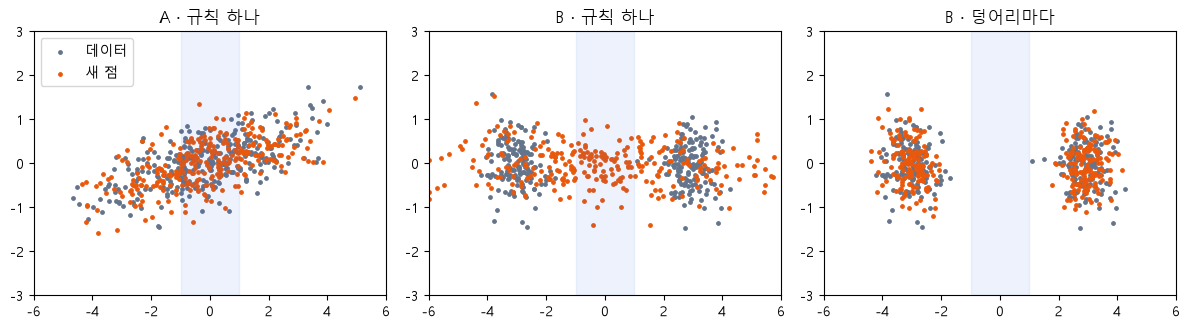

In [5]:
# [수업 재현 D1-1] 진짜 점 · 새 점 그림 (A 한 덩어리 · B 규칙 하나 · B 덩어리마다)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))                          # 그림 3칸
# 칸마다 (진짜, 새 점)
pairs = [(pts_a, new_a, "A · 규칙 하나"), (pts_b, one_rule, "B · 규칙 하나"),
         (pts_b, two_rule, "B · 덩어리마다")]
for a, (real, new, title) in zip(ax, pairs):                             # 세 칸 같은 방식
    a.scatter(real[:, 0], real[:, 1], s=6, c="#64748b", label="데이터")  # 회색 = 데이터
    a.scatter(new[:, 0], new[:, 1], s=6, c="#ea580c", label="새 점")     # 주황 = 새 점
    a.axvspan(-1, 1, color="#2563eb", alpha=0.08)                        # 가운데 빈 띠 표시
    a.set_title(title)                                                   # 칸 제목
    a.set_xlim(-6, 6)                                                    # 같은 가로 범위
    a.set_ylim(-3, 3)                                                    # 같은 세로 범위
ax[0].legend(loc="upper left")                                           # 범례는 첫 칸만
plt.tight_layout()                                                       # 간격 정리
plt.show()                                                               # 그림 표시

**결과** · 예측 정답은 떨어짐 — 26% (데이터는 0%), 덩어리마다 따로 배우면 0%

- `배운 가운데 [-0.09, 0.03]` — 점 무리 A의 평균 위치, 0 근처
- `공분산 (퍼진 모양을 숫자 4개로) [[3.22, 0.61], [0.61, 0.3]]` — 가로 퍼짐 3.22가 세로 0.3보다 훨씬 큼, 0.61 = 오른쪽 위로 기운 모양
- `가운데 빈 띠 비율 · 데이터 0.0 | 규칙 하나 0.26 | 덩어리마다 0.0` — 규칙이 데이터보다 단순하면 그럴듯하지 않은 곳에서도 뽑힘

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">규칙 하나 (평균 · 공분산)</td>
<td style="text-align: left;">가운데 하나 + 퍼진 모양, 계산이 쉬움</td>
<td style="text-align: left;">데이터가 한 덩어리일 때</td>
</tr>
<tr>
<td style="text-align: left;">덩어리마다 규칙</td>
<td style="text-align: left;">덩어리별 평균 · 공분산, 빈 곳을 피함</td>
<td style="text-align: left;">덩어리가 여럿일 때 (혼합 분포)</td>
</tr>
<tr>
<td style="text-align: left;">신경망 생성자</td>
<td style="text-align: left;">노이즈 → 신경망 → 데이터, 규칙을 신경망이 배움</td>
<td style="text-align: left;">사진처럼 규칙을 식으로 못 쓸 때 (2장 GAN)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 수업과 같은 방법이지만 점 무리는 새로 만듦
> - 숫자는 수업(공분산 3.39 · 빈 띠 0.35)과 조금 다름

> ✅ **한 줄 정리** · 생성은 데이터의 규칙을 배워 그 규칙에서 새로 뽑는 것이며, 규칙이 데이터보다 단순하면 빈 곳에도 뽑힌다.

**딥러닝 코드에서는**

- GAN · VAE · Diffusion 모두 '단순한 노이즈(randn) → 변환 → 데이터'라는 같은 틀
- 변환을 cholesky 대신 신경망이 배움

### 1-2. `A` 784칸을 칸마다 따로 뽑으면 · 평균 그림이 흐린 이유 · `pix_mean · pix_std` · `mean(0)` <sub>수업 Day01 D1-1 · D1-3 · GAN 알아보기 PDF 4-1 · 코드 재현</sub>

> 🎯 **숫자 사진 784칸을 칸마다 따로 뽑으면 왜 숫자가 안 되고, 사진을 평균 내면 왜 흐려지는가?**

💡 **쉽게 말하면**

- 칸마다 따로 뽑으면 옆 칸이 무엇을 뽑았는지 모르니 **획이 이어지지 않는 모래**가 됨.
- 사진마다 다른 칸을 평균 내면 **둘 다 아닌 회색**이 남음.
- 칸마다 맞히는 손실(MSE)로 배우면 이 평균 쪽으로 끌려 흐려짐.

**실행 흐름**

1. 데이터 살펴보기(숫자별 사진 수 · 0인 칸 비율)
2. 칸마다 평균 · 표준편차
3. 칸마다 따로 8장 뽑기
4. 이웃한 두 칸의 '한 칸만 밝음' 세기
5. 두 장 평균(3 × 3 작은 예)
6. 숫자별 평균 그림

**먼저 예측** · 이웃한 두 칸 중 한 칸만 밝은 사진은 진짜와 칸마다 따로 뽑은 사진 중 어느 쪽에 많을까? — 답은 코드 실행 결과 아래에

In [6]:
# [수업 재현 D1-1 · D1-3] 숫자 사진 784칸을 칸마다 따로 뽑으면? · 평균 그림은 왜 흐린가
X01 = (X_mnist + 1) / 2                                    # 0 ~ 1 사진 6만 장 (784칸)
print("숫자별 사진 수", torch.bincount(Y_mnist).tolist())  # 심하게 모자란 숫자가 있나
# 대부분 배경
print("값이 0인 칸의 비율 (앞 1000장)", round((X01[:1000] == 0).float().mean().item(), 3))
pix_mean, pix_std = X01.mean(0), X01.std(0)                # 칸마다 가운데 · 퍼짐
gen = torch.Generator().manual_seed(SEED)                  # 뽑기 난수 고정


def pixelwise(n):  # 칸마다 자기 가운데 · 퍼짐만 보고 따로 뽑은 사진 n장
    return (pix_mean + pix_std * torch.randn(n, 784, generator=gen)).clamp(0, 1)  # 0 ~ 1로 자름


indep = pixelwise(8)  # 그림용 8장


# 이웃한 두 칸(14행 13열 · 14행 14열)이 함께 움직이는지
a, b = 14 * 28 + 13, 14 * 28 + 14                          # 펼친 784칸에서의 번호 (0부터)
real2k = X01[torch.randperm(60000, generator=gen)[:2000]]  # 진짜 2000장


def one_bright(x):  # 두 칸 중 한 칸만 밝은(0.5 이상) 사진 수
    return int(((x[:, a] >= 0.5) != (x[:, b] >= 0.5)).sum())  # 밝음 여부가 다르면 1


print("한 칸만 밝은 사진 · 진짜", one_bright(real2k), "장 · 따로 뽑음",  # 두 쪽 비교
      one_bright(pixelwise(2000)), "장 (2000장 중)")


# 두 장을 칸마다 평균 내면 (3 × 3 작은 예): 왼쪽 세로 획 + 오른쪽 세로 획
img_a = torch.tensor([[1.0, 0.0, 0.0]] * 3)                   # 사진 A · 왼쪽 획
img_b = torch.tensor([[0.0, 0.0, 1.0]] * 3)                   # 사진 B · 오른쪽 획
print("A와 B의 칸마다 평균", ((img_a + img_b) / 2).tolist())  # 0.5 = 둘 다 아닌 흐린 그림
digit_mean = torch.stack([X01[Y_mnist == d].mean(0) for d in range(10)])  # 숫자별 평균 사진

숫자별 사진 수 [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]
값이 0인 칸의 비율 (앞 1000장) 0.811


한 칸만 밝은 사진 · 진짜 259 장 · 따로 뽑음 1031 장 (2000장 중)
A와 B의 칸마다 평균 [[0.5, 0.0, 0.5], [0.5, 0.0, 0.5], [0.5, 0.0, 0.5]]


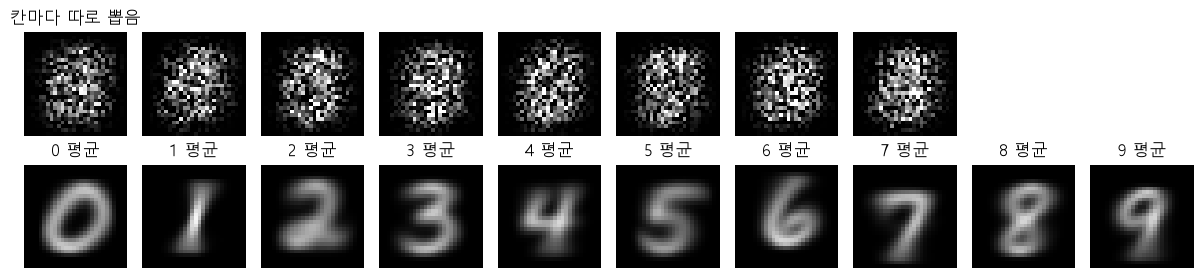

In [7]:
# [수업 재현 D1-1 · D1-3] 칸마다 따로 뽑은 8장 · 숫자별 평균 그림 10장
fig, ax = plt.subplots(2, 10, figsize=(12, 2.8))  # 위 = 따로 뽑음, 아래 = 평균
for k in range(10):                                                           # 칸 10개
    if k < 8:                                                                 # 위 줄은 8장만
        ax[0, k].imshow(indep[k].view(28, 28), cmap="gray", vmin=0, vmax=1)   # 숫자가 아님
    ax[1, k].imshow(digit_mean[k].view(28, 28), cmap="gray", vmin=0, vmax=1)  # 흐린 숫자
    ax[1, k].set_title(f"{k} 평균")                                           # 아래 칸 제목
    ax[0, k].axis("off")                                                      # 축 숨김
    ax[1, k].axis("off")                                                      # 축 숨김
ax[0, 0].set_title("칸마다 따로 뽑음")                                        # 위 줄 제목
plt.tight_layout()                                                            # 간격 정리
plt.show()                                                                    # 그림 표시

**결과** · 예측 정답은 따로 뽑은 쪽 — 1031장 vs 진짜 259장 (진짜는 붙은 칸이 같이 움직임)

- `숫자별 사진 수 [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]` — 가장 적은 5(5421장)도 가장 많은 1(6742장)의 80% → 심한 부족 없음
- `값이 0인 칸의 비율 (앞 1000장) 0.811` — 대부분 배경 0 → 생성자 출력과 진짜 사진의 값 범위를 맞춰야 함 (2-7)
- `한 칸만 밝은 사진 · 진짜 259 장 · 따로 뽑음 1031 장 (2000장 중)` — 진짜는 붙은 두 칸이 같이 밝거나 같이 어두움 → 칸끼리 함께 움직이는 규칙이 필요
- `A와 B의 칸마다 평균 [[0.5, 0.0, 0.5], [0.5, 0.0, 0.5], [0.5, 0.0, 0.5]]` — 왼쪽 획 · 오른쪽 획의 평균 = 양쪽이 반쯤 밝은 흐린 그림

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">칸마다 따로 뽑기</td>
<td style="text-align: left;">칸끼리 관계 없음 → 모래 같은 그림</td>
<td style="text-align: left;">데이터 살펴보기의 기준선</td>
</tr>
<tr>
<td style="text-align: left;">숫자별 평균 그림</td>
<td style="text-align: left;">사진마다 다른 칸이 회색으로 → 흐림</td>
<td style="text-align: left;">데이터 살펴보기 (EDA)</td>
</tr>
<tr>
<td style="text-align: left;">MSE로 다시 그리기 (AE · VAE)</td>
<td style="text-align: left;">여러 정답의 평균 쪽으로 끌림 → 흐림</td>
<td style="text-align: left;">안정적 학습 · 압축 (1-3)</td>
</tr>
<tr>
<td style="text-align: left;">진짜다움으로 판정 (GAN)</td>
<td style="text-align: left;">평균 그림은 진짜에 없어 가짜로 판정 → 또렷함</td>
<td style="text-align: left;">선명한 생성 (2장)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 칸마다 따로 뽑기는 칸끼리의 관계를 버림
> - 숫자 모양은 칸 사이 관계에 있음

> ✅ **한 줄 정리** · 784칸을 칸마다 따로 뽑으면 칸끼리의 관계를 잃어 숫자가 안 되고, 사진마다 다른 칸을 평균 내면 흐린 그림이 된다.

**딥러닝 코드에서는**

- MSE처럼 칸마다 비교하는 손실은 여러 정답의 평균 쪽으로 끌려 흐려짐 → GAN은 손실 기준을 '진짜 같은가'로 바꿈 (GAN 알아보기 PDF 4-1)

### 1-3. `A` AE · VAE 디코더로 숫자 뽑기 · `randn → dec` · `KL` <sub>수업 Day01 D1-2 · 코드 재현</sub>

> 🎯 **오토인코더 디코더에 표준정규 노이즈를 넣으면 숫자가 나오는가? AE와 VAE는 무엇이 다른가?**

💡 **쉽게 말하면**

- AE 디코더는 **자기 인코더가 만든 좌표 자리**만 알아서, 표준정규(가운데 0 · 퍼짐 1) 노이즈를 그대로 넣으면 엉뚱한 그림이 나옴.
- VAE는 좌표를 0 · 1 쪽으로 당기는 손실(KL)을 더해, 노이즈를 그대로 넣어도 대체로 숫자가 나옴.
- 대신 그림이 흐림.

**실행 흐름**

1. 좌표 8칸 AE · VAE를 같은 조건으로 5 epoch 학습
2. 1만 장 좌표의 칸별 가운데 · 퍼짐
3. 같은 노이즈 16개를 두 디코더에
4. AE 좌표 자리로 옮겨 넣기
5. VAE 7에서 2로 보간 11장

**먼저 예측** · AE 좌표의 칸별 퍼짐은 표준정규처럼 1 근처일까? — 답은 코드 실행 결과 아래에

In [8]:
# [수업 재현 D1-2] 좌표 8칸 AE · VAE를 같은 조건(5 epoch)으로 학습
class AE8(nn.Module):  # 인코더 784 → 좌표 8칸 · 디코더 8칸 → 784
    def __init__(self, vae):  # vae=True면 좌표 대신 평균 8 · 로그분산 8
        super().__init__()                                          # nn.Module 준비
        self.vae = vae                                              # 손실에 KL을 더할지
        self.enc = nn.Sequential(nn.Linear(784, 256), nn.ReLU(),    # 인코더
                                 nn.Linear(256, 16 if vae else 8))  # VAE는 16 = 평균 8 + 로그분산 8
        self.dec = nn.Sequential(nn.Linear(8, 256), nn.ReLU(),      # 디코더
                                 nn.Linear(256, 784), nn.Sigmoid())  # 0 ~ 1 사진

    def code(self, x):             # 사진 → 좌표 8칸 (VAE는 평균)
        return self.enc(x)[:, :8]  # AE는 8칸 전부, VAE는 앞 8칸 = 평균

    def forward(self, x):                                                # 다시 그린 사진 · KL
        h = self.enc(x)                                                  # 인코더 출력
        if not self.vae:                                                 # AE
            return self.dec(h), torch.zeros((), device=x.device)         # KL 없음
        mu, logvar = h.chunk(2, dim=1)                                   # 평균 · 로그분산
        z = mu + torch.randn_like(mu) * (0.5 * logvar).exp()             # 평균 근처에서 뽑기
        kl = -0.5 * (1 + logvar - mu ** 2 - logvar.exp()).sum(1).mean()  # 좌표를 0 · 1 쪽으로
        return self.dec(z), kl                                           # 다시 그림 · 당기는 손실


def train_ae(vae, epochs=5):                                     # 같은 seed · 같은 순서로 학습
    set_seed()                                                   # 초기값 고정
    m = AE8(vae).to(device)                                      # 모델
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)              # 옵티마이저
    X = X01.to(device)                                           # 학습 사진
    gen = torch.Generator().manual_seed(SEED)                    # 섞는 순서 고정
    for _ in range(epochs):                                      # epoch 반복
        perm = torch.randperm(len(X), generator=gen).to(device)  # 섞은 번호
        for i in range(0, len(X), 128):                          # 배치 128장
            x = X[perm[i:i + 128]]                               # 이번 배치
            rec, kl = m(x)                                       # 다시 그리기
            loss = F.binary_cross_entropy(rec, x, reduction="sum") / len(x) + kl  # 한 장당 손실
            opt.zero_grad()                                      # 기울기 비우기
            loss.backward()                                      # 기울기 계산
            opt.step()                                           # 갱신
    return m.eval()                                              # 평가 모드로 돌려줌


ae, vae = train_ae(False), train_ae(True)               # 구조 같음 · 손실만 다름
with torch.no_grad():                                   # 측정만
    codes_ae = ae.code(X01[:10000].to(device))          # 학습 사진 1만 장의 AE 좌표
    codes_vae = vae.code(X01[:10000].to(device))        # 같은 1만 장의 VAE 좌표
for name, c in [("AE", codes_ae), ("VAE", codes_vae)]:  # 칸별 가운데 · 퍼짐
    print(f"{name:3} 칸별 가운데", [round(v, 1) for v in c.mean(0).tolist()])  # 표준정규면 0
    print(f"{name:3} 칸별 퍼짐  ", [round(v, 1) for v in c.std(0).tolist()])  # 표준정규면 1

AE  칸별 가운데 [-8.6, 4.3, -1.1, -3.0, -3.0, -4.1, 3.8, 4.7]
AE  칸별 퍼짐   [4.7, 5.3, 5.1, 4.4, 4.9, 4.4, 3.8, 4.8]
VAE 칸별 가운데 [-0.0, -0.3, 0.0, -0.1, 0.1, -0.1, -0.1, -0.1]
VAE 칸별 퍼짐   [1.3, 1.1, 1.1, 1.1, 1.1, 1.1, 1.1, 1.0]


출력 값 범위 0.0 ~ 1.0


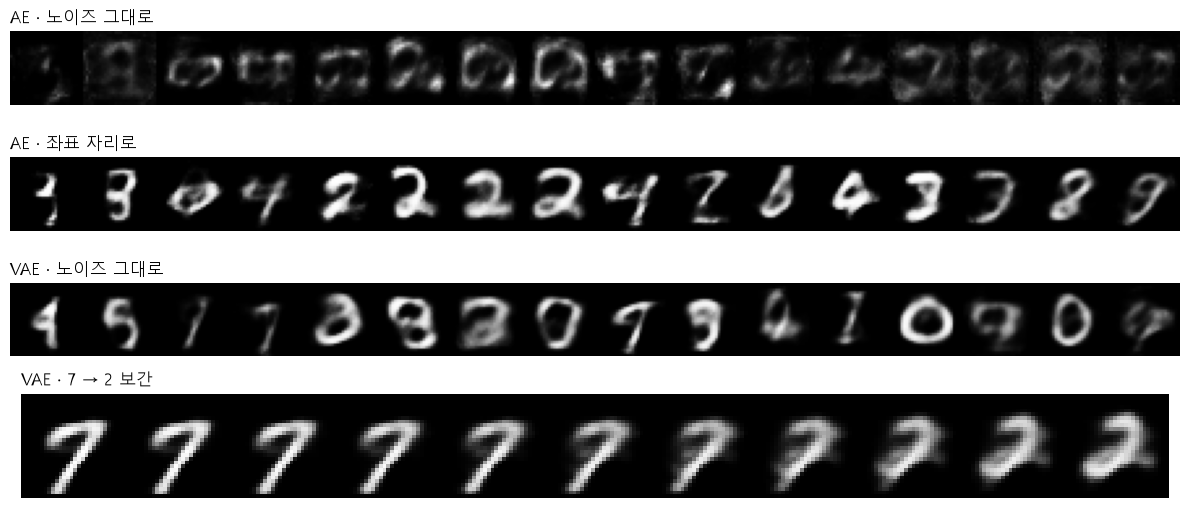

In [9]:
# [수업 재현 D1-2] 같은 노이즈 16개를 두 디코더에 · AE 좌표 자리로 옮겨 넣기 · VAE 보간
gen = torch.Generator().manual_seed(SEED)                      # 노이즈 고정
noise = torch.randn(16, 8, generator=gen).to(device)           # 표준정규 노이즈 8칸 × 16개
moved = codes_ae.mean(0) + codes_ae.std(0) * noise             # AE 좌표가 모인 자리로 옮김
x7, x2 = X01[Y_mnist == 7][:1], X01[Y_mnist == 2][:1]          # 7 사진 · 2 사진 한 장씩
with torch.no_grad():                                          # 생성만
    rows = {"AE · 노이즈 그대로": ae.dec(noise), "AE · 좌표 자리로": ae.dec(moved),  # 줄마다 16장
            "VAE · 노이즈 그대로": vae.dec(noise)}
    z7, z2 = vae.code(x7.to(device)), vae.code(x2.to(device))  # VAE 좌표 (평균)
    t = torch.linspace(0, 1, 11, device=device)[:, None]       # 0.1씩 11단계
    path = vae.dec((1 - t) * z7 + t * z2)                      # 7 → 2를 잇는 11장
print("출력 값 범위", round(rows["VAE · 노이즈 그대로"].min().item(), 1),  # Sigmoid라 0 ~ 1
      "~", round(rows["VAE · 노이즈 그대로"].max().item(), 1))
fig, ax = plt.subplots(4, 1, figsize=(12, 5.2))                # 줄 4개
for a, (title, img) in zip(ax, list(rows.items()) + [("VAE · 7 → 2 보간", path)]):  # 줄마다
    k = len(img)                                               # 16장 또는 11장
    # 가로로 이음
    a.imshow(img.cpu().view(k, 28, 28).permute(1, 0, 2).reshape(28, 28 * k), cmap="gray")
    a.set_title(title, loc="left")                             # 줄 제목
    a.axis("off")                                              # 축 숨김
plt.tight_layout()                                             # 간격 정리
plt.show()                                                     # 그림 표시

**결과** · 예측 정답은 아님 — 3.8 ~ 5.3, 가운데도 -8.6 ~ 4.7로 흩어짐 (VAE는 퍼짐 1.0 ~ 1.3)

- `AE 칸별 가운데 [-8.6, 4.3, -1.1, -3.0, -3.0, -4.1, 3.8, 4.7]` — AE 좌표는 0에서 멀리 떨어진 자리에 모임
- `AE 칸별 퍼짐 [4.7, 5.3, 5.1, 4.4, 4.9, 4.4, 3.8, 4.8]` — 표준정규(퍼짐 1)보다 훨씬 넓음 → randn 그대로는 그 자리에 안 닿음
- `VAE 칸별 가운데 [-0.0, -0.3, 0.0, -0.1, 0.1, -0.1, -0.1, -0.1]` — KL 손실이 좌표를 0 쪽으로 당김
- `VAE 칸별 퍼짐 [1.3, 1.1, 1.1, 1.1, 1.1, 1.1, 1.1, 1.0]` — 퍼짐도 1 근처 → randn을 넣어도 학습한 자리에 닿음
- `출력 값 범위 0.0 ~ 1.0` — 디코더 끝 Sigmoid → 0 ~ 1 사진

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">AE 디코더</td>
<td style="text-align: left;">좌표가 0에서 먼 곳에 흩어짐, randn 그대로는 엉뚱한 그림</td>
<td style="text-align: left;">좌표 자리로 옮기면 생성 가능 · 복원 · 압축</td>
</tr>
<tr>
<td style="text-align: left;">VAE 디코더</td>
<td style="text-align: left;">KL로 좌표를 표준정규 쪽으로 당김, randn 그대로 숫자</td>
<td style="text-align: left;">생성 · 보간, 대신 흐림</td>
</tr>
<tr>
<td style="text-align: left;">보간</td>
<td style="text-align: left;">두 좌표 사이를 0.1씩 이어 디코더에</td>
<td style="text-align: left;">좌표 공간이 매끈한지 확인</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 수업은 AE 둘째 날 저장 모델을 씀
> - 여기는 같은 구조를 새로 5 epoch 학습 → 그림 · 숫자가 수업과 조금 다름

> ✅ **한 줄 정리** · AE 디코더는 자기 좌표 자리에서만 숫자를 그려 노이즈를 그 자리로 옮겨야 하고, VAE는 노이즈를 그대로 넣어도 되지만 흐리다.

**딥러닝 코드에서는**

- AE · VAE 구조와 손실의 자세한 설명은 오토인코더-1 · 2
- 이 권은 '노이즈 → 디코더 = 생성'만 사용

---
## 2. GAN 기본

**GAN 파트 · 1 / 3 · 수업 Day01 D1-4 ~ D1-6 + 보강**

> **이 장의 흐름**
>
> - 1장 VAE는 숫자를 만들지만 흐렸다(칸마다 비교하는 손실 → 평균 쪽으로)
> - 손실 기준을 '진짜 같은가'로 바꿈.
> - 진짜다움을 재는 판별자와 경쟁시켜 생성자를 학습.

**파이프라인 위치** · 생성 모델 학습 흐름 — 노이즈 → 생성자 → 판별자 → 두 손실 번갈아 갱신

### 2-1. `A` 생성자와 판별자의 역할 · `G(z)` · `D(x)` <sub>개념 위클리 9 Q3 · 코드 보강</sub>

> 🎯 **GAN의 생성자와 판별자는 각각 무엇을 입력받아 무엇을 내는가?**

💡 **쉽게 말하면**

- 생성자는 **위조지폐범**, 판별자는 **감별사**.
- 위조범은 진짜 지폐를 직접 본 적 없이 감별사의 반응만 보고 실력을 키우고, 감별사는 진짜와 위조를 둘 다 보며 가려내는 법을 배움.

**실행 흐름**

1. 봉우리 3개 1차원 진짜 데이터
2. 작은 G · D 만들기 · z
3. G(z)
4. D 점수 모양
5. 학습 전 진짜일 확률
6. 파라미터 수

**먼저 예측** · 학습 전 판별자가 진짜 · 가짜에 내는 "진짜일 확률"은 1과 0에 가까울까? — 답은 코드 실행 결과 아래에

In [10]:
# [보강] 진짜 데이터: -3 · 0 · 3 중심 봉우리 3개 (표준편차 0.3)
MODES_1D = torch.tensor([-3.0, 0.0, 3.0])  # 봉우리 중심 3개


def real_1d(n, gen):                                                     # 진짜 데이터 n개 뽑기
    k = torch.randint(0, 3, (n,), generator=gen)                         # 봉우리 고르기
    return (MODES_1D[k] + 0.3 * torch.randn(n, generator=gen))[:, None]  # (n, 1)


# 생성자 G: 잠재 벡터 z(4개 숫자) → 가짜 값 1개
# 판별자 D: 값 1개 → 진짜일 점수(로짓) 1개
Z1 = 4                                                     # 잠재 벡터 길이
set_seed()                                                 # 가중치 초기값 고정
G1 = mlp(Z1, 1, nn.Tanh())                                 # 생성자 (z 4개 → 값 1개)
D1 = mlp(1, 1, nn.LeakyReLU(0.2))                          # 판별자 (값 1개 → 로짓 1개)
gen = torch.Generator().manual_seed(SEED)                  # 데이터 · z 전용 난수 생성기
z = torch.randn(8, Z1, generator=gen)                      # 정규분포에서 뽑은 잠재 벡터
real, fake = real_1d(8, gen), G1(z)                        # 진짜 8개 · 가짜 8개
print("z:", tuple(z.shape), "→ G(z):", tuple(fake.shape),  # 생성자 입출력 모양
      "| 진짜:", tuple(real.shape))
print("D(진짜):", tuple(D1(real).shape), "| D(가짜):", tuple(D1(fake).shape))  # 점수 1개씩


# 학습 전: 판별자는 아직 구분 못 함 → 확률 0.5 근처
with torch.no_grad():                                            # 확인만 하므로 기울기 기록 끔
    print("학습 전 진짜일 확률 · 진짜:",                         # sigmoid로 로짓 → 확률
          round(torch.sigmoid(D1(real)).mean().item(), 4),
          "| 가짜:", round(torch.sigmoid(D1(fake)).mean().item(), 4))
print("파라미터 · G:", sum(p.numel() for p in G1.parameters()),  # 학습할 숫자 개수
      "| D:", sum(p.numel() for p in D1.parameters()))

z: (8, 4) → G(z): (8, 1) | 진짜: (8, 1)
D(진짜): (8, 1) | D(가짜): (8, 1)
학습 전 진짜일 확률 · 진짜: 0.4101 | 가짜: 0.4471
파라미터 · G: 1249 | D: 1153


**결과** · 예측 정답은 아님 — 둘 다 0.4 ~ 0.45 근처, 아직 아무것도 구분 못 함

- `z: (8, 4) → G(z): (8, 1) | 진짜: (8, 1)` — 생성자 출력은 진짜 데이터와 같은 모양이어야 판별자에 넣을 수 있음
- `D(진짜): (8, 1) | D(가짜): (8, 1)` — 판별자는 샘플마다 점수(로짓) 1개 = 이진 분류기
- `학습 전 진짜일 확률 · 진짜: 0.4101 | 가짜: 0.4471` — 무작위 가중치 → 진짜 · 가짜를 구분하지 못함
- `파라미터 · G: 1249 | D: 1153` — G 4 × 32 + 32 + 32 × 32 + 32 + 32 + 1 = 1249, D 32 + 32 + 32 × 32 + 32 + 32 + 1 = 1153

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">생성자 G</td>
<td style="text-align: left;">z → 가짜 데이터, 진짜를 <strong>직접 보지 않고</strong> D를 거친 기울기로만 배움</td>
<td style="text-align: left;">학습 후 생성에 쓰는 쪽</td>
</tr>
<tr>
<td style="text-align: left;">판별자 D</td>
<td style="text-align: left;">데이터 → 진짜일 점수(로짓), 진짜 · 가짜를 모두 봄 (이진 분류기)</td>
<td style="text-align: left;">학습 중 G의 선생님, 학습 후 보통 버림</td>
</tr>
<tr>
<td style="text-align: left;">잠재 벡터 z</td>
<td style="text-align: left;">정규분포에서 뽑은 숫자 묶음, 다른 z → 다른 출력이어야 정상</td>
<td style="text-align: left;">생성 다양성의 출발점 (오토인코더-1 · 2의 잠재 공간 참조)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 판별자 마지막에 `sigmoid`를 넣고 `BCEWithLogitsLoss`까지 쓰면 sigmoid가 두 번
> - 판별자는 로짓을 내고 손실이 sigmoid를 맡게 함

> ✅ **한 줄 정리** · 생성자는 잠재 벡터 z를 받아 데이터와 같은 모양의 가짜를 만들고, 판별자는 데이터를 받아 진짜일 점수 하나를 내는 이진 분류기다.

**딥러닝 코드에서는**

- 학습이 끝나면 생성에는 생성자만 씀
- `G(torch.randn(n, z_dim))`, 판별자는 버림 (잠재 공간의 의미는 오토인코더-1 · 2 참조)

### 2-2. `A` 판별자 · sigmoid · BCE · `nn.LeakyReLU(0.2)` · `BCEWithLogitsLoss` <sub>수업 Day01 D1-4 · 코드 재현</sub>

> 🎯 **판별자는 사진을 받아 무엇을 내며, 어떤 손실로 진짜 · 가짜를 가리도록 배우는가?**

💡 **쉽게 말하면**

- 판별자는 사진 한 장에 **진짜다움 값 하나**를 매기는 분류기.
- sigmoid로 0 ~ 1 점수로 바꾸고, 틀린 판정일수록 크게 벌주는 BCE로 배움.
- 무작위 사진은 너무 쉬운 가짜라 30번 만에 가려냄.

**실행 흐름**

1. ReLU vs LeakyReLU
2. 판별자 만들기(Linear 세 층)
3. 학습 전 점수
4. BCE 값 네 가지
5. 올바른 짝 두 가지와 잘못된 짝
6. D_demo 30번 학습
7. 학습에 안 쓴 사진으로 평가

**먼저 예측** · 학습 전 판별자는 진짜 사진과 무작위 사진에 서로 다른 점수를 줄까? — 답은 코드 실행 결과 아래에

In [11]:
# [수업 재현 D1-4] 판별자: 사진 784칸 → 값 하나 (Linear 세 층 · LeakyReLU)
def make_D():  # 2-4 GAN 첫 학습 · 5장에서도 같은 구조
    return nn.Sequential(nn.Linear(784, 512), nn.LeakyReLU(0.2),  # 784 → 512
                         nn.Linear(512, 256), nn.LeakyReLU(0.2),  # 512 → 256
                         nn.Linear(256, 1))                       # 256 → 값 하나 (로짓)


v = torch.tensor([-2.0, -0.5, 0.0, 1.0, 3.0])                 # 음수 · 0 · 양수
print(f"{'입력':10}", v.tolist())                             # 원래 값
print(f"{'ReLU':10}", nn.ReLU()(v).tolist())                  # 음수 → 0
print(f"{'LeakyReLU':10}", [round(x, 1) for x in nn.LeakyReLU(0.2)(v).tolist()])  # 음수 × 0.2
set_seed()                                                    # 판별자 초기값 고정
D = make_D()                                                  # 아직 학습 안 한 판별자
print("입력 모양", tuple(X01[:8].shape), "→ 출력 모양", tuple(D(X01[:8]).shape))  # 사진마다 값 하나
g_rand = torch.Generator().manual_seed(SEED)                  # 무작위 사진 난수 고정
real4, rand4 = X01[:4], torch.rand(4, 784, generator=g_rand)  # 진짜 4장 · 무작위(칸마다 0 ~ 1) 4장
with torch.no_grad():                                         # 확인만
    for name, x in [("진짜", real4), ("가짜", rand4)]:        # 두 묶음
        for k, s in enumerate(D(x)[:, 0].tolist()):           # 장마다
            # 0.5 근처
            print(f"{name} {k + 1} · 값 {s:.3f} · 점수 {torch.sigmoid(torch.tensor(s)):.3f}")


# BCE: 틀린 판정일수록 손실이 빠르게 커짐
for y, p in [(1, 0.9), (1, 0.1), (0, 0.1), (0, 0.9)]:                           # (정답, 점수)
    loss = F.binary_cross_entropy(torch.tensor([p]), torch.tensor([float(y)]))  # 점수를 넣는 BCE
    # 0.105 vs 2.303
    print(f"정답 {'진짜' if y else '가짜'} ({y}) · 점수 {p} → 손실 {loss.item():.3f}")


# 올바른 짝 두 가지 · 섞으면 sigmoid가 두 번 (에러 없이 다른 값)
logit, ones4 = D(real4), torch.ones(4, 1)      # 값(로짓) · 정답 진짜
print(f"{'값 → BCEWithLogitsLoss':26} {nn.BCEWithLogitsLoss()(logit, ones4).item():.4f}")  # 짝 ①
print(f"{'점수 → BCELoss':26} {nn.BCELoss()(torch.sigmoid(logit), ones4).item():.4f}")  # 짝 ②
print(f"{'점수 → BCEWithLogitsLoss (X)':26}",  # 잘못된 짝
      f"{nn.BCEWithLogitsLoss()(torch.sigmoid(logit), ones4).item():.4f}")

입력         [-2.0, -0.5, 0.0, 1.0, 3.0]
ReLU       [0.0, 0.0, 0.0, 1.0, 3.0]
LeakyReLU  [-0.4, -0.1, 0.0, 1.0, 3.0]
입력 모양 (8, 784) → 출력 모양 (8, 1)
진짜 1 · 값 0.020 · 점수 0.505
진짜 2 · 값 0.013 · 점수 0.503
진짜 3 · 값 0.051 · 점수 0.513
진짜 4 · 값 -0.024 · 점수 0.494
가짜 1 · 값 0.041 · 점수 0.510
가짜 2 · 값 -0.008 · 점수 0.498
가짜 3 · 값 -0.009 · 점수 0.498
가짜 4 · 값 0.091 · 점수 0.523
정답 진짜 (1) · 점수 0.9 → 손실 0.105
정답 진짜 (1) · 점수 0.1 → 손실 2.303
정답 가짜 (0) · 점수 0.1 → 손실 0.105
정답 가짜 (0) · 점수 0.9 → 손실 2.303
값 → BCEWithLogitsLoss      0.6857
점수 → BCELoss               0.6857
점수 → BCEWithLogitsLoss (X) 0.4727


In [12]:
# [수업 재현 D1-4] 시연용 판별자 D_demo: 진짜 vs 무작위 사진을 30번 고치기
set_seed()                                                       # 초기값 고정
D_demo = make_D().to(device)                                     # 위 판별자와 같은 구조 · 새로 만듦
opt = torch.optim.Adam(D_demo.parameters(), lr=2e-4, betas=(0.5, 0.999))  # 학습률 0.0002
g_demo = torch.Generator().manual_seed(SEED)                     # 배치 · 무작위 사진 고정
X, one = X01.to(device), torch.ones(128, 1, device=device)       # 학습 사진 · 정답 진짜
for step in range(1, 31):                                        # 30번 고치기
    real = X[torch.randint(0, len(X), (128,), generator=g_demo).to(device)]  # 진짜 128장
    noise = torch.rand(128, 784, generator=g_demo).to(device)    # 무작위 128장
    loss = bce(D_demo(real), one) + bce(D_demo(noise), 0 * one)  # 진짜 1 · 가짜 0
    opt.zero_grad()                                              # 기울기 비우기
    loss.backward()                                              # 기울기 계산
    opt.step()                                                   # 판별자 갱신
    if step in (1, 30):                                          # 처음 · 마지막
        with torch.no_grad():                                    # 학습에 안 쓴 사진으로 평가
            s_real = torch.sigmoid(D_demo(X_test01[:500].to(device))).mean().item()  # 시험 진짜
            new = torch.rand(500, 784, generator=g_demo).to(device)  # 새 무작위
            s_rand = torch.sigmoid(D_demo(new)).mean().item()    # 새 무작위 점수
        print(f"{step}번째 · 손실 {loss.item():.3f} · 시험 진짜 점수 {s_real:.3f}"  # 둘이 벌어짐
              f" · 새 무작위 점수 {s_rand:.3f}")
with torch.no_grad():                                            # 점수 0.5 기준으로 맞힌 비율
    acc_r = (D_demo(X_test01[:500].to(device)) > 0).float().mean().item()  # 로짓 > 0 = 점수 > 0.5
    acc_f = (D_demo(new) < 0).float().mean().item()              # 가짜는 0.5 미만이어야 맞힘
print("점수 0.5 기준 맞힌 비율 · 시험 진짜", acc_r, "· 새 무작위", acc_f)  # 너무 쉬운 가짜

1번째 · 손실 1.400 · 시험 진짜 점수 0.498 · 새 무작위 점수 0.453
30번째 · 손실 0.041 · 시험 진짜 점수 0.965 · 새 무작위 점수 0.006
점수 0.5 기준 맞힌 비율 · 시험 진짜 1.0 · 새 무작위 1.0


**결과** · 예측 정답은 아님 — 둘 다 0.49 ~ 0.52, 아직 구분 못 함

- `LeakyReLU [-0.4, -0.1, 0.0, 1.0, 3.0]` — 음수를 0.2배로 남김 (ReLU는 0) → 음수 쪽 기울기도 흐름
- `입력 모양 (8, 784) → 출력 모양 (8, 1)` — 사진마다 값 하나
- `진짜 1 · 값 0.020 · 점수 0.505` — 학습 전에는 진짜 · 가짜 모두 점수 0.5 근처
- `정답 진짜 (1) · 점수 0.1 → 손실 2.303` — 진짜를 가짜 쪽으로 틀리면 손실이 큼 (점수 0.9면 0.105)
- `점수 → BCEWithLogitsLoss (X) 0.4727` — sigmoid를 두 번 → 에러 없이 다른 값 (올바른 두 짝은 0.6857)
- `30번째 · 손실 0.041 · 시험 진짜 점수 0.965 · 새 무작위 점수 0.006` — 30번 만에 진짜와 무작위의 점수가 크게 벌어짐
- `점수 0.5 기준 맞힌 비율 · 시험 진짜 1.0 · 새 무작위 1.0` — 무작위 사진은 너무 쉬운 가짜 → 진짜 같은 가짜를 만드는 쪽(생성자)이 필요

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">ReLU</td>
<td style="text-align: left;">음수 → 0</td>
<td style="text-align: left;">생성자 · 분류기 은닉층 기본</td>
</tr>
<tr>
<td style="text-align: left;">LeakyReLU(0.2)</td>
<td style="text-align: left;">음수 → 0.2배</td>
<td style="text-align: left;">GAN 판별자 관례 (음수 쪽 기울기 유지)</td>
</tr>
<tr>
<td style="text-align: left;">로짓 + BCEWithLogitsLoss</td>
<td style="text-align: left;">sigmoid를 손실 안에서 계산, 수치 안정</td>
<td style="text-align: left;">판별자 기본 짝 ①</td>
</tr>
<tr>
<td style="text-align: left;">점수(sigmoid) + BCELoss</td>
<td style="text-align: left;">sigmoid를 모델 끝에서 계산</td>
<td style="text-align: left;">짝 ② · 두 짝을 섞으면 sigmoid 두 번</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 판별자 끝에 sigmoid를 넣고 BCEWithLogitsLoss까지 쓰면 sigmoid가 두 번
> - 에러 없이 틀린 값

> ✅ **한 줄 정리** · 판별자는 사진을 값 하나(로짓)로 바꾸는 이진 분류기이며, 진짜 1 · 가짜 0으로 BCE를 줄이도록 배우고 손실 함수와 짝을 맞춘다.

**딥러닝 코드에서는**

- 보통 판별자는 sigmoid 없이 로짓을 내고 BCEWithLogitsLoss를 씀 (수치가 더 안정적)

### 2-3. `A` 학습 한 단계와 두 손실 · `detach()` · `-log D(G(z))` <sub>개념 위클리 9 Q3 · 코드 보강</sub>

> 🎯 **판별자와 생성자는 한 단계에서 어떤 순서 · 손실로 갱신되며, 생성자 손실은 왜 원래 식 대신 -log D(G(z))를 쓰는가?**

💡 **쉽게 말하면**

- 감별사 시험(판별자 갱신) → 위조범 연습(생성자 갱신)을 번갈아 함.
- 감별사를 가르칠 때 위조범은 **잠시 멈춰 두고(detach)**, 위조범은 감별사가 **"진짜"라고 하도록** 배움.

<img src="images/gen1_gan_step.png" alt="GAN 학습 한 단계: 판별자 갱신 → 생성자 갱신" width="800">

**실행 흐름**

1. 옵티마이저 2개
2. 판별자 손실(진짜 1 · 가짜 0, detach)
3. 생성자 손실(가짜를 1로)
4. 균형점 기준값
5. 원래 식 vs non-saturating 기울기 크기

**먼저 예측** · 가짜가 쉽게 들키는 학습 초반(D(G(z)) = 0.01)에 원래 식의 기울기는 클까? — 답은 코드 실행 결과 아래에

In [13]:
# [보강] 학습 한 단계: ① 판별자 갱신 → ② 생성자 갱신
opt_g = torch.optim.Adam(G1.parameters(), lr=2e-3, betas=(0.5, 0.999))  # 생성자 전용
opt_d = torch.optim.Adam(D1.parameters(), lr=2e-3, betas=(0.5, 0.999))  # 판별자 전용
ones, zeros = torch.ones(64, 1), torch.zeros(64, 1)                     # 정답: 진짜 1 · 가짜 0
real = real_1d(64, gen)                                                 # 진짜 배치
fake = G1(torch.randn(64, Z1, generator=gen))  # 가짜 배치 (z는 배치마다 새로)


# ① 판별자: 진짜 → 1, 가짜 → 0 (가짜는 detach로 G와 끊음)
d_loss = bce(D1(real), ones) + bce(D1(fake.detach()), zeros)  # 두 BCE의 합
opt_d.zero_grad()                                             # 지난 기울기 지우기
d_loss.backward()                                             # 판별자 기울기 계산
print("D 갱신 때 G 기울기 없음:", G1[0].weight.grad is None)  # detach 효과
opt_d.step()                                                  # 판별자만 갱신


# ② 생성자: D가 가짜를 1(진짜)이라고 하도록 → D를 거친 기울기로만 배움
g_loss = bce(D1(fake), ones)                                       # = 평균 -log D(G(z))
opt_g.zero_grad()                                                  # 생성자 기울기 비우기
g_loss.backward()                                                  # D를 거쳐 G까지 기울기
opt_g.step()                                                       # 생성자만 갱신
print(f"d_loss {d_loss.item():.4f} | g_loss {g_loss.item():.4f}")  # 첫 단계 손실
print(f"균형점 기준값 · d_loss 2·ln2 = {2 * np.log(2):.4f}"        # D가 0.5만 낼 때
      f" | g_loss ln2 = {np.log(2):.4f}")


# 생성자 손실 두 가지: 가짜가 쉽게 들킬 때(p 작음) 기울기 크기
for p in [0.01, 0.1, 0.5, 0.9]:                            # p = D(G(z)) 진짜일 확률
    s = torch.logit(torch.tensor(p)).requires_grad_()      # 확률 → 로짓, 기울기 추적
    torch.log(1 - torch.sigmoid(s)).backward()             # 원래 식 (줄이기)
    g_orig, s.grad = s.grad.abs().item(), None             # 크기 저장 후 기울기 비움
    (-torch.log(torch.sigmoid(s))).backward()              # non-saturating
    print(f"D(G(z))={p:<4} | 원래 식 기울기 {g_orig:.2f}"  # 두 기울기 나란히
          f" | non-saturating 기울기 {s.grad.abs().item():.2f}")

D 갱신 때 G 기울기 없음: True
d_loss 1.4708 | g_loss 0.7866
균형점 기준값 · d_loss 2·ln2 = 1.3863 | g_loss ln2 = 0.6931
D(G(z))=0.01 | 원래 식 기울기 0.01 | non-saturating 기울기 0.99
D(G(z))=0.1  | 원래 식 기울기 0.10 | non-saturating 기울기 0.90
D(G(z))=0.5  | 원래 식 기울기 0.50 | non-saturating 기울기 0.50
D(G(z))=0.9  | 원래 식 기울기 0.90 | non-saturating 기울기 0.10


**결과** · 예측 정답은 아님 — 0.01로 거의 0, non-saturating은 0.99로 강한 신호

- `D 갱신 때 G 기울기 없음: True` — `fake.detach()` → 판별자 손실이 생성자까지 거슬러 가지 않음
- `d_loss 1.4708 | g_loss 0.7866` — 첫 단계, 아직 균형점 근처의 무작위 상태
- `균형점 기준값 · d_loss 2·ln2 = 1.3863 | g_loss ln2 = 0.6931` — D가 어디서나 0.5를 낼 때의 손실 (이론상 끝 상태)
- `D(G(z))=0.01 | 원래 식 기울기 0.01 | non-saturating 기울기 0.99` — 원래 식은 들킬수록 기울기가 사라짐 (포화)
- `D(G(z))=0.9  | 원래 식 기울기 0.90 | non-saturating 기울기 0.10` — 속이는 데 성공하면 반대로 작아짐

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">판별자 손실</td>
<td style="text-align: left;">bce(D(진짜), 1) + bce(D(가짜.detach()), 0), 균형점 2·ln2 ≈ 1.386</td>
<td style="text-align: left;">D 갱신, 가짜는 detach로 G와 끊음</td>
</tr>
<tr>
<td style="text-align: left;">생성자 손실 (non-saturating)</td>
<td style="text-align: left;">bce(D(가짜), 1) = -log D(G(z)), 균형점 ln2 ≈ 0.693</td>
<td style="text-align: left;">실제로 쓰는 생성자 손실 (기본 선택)</td>
</tr>
<tr>
<td style="text-align: left;">생성자 손실 (원래 식)</td>
<td style="text-align: left;">log(1 - D(G(z)))를 줄임, 가짜가 쉽게 들키는 초반에 기울기 ≈ 0</td>
<td style="text-align: left;">이론 설명용, 실제로는 안 씀</td>
</tr>
<tr>
<td style="text-align: left;">손실 값 자체</td>
<td style="text-align: left;">두 손실은 서로 상대적 → 낮다고 품질이 좋은 것이 아님</td>
<td style="text-align: left;">품질은 생성 샘플 · FID 등 따로 확인</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 생성자를 갱신할 때 판별자 옵티마이저까지 `step()`하면 판별자가 "속는 쪽"으로 학습됨
> - 생성자 단계에서는 `opt_g.step()`만

> ✅ **한 줄 정리** · 판별자는 진짜 1 · 가짜 0(detach)으로, 생성자는 가짜를 1로 번갈아 갱신하고, 생성자 손실은 초반에도 기울기가 큰 -log D(G(z))를 쓴다.

**딥러닝 코드에서는**

- `d_loss = bce(D(real), 1) + bce(D(fake.detach()), 0)` → `g_loss = bce(D(fake), 1)`
- DCGAN · StyleGAN 학습 루프의 뼈대

### 2-4. `A` GAN 첫 학습 (MNIST · MLP) · `train_gan` · `FIXED` <sub>수업 Day01 GAN 첫 학습 · GAN 알아보기 PDF 4-3 · 코드 재현</sub>

> 🎯 **MLP 생성자 · 판별자를 번갈아 학습하면 같은 노이즈의 그림은 어떻게 바뀌고, 손실 숫자로 그 변화를 읽을 수 있는가?**

💡 **쉽게 말하면**

- 생성자는 노이즈 64개를 784칸 사진으로 펴는 신경망.
- 묶음마다 판별자 → 생성자 두 차례로 고치며, **같은 고정 노이즈 16개**의 그림을 epoch마다 찍어 변화를 봄.
- 손실이 오르내리는 것과 그림이 좋아지는 것은 따로 움직임.

**실행 흐름**

1. 진짜 사진은 -1 ~ 1 (0장)
2. 생성자(Linear 세 층 · 끝 Tanh)
3. 번갈아 학습 함수 train_gan
4. 고정 노이즈 16개
5. 20 epoch 학습
6. epoch별 손실 · 점수 · 그림

**먼저 예측** · 생성자 손실이 큰 epoch 10 무렵에 그림이 가장 나쁠까? — 답은 코드 실행 결과 아래에

In [14]:
# [수업 재현 Day1 GAN 첫 학습] MLP 생성자 · 판별자를 번갈아 20 epoch
ZD = 64  # 노이즈(잠재 벡터) 길이


def make_G():  # 노이즈 64 → 사진 784칸 (끝 Tanh = -1 ~ 1)
    return nn.Sequential(nn.Linear(ZD, 256), nn.LeakyReLU(0.2),   # 64 → 256
                         nn.Linear(256, 512), nn.LeakyReLU(0.2),  # 256 → 512
                         nn.Linear(512, 784), nn.Tanh())          # 512 → 784, 진짜 범위와 맞춤


def train_gan(G, D, X, epochs, lr_d=2e-4, keep=()):  # 한 묶음마다 판별자 → 생성자
    G, D = G.to(device), D.to(device)                                   # GPU가 있으면 GPU로
    og = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))  # oG: G만 고침
    od = torch.optim.Adam(D.parameters(), lr=lr_d, betas=(0.5, 0.999))  # oD: D만 고침
    gen = torch.Generator().manual_seed(SEED)                           # 섞기 · 노이즈 고정
    X, B = X.to(device), 128                                            # 데이터 · 묶음 크기
    one = torch.ones(B, 1, device=device)                               # 진짜 정답
    log = {"d": [], "g": [], "s_real": [], "s_fake": [], "grid": {}}    # epoch별 기록
    with torch.no_grad():                                               # 학습 전 그림
        log["grid"][0] = G(FIXED).cpu()                                 # 0 epoch
    for epoch in range(1, epochs + 1):                                  # epoch = 학습 사진 한 바퀴
        perm = torch.randperm(len(X), generator=gen).to(device)         # 섞은 번호
        sums = torch.zeros(4)                                           # 손실 2개 · 점수 2개 합계
        for i in range(0, len(X) - B + 1, B):  # 꽉 찬 묶음 468개 (마지막 96장 빠짐)
            real = X[perm[i:i + B]]                                     # 진짜 묶음
            fake = G(torch.randn(B, ZD, generator=gen).to(device))      # 노이즈는 묶음마다 새로
            out_r, out_f = D(real), D(fake.detach())                    # 판별자 차례: 가짜는 detach
            d_loss = bce(out_r, one) + bce(out_f, 0 * one)              # 진짜 1 · 가짜 0
            od.zero_grad()                                              # 쌓인 기울기 비우기
            d_loss.backward()                                           # 기울기 계산
            od.step()                                                   # D만 고침
            g_loss = bce(D(fake), one)  # 생성자 차례: 같은 fake · 정답 1
            og.zero_grad()                                              # 쌓인 기울기 비우기
            g_loss.backward()                                           # D를 지나 G까지
            og.step()                                                   # G만 고침
            s_r, s_f = torch.sigmoid(out_r).mean(), torch.sigmoid(out_f).mean()  # 점수 평균
            # 묶음 값 더하기
            sums += torch.tensor([d_loss.item(), g_loss.item(), s_r.item(), s_f.item()])
        for k, v in zip(["d", "g", "s_real", "s_fake"], sums / (len(X) // B)):  # 묶음 평균
            log[k].append(v.item())                                     # epoch 평균 저장
        if epoch in keep:                                               # 그림을 남길 epoch
            with torch.no_grad():                                       # 그림만
                log["grid"][epoch] = G(FIXED).cpu()                     # 같은 고정 노이즈 16개
    return G, log                                                       # 학습된 생성자 · 기록


fixed_gen = torch.Generator().manual_seed(SEED)                       # 고정 노이즈 전용 난수
FIXED = torch.randn(16, ZD, generator=fixed_gen).to(device)           # 확인용 고정 노이즈 16개
set_seed()                                                            # 초기값 고정
G_mlp, log_mlp = train_gan(make_G(), make_D(), X_mnist, 20, keep=(1, 2, 3, 5, 10, 20))  # 20 epoch
for e in (1, 5, 10, 20):                                              # 수업 표와 같은 epoch
    d, g, sr, sf = (log_mlp[k][e - 1] for k in ("d", "g", "s_real", "s_fake"))  # 그 epoch 값 네 개
    print(f"epoch {e:2} · 판별자 손실 {d:.3f} · 생성자 손실 {g:.3f}"  # 두 손실
          f" · 진짜 점수 평균 {sr:.2f} · 가짜 점수 평균 {sf:.2f}")

epoch  1 · 판별자 손실 0.894 · 생성자 손실 1.426 · 진짜 점수 평균 0.77 · 가짜 점수 평균 0.43
epoch  5 · 판별자 손실 0.591 · 생성자 손실 2.596 · 진짜 점수 평균 0.81 · 가짜 점수 평균 0.21
epoch 10 · 판별자 손실 0.523 · 생성자 손실 2.889 · 진짜 점수 평균 0.84 · 가짜 점수 평균 0.16
epoch 20 · 판별자 손실 0.961 · 생성자 손실 1.472 · 진짜 점수 평균 0.68 · 가짜 점수 평균 0.33


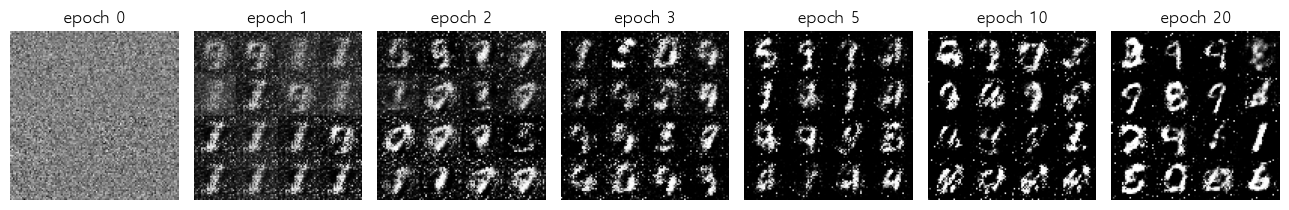

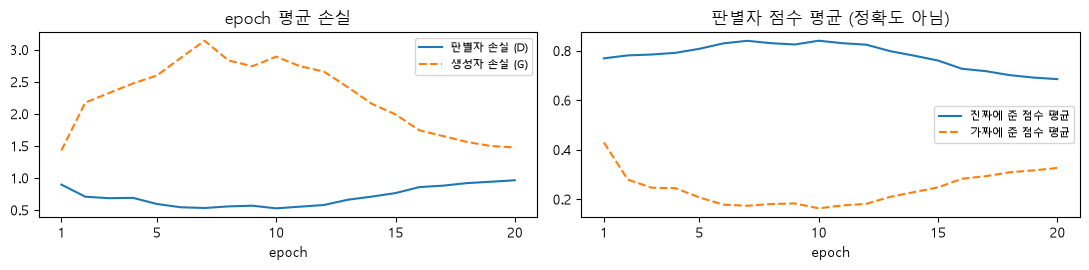

In [15]:
# [수업 재현 Day1 GAN 첫 학습] 같은 고정 노이즈 16개의 그림 · 손실 곡선
def tile(g):  # 16장 (16, 784 또는 1, 28, 28) → 4 × 4 격자 한 장
    # 0 ~ 1
    return ((g.view(4, 4, 28, 28).permute(0, 2, 1, 3).reshape(112, 112) + 1) / 2).clamp(0, 1)


fig, ax = plt.subplots(1, 7, figsize=(13, 2.4))     # 0 · 1 · 2 · 3 · 5 · 10 · 20 epoch
for a, (e, g) in zip(ax, log_mlp["grid"].items()):  # 남긴 epoch 순서대로
    a.imshow(tile(g), cmap="gray")                  # 격자 그림
    a.set_title(f"epoch {e}")                       # 칸 제목
    a.axis("off")                                   # 축 숨김
plt.tight_layout()                                  # 간격 정리
plt.show()                                          # 그림 표시

fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))                              # 손실 · 점수 곡선
ep = range(1, 21)                                                            # x축 epoch
ax[0].plot(ep, log_mlp["d"], label="판별자 손실 (D)")                        # D 손실
ax[0].plot(ep, log_mlp["g"], "--", label="생성자 손실 (G)")                  # G 손실
ax[1].plot(ep, log_mlp["s_real"], label="진짜에 준 점수 평균")               # 진짜 점수
ax[1].plot(ep, log_mlp["s_fake"], "--", label="가짜에 준 점수 평균")         # 가짜 점수
for a, t in zip(ax, ["epoch 평균 손실", "판별자 점수 평균 (정확도 아님)"]):  # 두 칸 공통
    a.set_title(t)                                                           # 칸 제목
    a.set_xlabel("epoch")                                                    # x축 이름
    a.set_xticks([1, 5, 10, 15, 20])                                         # epoch는 정수 눈금
    a.legend(fontsize=8)                                                     # 범례
plt.tight_layout()                                                           # 간격 정리
plt.show()                                                                   # 그림 표시

**결과** · 예측 정답은 아님 — epoch 10 그림은 이미 숫자 모양, 손실 숫자는 그림 품질을 그대로 보여 주지 않음

- `epoch 1 · 판별자 손실 0.894 · 생성자 손실 1.426 · 진짜 점수 평균 0.77 · 가짜 점수 평균 0.43` — 첫 epoch: 16장이 거의 같은 모양 (그림의 epoch 1)
- `epoch 10 · 판별자 손실 0.523 · 생성자 손실 2.889 · 진짜 점수 평균 0.84 · 가짜 점수 평균 0.16` — 판별자가 앞섬 → 생성자 손실이 큼, 그래도 그림은 숫자 모양
- `epoch 20 · 판별자 손실 0.961 · 생성자 손실 1.472 · 진짜 점수 평균 0.68 · 가짜 점수 평균 0.33` — 생성자가 따라잡아 손실이 다시 내려감 · 흰 점이 남은 숫자

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">고정 노이즈 FIXED</td>
<td style="text-align: left;">매번 같은 16개, 학습에 안 씀</td>
<td style="text-align: left;">epoch별 그림 비교</td>
</tr>
<tr>
<td style="text-align: left;">학습용 노이즈</td>
<td style="text-align: left;">묶음마다 새로 뽑음</td>
<td style="text-align: left;">생성자 학습 (다양한 입력)</td>
</tr>
<tr>
<td style="text-align: left;">손실 숫자</td>
<td style="text-align: left;">두 손실이 서로 상대적, 오르내림</td>
<td style="text-align: left;">판별자 · 생성자 중 누가 앞서는지</td>
</tr>
<tr>
<td style="text-align: left;">점수 평균</td>
<td style="text-align: left;">판별자 점수의 평균, 정확도 아님</td>
<td style="text-align: left;">진짜 · 가짜를 얼마나 벌려 보는지</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 학습용 노이즈는 묶음마다 새로 뽑고, 고정 노이즈 FIXED는 그림 확인에만 사용
> - 둘을 섞으면 생성자가 16개만 외움

> ✅ **한 줄 정리** · GAN 학습은 묶음마다 판별자와 생성자를 번갈아 고치는 것이며, 진행은 손실 숫자가 아니라 고정 노이즈로 그린 그림으로 확인한다.

**딥러닝 코드에서는**

- 고정 노이즈 격자를 epoch마다 저장하는 습관
- 5장 종합 실습 · 실제 프로젝트의 체크포인트 비교에 그대로 쓰임

### 2-5. `A` 학습 과정 들여다보기 · 일부러 틀리기 · `zero_grad()` · `detach()` · `Adam(G.parameters())` <sub>수업 Day01 D1-5c · 코드 재현</sub>

> 🎯 **한 묶음 안에서 실제로 바뀌는 가중치는 무엇이며, detach를 빼거나 optimizer에 다른 모델을 넘기면 어떻게 되는가?**

💡 **쉽게 말하면**

- backward는 기울기를 **계산해 더해 둘 뿐**이고, 가중치를 바꾸는 건 optimizer의 step.
- 무엇을 바꿀지는 optimizer에 넘긴 가중치가 정함.
- detach를 빼면 판별자 차례에서 생성자 쪽 계산 기록까지 지워져, 생성자 차례에 에러가 남.

<img src="images/gen1_turns.png" alt="한 묶음 안의 두 차례: 계산에 쓰는 모델 · 실제로 고치는 모델 · detach" width="837">

**실행 흐름**

1. 기울기 쌓임(w에 3을 곱하는 계산을 두 번)
2. detach를 뺀 판별자 차례
3. G 기울기 · 가중치 변화
4. 생성자 차례 에러
5. oG에 D 가중치를 넘겨 50묶음
6. G 가중치 변화
7. 생성자 손실 두 값

**먼저 예측** · oG에 D의 가중치를 넘긴 틀린 코드는 에러가 날까? — 답은 코드 실행 결과 아래에

In [16]:
# [수업 재현 D1-5c] 기울기는 쌓임 · zero_grad로 비움
w = torch.tensor(1.0, requires_grad=True)      # 가중치 하나
(w * 3).backward()                             # w에 3을 곱하는 계산 → 기울기 3
print("backward 1번 → w.grad", w.grad.item())  # 3.0
(w * 3).backward()                             # 비우지 않고 한 번 더
print("backward 2번 → w.grad", w.grad.item())  # 3 + 3 = 6.0 (쌓임)
w.grad = None                                  # zero_grad()가 하는 일 (기본값 set_to_none=True)
print("비운 뒤 → w.grad", w.grad)              # None


# 일부러 틀리기 ① · 판별자 차례에 detach를 빼면
set_seed()                                                           # 초기값 고정
G, D = make_G().to(device), make_D().to(device)                      # 학습 전 작은 GAN
og = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))   # G만 고치는 도구
od = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))   # D만 고치는 도구
g_noise = torch.Generator().manual_seed(SEED)                        # 노이즈 고정
one = torch.ones(128, 1, device=device)                              # 진짜 정답
real = X_mnist[:128].to(device)                                      # 진짜 묶음 하나
fake = G(torch.randn(128, ZD, generator=g_noise).to(device))         # 가짜 묶음
g0, d0 = G[0].weight.detach().clone(), D[0].weight.detach().clone()  # 고치기 전 첫 층
d_loss = bce(D(real), one) + bce(D(fake), 0 * one)                   # detach를 뺌 (틀린 코드)
od.zero_grad()                                                       # D 기울기 비우기
d_loss.backward()  # 기울기가 G까지 흐름 · 계산 기록은 지움
od.step()                                                            # D만 고침
print("판별자 차례 뒤 · G 첫 층 기울기 있음?", G[0].weight.grad is not None)  # 계산은 됨
print("판별자 차례 뒤 · G 첫 층 가중치 변화", (G[0].weight - g0).abs().max().item())  # 바뀌진 않음
# D만
print("판별자 차례 뒤 · D 첫 층 가중치 변화", round((D[0].weight - d0).abs().max().item(), 4))
try:  # 생성자 차례: 같은 fake로 다시 거슬러 감
    g_loss = bce(D(fake), one)                                       # 정답 1
    og.zero_grad()                                                   # G 기울기 비우기
    g_loss.backward()                                                # 지워진 기록을 다시 지나감
except RuntimeError as e:                                            # 에러 메시지 앞부분만
    print("생성자 차례 · RuntimeError:", str(e).split(" (")[0])      # 두 번째 backward

backward 1번 → w.grad 3.0
backward 2번 → w.grad 6.0
비운 뒤 → w.grad None
판별자 차례 뒤 · G 첫 층 기울기 있음? True
판별자 차례 뒤 · G 첫 층 가중치 변화 0.0
판별자 차례 뒤 · D 첫 층 가중치 변화 0.0002
생성자 차례 · RuntimeError: Trying to backward through the graph a second time


In [17]:
# [수업 재현 D1-5c] 일부러 틀리기 ② · oG에 D의 가중치를 넘기면 · 생성자 손실 읽기
set_seed()                                                           # 초기값 고정
G, D = make_G().to(device), make_D().to(device)                      # 새 작은 GAN
oG = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))   # 이름은 oG · 대상은 D (틀림)
oD = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))   # D 고치는 도구
g_batch = torch.Generator().manual_seed(SEED)                        # 노이즈 · 묶음 고정
g0 = G[0].weight.detach().clone()                                    # 고치기 전 G 첫 층
for _ in range(50):                                                  # 묶음 50개
    real = X_mnist[torch.randint(0, 60000, (128,), generator=g_batch)].to(device)  # 진짜 묶음
    fake = G(torch.randn(128, ZD, generator=g_batch).to(device))     # 가짜 묶음
    d_loss = bce(D(real), one) + bce(D(fake.detach()), 0 * one)      # 판별자 차례 (정상)
    oD.zero_grad()                                                   # D 기울기 비우기
    d_loss.backward()                                                # 기울기 계산
    oD.step()                                                        # D 고침
    g_loss = bce(D(fake), one)                                       # 생성자 차례
    oG.zero_grad()                                                   # 실제로는 D의 기울기를 비움
    g_loss.backward()                                                # G까지 기울기는 계산됨
    oG.step()  # 그런데 고치는 건 D (속는 쪽으로)
print("묶음 50개 · 에러 없음 · 마지막 생성자 손실", round(g_loss.item(), 3))  # 손실은 내려감
print("G 첫 층 가중치 변화", (G[0].weight - g0).abs().max().item())  # 0.0 = G는 그대로


# 생성자 손실 = 같은 BCE · 가짜에 정답 1
for p in [0.1, 0.9]:                                        # 판별자가 가짜에 준 점수
    print(f"가짜 점수 {p} → 생성자 손실 {-np.log(p):.3f}")  # 속을수록 작아짐

묶음 50개 · 에러 없음 · 마지막 생성자 손실 0.371
G 첫 층 가중치 변화 0.0
가짜 점수 0.1 → 생성자 손실 2.303
가짜 점수 0.9 → 생성자 손실 0.105


**결과** · 예측 정답은 안 남 — 50묶음 동안 에러 없이 생성자 손실도 0.371까지 내려가지만 G는 그대로(변화 0.0)

- `backward 2번 → w.grad 6.0` — 비우지 않으면 3에 3이 더해져 쌓임 → 고치기 전마다 zero_grad
- `판별자 차례 뒤 · G 첫 층 기울기 있음? True` — detach를 빼면 기울기 계산은 G까지 감
- `판별자 차례 뒤 · G 첫 층 가중치 변화 0.0` — 그래도 oD.step은 D만 고침 (계산과 고치기는 다름)
- `생성자 차례 · RuntimeError: Trying to backward through the graph a second time` — 판별자 차례 backward가 G 쪽 계산 기록을 지움 → 같은 fake로 다시 거슬러 가면 에러
- `묶음 50개 · 에러 없음 · 마지막 생성자 손실 0.371` — 손실은 내려가지만 G가 아니라 D가 속는 쪽으로 바뀐 결과
- `G 첫 층 가중치 변화 0.0` — optimizer에 넘긴 가중치만 바뀜 → 생성자는 회색 모래 그대로
- `가짜 점수 0.1 → 생성자 손실 2.303` — 판별자가 가짜를 잘 알아볼수록 생성자 손실이 큼 (0.9면 0.105)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">backward</td>
<td style="text-align: left;">기울기를 계산해 .grad에 더함</td>
<td style="text-align: left;">손실마다 한 번</td>
</tr>
<tr>
<td style="text-align: left;">zero_grad</td>
<td style="text-align: left;">쌓인 기울기 비우기 (None)</td>
<td style="text-align: left;">고치기 직전마다</td>
</tr>
<tr>
<td style="text-align: left;">step</td>
<td style="text-align: left;">optimizer에 넘긴 가중치만 고침</td>
<td style="text-align: left;">차례마다 그 모델의 optimizer만</td>
</tr>
<tr>
<td style="text-align: left;">detach vs requires_grad=False</td>
<td style="text-align: left;">계산 연결 끊기 vs 가중치 얼리기</td>
<td style="text-align: left;">판별자 차례는 detach (생성자는 다음 차례에 학습)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 생성자 차례에도 D에 기울기가 쌓임
> - oD.step이 없어 D는 그대로, 다음 묶음의 oD.zero_grad가 비움

> ✅ **한 줄 정리** · backward는 기울기를 계산해 더할 뿐이고 바뀌는 가중치는 optimizer에 넘긴 것이므로, 판별자 차례는 detach · 생성자 차례는 oG.step만 쓴다.

**딥러닝 코드에서는**

- `oG = Adam(G.parameters())`와 `oD = Adam(D.parameters())`의 이름과 대상이 맞는지 먼저 확인
- 에러 없는 버그는 '가중치가 바뀌는지 재기'로 찾음

### 2-6. `A` 1차원 GAN 학습과 손실 곡선 읽기 · `d_loss` · `g_loss` · `D(real) · D(fake)` <sub>개념 위클리 9 Q3 실험 5 · 코드 보강</sub>

> 🎯 **GAN의 손실 곡선과 판별자 출력은 학습 상태를 어떻게 보여 주며, 손실만 보고 품질을 판단할 수 있는가?**

💡 **쉽게 말하면**

- 보통 학습은 손실이 **계속 내려가면 성공**이지만, GAN은 두 선수의 **줄다리기**라 손실이 균형 근처에서 오르내리는 게 정상.
- 그래서 손실보다 **분포 그림**(결과물)을 봐야 함.

**실행 흐름**

1. 1차원 GAN 2000단계
2. 처음 50단계 · 마지막 200단계 평균 비교
3. 생성 2000개의 봉우리별 비율
4. 손실 · D 출력 · 분포 그림

**먼저 예측** · 손실이 균형점 근처면 생성 분포는 봉우리 3개를 고르게 덮었을까? — 답은 코드 실행 결과 아래에

In [18]:
# [보강] 1차원 GAN 학습 2000단계 · 손실과 D 출력 기록
def train_1d(steps=2000):  # 2-3의 한 단계를 steps번 반복
    set_seed()                                                          # 매번 같은 초기 가중치
    G, D = mlp(Z1, 1, nn.Tanh()), mlp(1, 1, nn.LeakyReLU(0.2))          # 새 G · D
    G, D = G.to(device), D.to(device)                                   # GPU가 있으면 GPU로
    og = torch.optim.Adam(G.parameters(), lr=2e-3, betas=(0.5, 0.999))  # 생성자 옵티마이저
    od = torch.optim.Adam(D.parameters(), lr=2e-3, betas=(0.5, 0.999))  # 판별자 옵티마이저
    gen = torch.Generator().manual_seed(SEED)                           # 데이터 · z 난수 고정
    one = torch.ones(64, 1, device=device)                              # 진짜 정답 (가짜는 0 * one)
    hist = {"d_loss": [], "g_loss": [], "D(real)": [], "D(fake)": []}   # 단계별 기록
    for step in range(steps):                                           # 학습 반복
        real = real_1d(64, gen).to(device)                              # 진짜 배치
        fake = G(torch.randn(64, Z1, generator=gen).to(device))         # 가짜 배치
        out_r, out_f = D(real), D(fake.detach())  # 판별자 점수 (가짜는 G와 끊음)
        d_loss = bce(out_r, one) + bce(out_f, 0 * one)                  # 진짜 1 · 가짜 0
        od.zero_grad()                                                  # ① 판별자 갱신
        d_loss.backward()                                               # 판별자 기울기
        od.step()                                                       # 판별자 한 걸음
        g_loss = bce(D(fake), one)                                      # ② 가짜를 진짜(1)로
        og.zero_grad()                                                  # 생성자 기울기 비우기
        g_loss.backward()                                               # D를 거쳐 G까지
        og.step()                                                       # 생성자 한 걸음
        for k, v in zip(hist, [d_loss, g_loss, torch.sigmoid(out_r).mean(),  # 네 값 기록
                               torch.sigmoid(out_f).mean()]):
            hist[k].append(v.item())                                    # 숫자로 꺼내 저장
    return G, hist                                                      # 학습된 생성자 · 기록


G1, hist1 = train_1d()      # 2000단계 학습
for k, v in hist1.items():  # 처음 50단계 평균 → 마지막 200단계 평균
    print(f"{k:7}: {np.mean(v[:50]):.4f} → {np.mean(v[-200:]):.4f}")  # 초반 → 후반


# 생성 2000개가 각 봉우리(중심 ± 0.9)에 몇 %씩 갔나
with torch.no_grad():  # 생성만 하므로 기울기 끔
    sample = G1(torch.randn(2000, Z1, generator=gen).to(device)).cpu()[:, 0]  # 생성 2000개
share = [((sample - m).abs() < 0.9).float().mean().item() for m in MODES_1D]  # 봉우리별 몫
print("봉우리별 비율:", [round(s, 3) for s in share])                         # 고르면 약 0.33씩

d_loss : 1.3232 → 1.2038
g_loss : 0.7851 → 0.9013
D(real): 0.5218 → 0.5785
D(fake): 0.4666 → 0.4215
봉우리별 비율: [0.431, 0.03, 0.432]


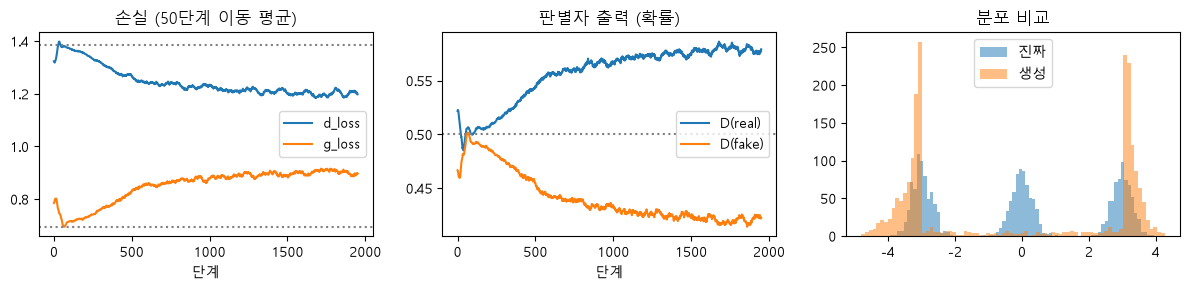

In [19]:
# [보강] 손실 곡선 · 판별자 출력 · 진짜와 생성 분포 그림
fig, ax = plt.subplots(1, 3, figsize=(12, 3))                              # 그림 3칸
for k in ["d_loss", "g_loss"]:                                             # 두 손실
    ax[0].plot(np.convolve(hist1[k], np.ones(50) / 50, "valid"), label=k)  # 50단계 이동 평균
ax[0].axhline(2 * np.log(2), ls=":", c="gray")                             # d_loss 균형점 1.386
ax[0].axhline(np.log(2), ls=":", c="gray")                                 # g_loss 균형점 0.693
ax[0].set_title("손실 (50단계 이동 평균)")                                 # 첫 칸 제목
ax[0].legend()                                                             # 범례
for k in ["D(real)", "D(fake)"]:                                           # 판별자 출력 두 개
    ax[1].plot(np.convolve(hist1[k], np.ones(50) / 50, "valid"), label=k)  # 확률 곡선
ax[1].axhline(0.5, ls=":", c="gray")                                       # 반반 기준선
ax[1].set_title("판별자 출력 (확률)")                                      # 둘째 칸 제목
ax[1].legend()                                                             # 범례
ax[2].hist(real_1d(2000, gen)[:, 0], bins=80, alpha=0.5, label="진짜")     # 진짜 분포
ax[2].hist(sample, bins=80, alpha=0.5, label="생성")                       # 생성 분포
ax[2].set_title("분포 비교")                                               # 셋째 칸 제목
ax[2].legend()                                                             # 범례
ax[0].set_xlabel("단계")                                                   # x축 이름
ax[1].set_xlabel("단계")                                                   # x축 이름
plt.tight_layout()                                                         # 칸 사이 간격 정리
plt.show()                                                                 # 그림 표시

**결과** · 예측 정답은 아님 — 양쪽 봉우리 43%씩, 가운데 봉우리는 3%뿐 (손실은 정상처럼 보여도 봉우리 하나를 거의 놓침)

- `d_loss : 1.3232 → 1.2038` — 1.386(2·ln2) 근처에서 조금 아래 → 판별자가 약간 앞섬
- `g_loss : 0.7851 → 0.9013` — 0.693(ln2)보다 조금 위, 줄다리기 중
- `D(real): 0.5218 → 0.5785` — 진짜를 진짜라고 할 확률이 0.5보다 약간 높음
- `D(fake): 0.4666 → 0.4215` — 가짜는 0.5보다 약간 낮음 → 아직 완전히 속이지 못함
- `봉우리별 비율: [0.431, 0.03, 0.432]` — 가운데 봉우리(0)가 거의 빠짐 = 부분 모드 붕괴 (4장)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">d_loss가 1.386 근처 · D(real) · D(fake)가 0.5 근처</td>
<td style="text-align: left;">판별자가 반반으로 헷갈림</td>
<td style="text-align: left;">균형이 맞는 정상 학습</td>
</tr>
<tr>
<td style="text-align: left;">d_loss → 0 · g_loss 계속 증가</td>
<td style="text-align: left;">판별자가 압도 (3-2 D 강함)</td>
<td style="text-align: left;">D lr · 갱신 횟수 줄이기</td>
</tr>
<tr>
<td style="text-align: left;">d_loss가 처음 값에서 안 변함</td>
<td style="text-align: left;">판별자가 배우지 못함 (3-2 D 약함)</td>
<td style="text-align: left;">D lr 올리기</td>
</tr>
<tr>
<td style="text-align: left;">손실은 정상인데 샘플이 비슷</td>
<td style="text-align: left;">모드 붕괴 가능 (3-3)</td>
<td style="text-align: left;">샘플 그림 · 다양성 수치 확인</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - GAN 손실이 안 내려간다고 실패로, 안정적이라고 성공으로 판단하기
> - 반드시 샘플 · 분포를 함께 확인

> ✅ **한 줄 정리** · GAN 손실은 두 신경망의 줄다리기라 균형점(1.386 · 0.693) 근처에서 흔들리는 것이 정상이며, 품질은 생성 결과를 직접 봐야 판단할 수 있다.

**딥러닝 코드에서는**

- 학습 중 `d_loss` · `g_loss` · `D(real)` · `D(fake)`를 함께 기록
- 고정 z로 만든 샘플 그림을 epoch마다 저장 (5장)

### 2-7. `A` 합성곱 생성자 · 판별자 (DCGAN) · `ConvTranspose2d` · `Conv2d` <sub>수업 Day01 D1-6 · 코드 재현</sub>

> 🎯 **생성자를 전치 합성곱으로 바꾸면 모양은 어떻게 커지고, 같은 노이즈의 그림은 MLP와 어떻게 다른가?**

💡 **쉽게 말하면**

- MLP 생성자는 784칸을 한 줄로 다뤄 **붙은 두 칸이 28칸 떨어진 번호**가 됨.
- DCGAN 생성자는 작은 판(7 × 7)을 전치 합성곱으로 두 배씩 키워 이웃 칸을 함께 그림.
- 판별자는 반대로 합성곱으로 줄임.

**실행 흐름**

1. DCGAN 생성자 · 판별자 만들기
2. 노이즈 2개로 층마다 모양
3. 네 모델의 가중치 개수
4. Normalize 없이 1 epoch(범위 어긋남)
5. DCGAN 10 epoch
6. 같은 고정 노이즈로 MLP와 나란히

**먼저 예측** · DCGAN 판별자의 가중치 개수는 MLP 판별자와 비슷할까? — 답은 코드 실행 결과 아래에

In [20]:
# [수업 재현 D1-6] 합성곱 생성자 · 판별자 (DCGAN) · 모양 길과 가중치 개수
def make_G_dc():  # 노이즈 64 → 128판 × 7 × 7 → 64판 × 14 × 14 → 1판 × 28 × 28
    return nn.Sequential(nn.Linear(ZD, 128 * 7 * 7), nn.Unflatten(1, (128, 7, 7)),  # 판 128개 7 × 7
                         nn.BatchNorm2d(128), nn.ReLU(),
                         # 14 × 14
                         nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(),
                         nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh())  # 28 × 28 · -1 ~ 1


def make_D_dc():  # 28 × 28 → 14 × 14 → 7 × 7 → 값 하나
    return nn.Sequential(nn.Conv2d(1, 64, 4, 2, 1), nn.LeakyReLU(0.2),  # 64판 14 × 14
                         # 128판 7 × 7
                         nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),
                         nn.Flatten(), nn.Linear(128 * 7 * 7, 1))       # 값 하나


set_seed()                                              # 초기값 고정
g = make_G_dc()                                         # 모양 확인용
h = g[3](g[2](g[1](g[0](torch.randn(2, ZD)))))          # Linear · Unflatten · BatchNorm · ReLU
print("Linear · Unflatten · BatchNorm · ReLU 뒤 모양", tuple(h.shape))  # (2, 128, 7, 7)
h = g[6](g[5](g[4](h)))                                 # 전치 합성곱 1 · BatchNorm · ReLU
print("전치 합성곱 1 뒤", tuple(h.shape))               # 가로세로 두 배
h = g[8](g[7](h))                                       # 전치 합성곱 2 · Tanh
print("전치 합성곱 2 뒤 (사진)", tuple(h.shape))        # (2, 1, 28, 28)
print("판별자 출력 모양", tuple(make_D_dc()(h).shape))  # 사진마다 값 하나


def n_par(m):                                      # 가중치 개수 (학습으로 고치는 숫자의 개수)
    return sum(p.numel() for p in m.parameters())  # 층마다 가중치 · 편향 개수의 합


for name, m in [("MLP G", make_G()), ("DCGAN G", make_G_dc()),  # 네 모델
                ("MLP D", make_D()), ("DCGAN D", make_D_dc())]:
    print(f"{name:8} {n_par(m):,}")                             # 천 단위 쉼표


# 범위 어긋남: Normalize 없이(진짜 0 ~ 1) MLP GAN 1 epoch → 생성 값 범위
set_seed()                                                                          # 초기값 고정
G_raw, _ = train_gan(make_G(), make_D(), X01, 1)  # 진짜만 0 ~ 1 · 생성자 끝은 Tanh 그대로
with torch.no_grad():                                                               # 생성만
    # 1000장
    out = G_raw(torch.randn(1000, ZD, generator=torch.Generator().manual_seed(SEED)).to(device))
print("진짜 사진 값 범위 0.0 ~ 1.0 · 음수 비율", (X01 < 0).float().mean().item())   # 0.0
print("생성 값 범위", round(out.min().item(), 2), "~", round(out.max().item(), 2),  # 음수가 섞임
      "· 음수 비율", round((out < 0).float().mean().item(), 3))

Linear · Unflatten · BatchNorm · ReLU 뒤 모양 (2, 128, 7, 7)
전치 합성곱 1 뒤 (2, 64, 14, 14)
전치 합성곱 2 뒤 (사진) (2, 1, 28, 28)
판별자 출력 모양 (2, 1)
MLP G    550,416
DCGAN G  540,225
MLP D    533,505
DCGAN D  138,817


진짜 사진 값 범위 0.0 ~ 1.0 · 음수 비율 0.0
생성 값 범위 -0.95 ~ 1.0 · 음수 비율 0.359


DCGAN 10 epoch 학습 끝 · epoch 10 판별자 손실 0.434 · 생성자 손실 2.460


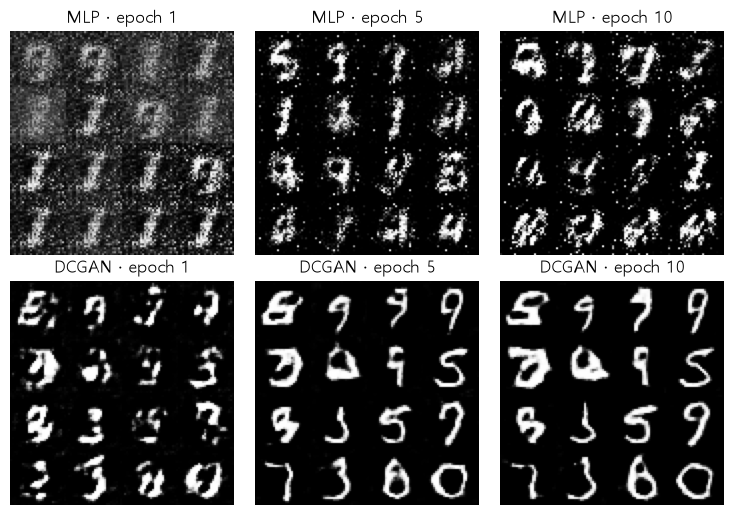

In [21]:
# [수업 재현 D1-6] DCGAN을 같은 방식 · 같은 고정 노이즈로 10 epoch → MLP와 나란히
set_seed()                                                               # 초기값 고정
# 사진 모양 입력
G_dc, log_dc = train_gan(make_G_dc(), make_D_dc(), X_mnist.view(-1, 1, 28, 28), 10,
                         keep=(1, 5, 10))
print(f"DCGAN 10 epoch 학습 끝 · epoch 10 판별자 손실 {log_dc['d'][-1]:.3f}"  # 끝 손실
      f" · 생성자 손실 {log_dc['g'][-1]:.3f}")
fig, ax = plt.subplots(2, 3, figsize=(7.5, 5.2))                         # 위 = MLP, 아래 = DCGAN
for r, (name, log) in enumerate([("MLP", log_mlp), ("DCGAN", log_dc)]):  # 줄마다 한 모델
    for c, e in enumerate((1, 5, 10)):                                   # 같은 epoch
        ax[r, c].imshow(tile(log["grid"][e]), cmap="gray")               # 같은 고정 노이즈 16장
        ax[r, c].set_title(f"{name} · epoch {e}")                        # 칸 제목
        ax[r, c].axis("off")                                             # 축 숨김
plt.tight_layout()                                                       # 간격 정리
plt.show()                                                               # 그림 표시

**결과** · 예측 정답은 아님 — 약 1/4 (생성자는 둘이 비슷)

- `Linear · Unflatten · BatchNorm · ReLU 뒤 모양 (2, 128, 7, 7)` — 노이즈 64개 → 판 128개 × 7 × 7
- `전치 합성곱 2 뒤 (사진) (2, 1, 28, 28)` — 전치 합성곱 두 번(커널 4 · 보폭 2 · 패딩 1)으로 가로세로 7 → 14 → 28
- `DCGAN D 138,817` — 합성곱은 작은 창을 같이 써서 MLP D(533,505)의 약 1/4
- `MLP G 550,416` — 생성자 크기는 비슷 (DCGAN G 540,225) → 차이는 크기보다 층 종류
- `생성 값 범위 -0.95 ~ 1.0 · 음수 비율 0.359` — 진짜는 0 ~ 1인데 Tanh 생성자는 음수를 36% 냄 → 판별자가 범위만 보고 가려냄
- `DCGAN 10 epoch 학습 끝 · epoch 10 판별자 손실 0.434 · 생성자 손실 2.460` — 그림 아래 줄: 1 epoch부터 획 모양 · 흰 점이 거의 없음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">MLP 생성자</td>
<td style="text-align: left;">784칸 한 줄, 붙은 칸이 28칸 떨어진 번호</td>
<td style="text-align: left;">작은 실험 · 기준선</td>
</tr>
<tr>
<td style="text-align: left;">DCGAN 생성자 (ConvTranspose2d)</td>
<td style="text-align: left;">작은 판을 두 배씩 키움, 이웃 칸을 함께</td>
<td style="text-align: left;">이미지 생성 기본</td>
</tr>
<tr>
<td style="text-align: left;">Conv2d 판별자</td>
<td style="text-align: left;">창을 같이 써서 가중치가 적음</td>
<td style="text-align: left;">이미지 판별자 기본</td>
</tr>
<tr>
<td style="text-align: left;">Normalize ↔ Tanh</td>
<td style="text-align: left;">진짜와 생성 값 범위를 -1 ~ 1로 맞춤</td>
<td style="text-align: left;">항상 (어긋나면 판별자가 범위로 가려냄)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - MLP와 DCGAN은 생성자 · 판별자 · 층 종류 · 크기가 동시에 다름
> - '합성곱 때문'이라고 하나로 단정하지 않기

> ✅ **한 줄 정리** · DCGAN은 전치 합성곱으로 작은 판을 두 배씩 키워 이웃 칸을 함께 그리며, 진짜와 생성 값의 범위는 Normalize와 Tanh로 맞춘다.

**딥러닝 코드에서는**

- 합성곱 · 출력 크기 공식은 CNN-1 · 2
- 전치 합성곱(ConvTranspose2d)은 오토인코더-1 참조

---
## 3. 다양성 · 학습 균형 · 모드 붕괴

**GAN 파트 · 2 / 3 · 수업 Day01 D1-7 + 보강**

> **이 장의 흐름**
>
> - 2장 GAN은 숫자 모양을 만들었지만 여러 숫자를 고르게 만드는지는 아직 모름
> - 세는 도구부터 점검하고, 봉우리 8개 2차원 데이터에서 균형이 깨질 때 · 생성자가 앞서 나갈 때의 무너짐을 일부러 만들고 진단 · 대응.

**파이프라인 위치** · 학습 진단 — 도구 점검, 손실 곡선, 샘플 그림, 다양성 수치, 대응 장치

### 3-1. `A` 다양성 확인 · 세는 도구부터 점검 · `clf` · `torch.bincount` <sub>수업 Day01 D1-7 · 코드 재현</sub>

> 🎯 **생성 그림이 여러 숫자를 고르게 만드는지 세려면, 세는 도구부터 어떻게 확인하는가?**

💡 **쉽게 말하면**

- 숫자처럼 보이는 것과 **여러 숫자가 나오는 것**은 다른 기준.
- 숫자 분류기로 세려면 답을 아는 입력(진짜 · 반복 · 무작위)으로 도구부터 점검.
- 분류기는 '숫자 아님' 칸이 없어 모래 그림에도 숫자 이름을 붙임.

**실행 흐름**

1. 숫자 분류기 2 epoch 학습 · 시험 정확도
2. 진짜 80장 · 같은 사진 80번 · 무작위 80장으로 점검
3. 판별자 학습률 5배 MLP GAN 15 epoch
4. 새 노이즈 64장으로 2-4 생성자와 나란히

**먼저 예측** · 숫자가 아닌 무작위 사진 80장을 넣으면, 분류기는 낮은 확신으로 여러 숫자에 흩어 붙일까? — 답은 코드 실행 결과 아래에

In [22]:
# [수업 재현 D1-7] 다양성을 세는 도구부터 점검: 숫자 분류기 (5장 평가에도 사용)
set_seed()                                                             # 분류기 초기값 고정
clf = nn.Sequential(                                                   # 작은 CNN 분류기
    nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(), nn.Linear(32 * 7 * 7, 10)).to(device)
opt = torch.optim.Adam(clf.parameters(), lr=1e-3)                      # 분류기 옵티마이저
Xc = ((X_mnist + 1) / 2).view(-1, 1, 28, 28).to(device)                # 0 ~ 1 이미지
Yc = Y_mnist.to(device)                                                # 정답 숫자
gen = torch.Generator().manual_seed(SEED)                              # 섞는 순서 고정
for epoch in range(2):                                                 # 2 epoch이면 충분히 정확
    perm = torch.randperm(len(Xc), generator=gen).to(device)           # 섞은 번호
    for i in range(0, len(Xc), 256):                                   # 배치 256장씩
        b = perm[i:i + 256]                                            # 이번 배치 번호
        loss = F.cross_entropy(clf(Xc[b]), Yc[b])                      # 숫자 분류 손실
        opt.zero_grad()                                                # 기울기 비우기
        loss.backward()                                                # 기울기 계산
        opt.step()                                                     # 분류기 갱신
with torch.no_grad():                                                  # 평가만
    x_te = X_test01.view(-1, 1, 28, 28).to(device)                     # 시험 1만 장
    acc = (clf(x_te).argmax(1).cpu() == Y_test).float().mean().item()  # 정확도
print(f"평가용 분류기 테스트 정확도: {acc:.4f}")                       # 도구가 믿을 만한지


# 점검: 답을 아는 입력 세 가지 (진짜 80장 · 같은 사진 80번 · 무작위 80장)
gen = torch.Generator().manual_seed(SEED)                            # 무작위 사진 고정
# 기대 10 · 1종류
checks = {"진짜 사진 80장": X_test01[:80], "같은 사진 80번": X_test01[:1].repeat(80, 1),
          "무작위 사진 80장": torch.rand(80, 784, generator=gen)}    # 숫자가 아님
with torch.no_grad():                                                # 분류만
    for name, x in checks.items():                                   # 세 가지 입력
        prob = F.softmax(clf(x.view(-1, 1, 28, 28).to(device)), 1)   # 숫자 0 ~ 9 확률
        counts = torch.bincount(prob.argmax(1).cpu(), minlength=10)  # 숫자별 개수
        # 종류 · 개수
        print(f"{name} → {int((counts > 0).sum())}종류 · 숫자별 개수 {counts.tolist()}"
              f" · 가장 큰 확률 평균 {prob.max(1).values.mean().item():.2f}")

평가용 분류기 테스트 정확도: 0.9731
진짜 사진 80장 → 10종류 · 숫자별 개수 [9, 11, 7, 8, 11, 7, 6, 11, 1, 9] · 가장 큰 확률 평균 0.96
같은 사진 80번 → 1종류 · 숫자별 개수 [0, 0, 0, 0, 0, 0, 0, 80, 0, 0] · 가장 큰 확률 평균 1.00
무작위 사진 80장 → 2종류 · 숫자별 개수 [0, 2, 0, 0, 0, 0, 0, 0, 78, 0] · 가장 큰 확률 평균 0.82


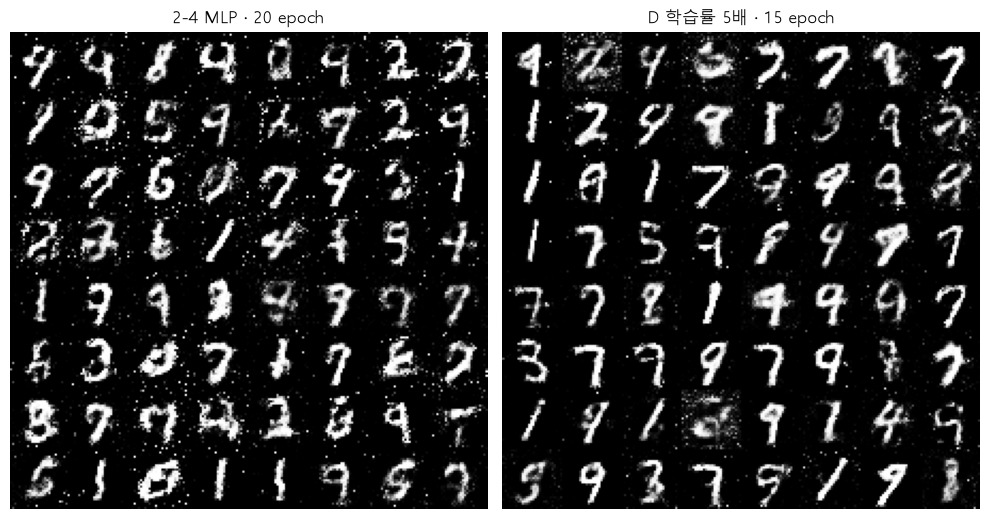

D 학습률 5배 · epoch 15 판별자 손실 0.708 · 생성자 손실 2.197


In [23]:
# [수업 재현 D1-7] 판별자를 더 빠르게(학습률 5배) 배우게 한 MLP GAN · 새 노이즈 64장
set_seed()                                                                   # 2-4와 같은 출발점
# D lr 2e-4 → 1e-3
G_fast, log_fast = train_gan(make_G(), make_D(), X_mnist, 15, lr_d=1e-3, keep=())
gen = torch.Generator().manual_seed(SEED + 1)  # 고정 노이즈와 다른 새 노이즈
z64 = torch.randn(64, ZD, generator=gen).to(device)                          # 새 노이즈 64개
with torch.no_grad():                                                        # 생성만
    sheets = {"2-4 MLP · 20 epoch": G_mlp(z64), "D 학습률 5배 · 15 epoch": G_fast(z64)}  # 64장씩
fig, ax = plt.subplots(1, 2, figsize=(10, 5.2))                              # 두 장 나란히
for a, (title, g) in zip(ax, sheets.items()):                                # 생성자마다
    grid = g.view(8, 8, 28, 28).permute(0, 2, 1, 3).reshape(224, 224).cpu()  # 8 × 8 격자
    a.imshow((grid + 1) / 2, cmap="gray")                                    # 0 ~ 1로 되돌려 그림
    a.set_title(title)                                                       # 칸 제목
    a.axis("off")                                                            # 축 숨김
plt.tight_layout()                                                           # 간격 정리
plt.show()                                                                   # 그림 표시
print("D 학습률 5배 · epoch 15 판별자 손실", round(log_fast["d"][-1], 3),    # D가 앞섬
      "· 생성자 손실", round(log_fast["g"][-1], 3))

**결과** · 예측 정답은 아님 — 78장을 8로 붙이고, 가장 큰 확률 평균도 0.82로 높음 (확신으로도 거르기 어려움)

- `평가용 분류기 테스트 정확도: 0.9731` — 진짜 숫자는 97% 맞힘 (수업 분류기는 0.989)
- `진짜 사진 80장 → 10종류` — 기대대로 10종류
- `같은 사진 80번 → 1종류` — 기대대로 1종류
- `무작위 사진 80장 → 2종류 · 숫자별 개수 [0, 2, 0, 0, 0, 0, 0, 0, 78, 0] · 가장 큰 확률 평균 0.82` — 숫자가 아닌데 높은 확신으로 8 → 이 도구의 '숫자 종류 수'를 그대로 믿으면 안 됨
- `D 학습률 5배 · epoch 15 판별자 손실 0.708 · 생성자 손실 2.197` — 그림 오른쪽: 1 · 7 · 9 위주로 쏠림 (왼쪽 2-4 생성자는 여러 숫자)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">눈으로 보기 (64장 격자)</td>
<td style="text-align: left;">도구 없음, 볼 수 있는 장 수가 적음</td>
<td style="text-align: left;">항상 함께</td>
</tr>
<tr>
<td style="text-align: left;">숫자 분류기로 세기</td>
<td style="text-align: left;">많이 셀 수 있음, '숫자 아님' 칸이 없음</td>
<td style="text-align: left;">숫자 모양이 나온 뒤의 참고값 (5장)</td>
</tr>
<tr>
<td style="text-align: left;">도구 점검 (진짜 · 반복 · 무작위)</td>
<td style="text-align: left;">답을 아는 입력으로 도구부터 확인</td>
<td style="text-align: left;">새 지표를 쓰기 전 항상</td>
</tr>
<tr>
<td style="text-align: left;">판별자 학습률 5배</td>
<td style="text-align: left;">판별자가 빨리 앞서 생성자가 몇 숫자로 쏠림</td>
<td style="text-align: left;">균형 실험 (3-2)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 도구 점검이 실패하면 그 도구만으로 재지 않음
> - 그림을 함께 보고, 5장 숫자 분포는 숫자 모양이 나온 뒤의 참고값으로

> ✅ **한 줄 정리** · 다양성은 숫자 모양과 다른 기준이며, 세는 도구는 답을 아는 입력으로 먼저 점검하고 믿기 어려우면 그림을 함께 본다.

**딥러닝 코드에서는**

- FID · IS도 사전학습 분류기(Inception)의 특징을 쓰는 도구
- 생성 평가 전에 도구가 그 데이터에 맞는지 확인 (생성모델-2)

### 3-2. `A` 판별자가 너무 강함 vs 너무 약함 · `d_steps` · `lr_d` <sub>개념 위클리 9 Q3 · 위클리 11 대응 기법 · 코드 보강</sub>

> 🎯 **판별자가 생성자보다 너무 강하거나 너무 약하면 손실과 생성 결과는 어떻게 달라지는가?**

💡 **쉽게 말하면**

- 감별사가 **너무 뛰어나면** 위조범은 뭘 고쳐야 할지 모른 채 몇 가지 무난한 위조만 반복하고, **너무 엉터리면** 위조범은 아무렇게나 만들어도 통과라 실력이 늘지 않음.

**실행 흐름**

1. 봉우리 8개 2차원 데이터
2. 학습 · 점검 함수
3. 기준(1:1) · D 강함(5번씩 · lr 5배) · D 약함(lr 1/100)
4. 마지막 300단계 손실 · 품질 · 잡은 봉우리

**먼저 예측** · 판별자가 강하면 생성 샘플의 품질(봉우리 근처 비율)은 떨어질까? — 답은 코드 실행 결과 아래에

In [24]:
# [보강] 2차원 진짜 데이터: 반지름 2 원 위 봉우리 8개 (표준편차 0.1)
ang = torch.arange(8) * (2 * np.pi / 8)                                 # 8방향 각도
CENTERS = torch.stack([2 * torch.cos(ang), 2 * torch.sin(ang)], dim=1)  # (8, 2) 봉우리 중심


def real_2d(n, gen):                                            # 진짜 2차원 점 n개
    k = torch.randint(0, 8, (n,), generator=gen)                # 봉우리 고르기
    return CENTERS[k] + 0.1 * torch.randn(n, 2, generator=gen)  # 중심 + 작은 흔들림


class MinibatchStdDev(nn.Module):                # 3-4에서 사용: 배치 다양성을 특징 1개로
    def forward(self, h):                        # h: (배치, 특징)
        s = h.std(dim=0, unbiased=False).mean()  # 샘플 간 표준편차의 평균
        return torch.cat([h, s.expand(h.shape[0], 1)], dim=1)  # 특징 끝에 1칸 붙임


def make_d(mbstd=False):                                 # 2차원 판별자 (mbstd=True면 장치 추가)
    act = nn.LeakyReLU(0.2)                              # 판별자 관례 활성화
    layers = [nn.Linear(2, 64), act, nn.Linear(64, 64), act]  # 공통 몸통
    if mbstd:                                            # 장치를 마지막 층 직전에
        layers += [MinibatchStdDev(), nn.Linear(65, 1)]  # 특징 64 + 1
    else:
        layers += [nn.Linear(64, 1)]                     # 기본 출력층
    return nn.Sequential(*layers)                        # 층 목록 → 모델

In [25]:
# [보강] 같은 조건 학습 함수 (균형 · 장치만 바꿈) · 품질 점검 함수
def train_2d(d_steps=1, g_steps=1, lr_d=1e-3, lr_g=1e-3, mbstd=False,   # 바꿀 손잡이들
             steps=3000):
    set_seed()                                                          # 실험마다 같은 출발점
    G = mlp(2, 2, nn.ReLU(), hidden=64).to(device)                      # 생성자 (z 2개 → 점 1개)
    D = make_d(mbstd).to(device)                                        # 판별자
    og = torch.optim.Adam(G.parameters(), lr=lr_g, betas=(0.5, 0.999))  # 생성자 옵티마이저
    od = torch.optim.Adam(D.parameters(), lr=lr_d, betas=(0.5, 0.999))  # 판별자 옵티마이저
    gen = torch.Generator().manual_seed(SEED)                           # 데이터 · z 난수 고정
    one = torch.ones(64, 1, device=device)                              # 진짜 정답
    hist = {"d_loss": [], "g_loss": []}                                 # 손실 기록
    for step in range(steps):                                           # 학습 반복
        for _ in range(d_steps):                                        # 판별자 d_steps번
            real = real_2d(64, gen).to(device)                          # 진짜 배치
            fake = G(torch.randn(64, 2, generator=gen).to(device)).detach()  # G와 끊은 가짜
            d_loss = bce(D(real), one) + bce(D(fake), 0 * one)          # 진짜 1 · 가짜 0
            od.zero_grad()                                              # 기울기 비우기
            d_loss.backward()                                           # 판별자 기울기
            od.step()                                                   # 판별자 갱신
        for _ in range(g_steps):                                        # 생성자 g_steps번
            fake = G(torch.randn(64, 2, generator=gen).to(device))      # 새 가짜
            g_loss = bce(D(fake), one)                                  # 가짜를 진짜로
            og.zero_grad()                                              # 기울기 비우기
            g_loss.backward()                                           # D를 거쳐 G까지
            og.step()                                                   # 생성자 갱신
        hist["d_loss"].append(d_loss.item())                            # 마지막 판별자 손실
        hist["g_loss"].append(g_loss.item())                            # 마지막 생성자 손실
    return G, hist                                                      # 학습된 생성자 · 기록


@torch.no_grad()
def check_2d(G, n=2000):                                      # 품질 · 잡은 봉우리 · 배치 다양성
    gen = torch.Generator().manual_seed(0)                    # 점검용 z는 항상 같게
    x = G(torch.randn(n, 2, generator=gen).to(device)).cpu()  # 생성 n개
    dist, k = torch.cdist(x, CENTERS).min(dim=1)              # 가장 가까운 봉우리
    good = dist < 0.3                                         # 봉우리 중심 0.3 이내 = 그럴듯한 샘플
    modes = int((torch.bincount(k[good], minlength=8) >= 50).sum())  # 50개 넘게 간 봉우리 수
    spread = torch.pdist(x[:500]).mean().item()               # 샘플끼리 평균 거리
    return x, dict(quality=good.float().mean().item(), modes=modes,  # 점 · 지표 3개
                   spread=spread)

In [26]:
# [보강] 기준 · 판별자 강함(5번씩 · 큰 lr) · 판별자 약함(아주 작은 lr)
runs_21 = {"기준 1:1": dict(),                                       # 실험 이름 → 바꿀 설정
           "D 강함": dict(d_steps=5, lr_d=5e-3),
           "D 약함": dict(lr_d=1e-5)}
res_21 = {}                                                          # 실험별 (생성 점, 손실 기록)
for name, cfg in runs_21.items():                                    # 세 실험을 같은 조건으로
    G, hist = train_2d(**cfg)                                        # 설정만 바꿔 학습
    x, m = check_2d(G)                                               # 품질 점검
    res_21[name] = (x, hist)                                         # 3-4 그림용으로 보관
    print(f"{name:7} | d_loss {np.mean(hist['d_loss'][-300:]):.4f}"  # 마지막 300단계 평균
          f" | g_loss {np.mean(hist['g_loss'][-300:]):.4f}"
          f" | 품질 {m['quality']:.3f} | 봉우리 {m['modes']}/8")

기준 1:1  | d_loss 1.3664 | g_loss 0.7370 | 품질 0.863 | 봉우리 8/8


D 강함    | d_loss 0.7161 | g_loss 1.5883 | 품질 0.900 | 봉우리 3/8


D 약함    | d_loss 1.3876 | g_loss 0.7352 | 품질 0.000 | 봉우리 0/8


**결과** · 예측 정답은 아님 — 품질은 0.900으로 오히려 높지만 봉우리를 3개만 잡음 (확실한 곳만 만들기)

- `기준 1:1  | d_loss 1.3664 | g_loss 0.7370 | 품질 0.863 | 봉우리 8/8` — 균형점 근처, 8개 봉우리를 모두 덮음
- `D 강함    | d_loss 0.7161 | g_loss 1.5883 | 품질 0.900 | 봉우리 3/8` — d_loss가 크게 낮고 g_loss가 높음 → D가 압도, 다양성 손실
- `D 약함    | d_loss 1.3876 | g_loss 0.7352 | 품질 0.000 | 봉우리 0/8` — 손실은 균형점과 같아 보이지만 D가 배우지 못해 G도 엉뚱한 곳

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">판별자 너무 강함</td>
<td style="text-align: left;">가짜를 쉽게 가려내 D 출력이 0에 붙음 → G가 받는 신호가 들쭉날쭉</td>
<td style="text-align: left;">D 갱신 횟수 · lr 줄이기, 정규화(Spectral Norm · R1)</td>
</tr>
<tr>
<td style="text-align: left;">판별자 너무 약함</td>
<td style="text-align: left;">진짜 · 가짜를 못 가려 G에게 쓸모 있는 방향을 못 줌</td>
<td style="text-align: left;">D lr 올리기 · D 키우기</td>
</tr>
<tr>
<td style="text-align: left;">균형 (1:1 · 같은 lr)</td>
<td style="text-align: left;">서로 따라잡으며 둘 다 배움</td>
<td style="text-align: left;">출발점, 이후 TTUR(D lr 4배) 등으로 조정</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - "D 약함"의 손실은 기준과 거의 같음 (1.3876 vs 1.3664)
> - 손실 숫자만으로는 정상과 구분 불가, 샘플을 그려야 보임

> ✅ **한 줄 정리** · 판별자가 너무 강하면 생성자는 확실한 몇 곳에만 몰리고, 너무 약하면 학습 신호가 없어 아무것도 배우지 못하므로 두 신경망의 균형을 맞춰야 한다.

**딥러닝 코드에서는**

- 균형 조정 손잡이: 갱신 비(D:G), 학습률(TTUR: D 4e-4 · G 1e-4), 정규화(Spectral Norm · R1)
- 한 번에 하나씩 바꾸며 비교 (위클리 11)

### 3-3. `A` 모드 붕괴 만들기와 진단 · `g_steps=5` · `pdist` <sub>개념 위클리 11 · 코드 보강</sub>

> 🎯 **생성자를 판별자보다 너무 자주 갱신하면 어떤 일이 생기고, 그것을 숫자로 어떻게 알아보는가?**

💡 **쉽게 말하면**

- 위조범이 감별사보다 5배 빨리 연습하면 **지금 감별사가 가장 잘 속는 위조 하나**만 계속 찍어 냄.
- 손님(z)이 누구든 같은 지폐를 건네는 상태 = **모드 붕괴**.

<img src="images/gen1_collapse.png" alt="정상과 모드 붕괴: 서로 다른 z 5개의 행선지" width="894">

**실행 흐름**

1. G 5번 : D 1번 학습
2. 정상과 품질 · 봉우리 · 배치 다양성 비교
3. 서로 다른 z 5개의 출력
4. 진짜 데이터의 배치 다양성(기준)

**먼저 예측** · 생성자를 5배 자주 갱신하면 서로 다른 z 5개의 출력은 얼마나 다를까? — 답은 코드 실행 결과 아래에

In [27]:
# [보강] 모드 붕괴를 일부러: 생성자를 판별자보다 5배 자주 갱신
G_c, hist_c = train_2d(g_steps=5)                       # D 1번 : G 5번
x_c, m_c = check_2d(G_c)                                # 붕괴 모델 점검
x_n, m_n = check_2d(train_2d()[0])                      # 기준(1:1) 다시 학습 → 같은 결과
for name, m in [("정상 1:1", m_n), ("붕괴 1:5", m_c)]:  # 두 모델 나란히
    print(f"{name} | 품질 {m['quality']:.3f} | 봉우리 {m['modes']}/8"  # 품질 · 봉우리 · 다양성
          f" | 배치 다양성(평균 거리) {m['spread']:.4f}")


# 진단 1: 서로 다른 z 5개 → 출력이 얼마나 다른가
z5 = torch.randn(5, 2, generator=torch.Generator().manual_seed(1))  # 서로 다른 z 5개
with torch.no_grad():                                               # 확인만
    out = G_c(z5.to(device)).cpu()                                  # 붕괴 생성자의 출력
print("붕괴 G의 z 5개 출력:", [[round(v, 2) for v in r] for r in out.tolist()])  # 거의 같은 점?


# 진단 2: 진짜 데이터 사이 평균 거리 (다양성의 기준)
real = real_2d(500, torch.Generator().manual_seed(0))                         # 진짜 500개
print("진짜 데이터 배치 다양성:", round(torch.pdist(real).mean().item(), 4))  # 비교 기준값

정상 1:1 | 품질 0.863 | 봉우리 8/8 | 배치 다양성(평균 거리) 2.5664
붕괴 1:5 | 품질 0.377 | 봉우리 1/8 | 배치 다양성(평균 거리) 0.1749
붕괴 G의 z 5개 출력: [[1.13, 1.2], [1.06, 1.14], [1.14, 1.19], [1.15, 1.2], [1.18, 1.18]]
진짜 데이터 배치 다양성: 2.5395


**결과** · 예측 정답은 거의 같음 — 모두 (1.1, 1.2) 근처 한 점, 배치 다양성 0.1749 (진짜는 2.5395)

- `정상 1:1 | 품질 0.863 | 봉우리 8/8 | 배치 다양성(평균 거리) 2.5664` — 진짜 데이터(2.5395)와 비슷한 퍼짐
- `붕괴 1:5 | 품질 0.377 | 봉우리 1/8 | 배치 다양성(평균 거리) 0.1749` — 봉우리 1개 · 다양성이 진짜의 7% → 완전 붕괴에 가까움
- `붕괴 G의 z 5개 출력: [[1.13, 1.2], [1.06, 1.14], [1.14, 1.19], [1.15, 1.2], [1.18, 1.18]]` — z가 달라도 출력이 거의 같음 → 생성자가 z를 무시
- `진짜 데이터 배치 다양성: 2.5395` — 다양성 수치의 기준값

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">정상</td>
<td style="text-align: left;">z가 다르면 출력도 다름, 봉우리 8개를 모두 덮음</td>
<td style="text-align: left;">목표 상태</td>
</tr>
<tr>
<td style="text-align: left;">완전 붕괴</td>
<td style="text-align: left;">모든 z가 거의 한 점 → 배치 다양성이 0에 가까움</td>
<td style="text-align: left;">z 5개 출력 비교 · 배치 평균 거리로 바로 보임</td>
</tr>
<tr>
<td style="text-align: left;">부분 붕괴 (모드 누락)</td>
<td style="text-align: left;">여러 종류지만 일부 봉우리(숫자)가 없음</td>
<td style="text-align: left;">분류기로 종류 분포를 세야 보임 (5장 MNIST)</td>
</tr>
<tr>
<td style="text-align: left;">모드 호핑</td>
<td style="text-align: left;">학습 시점마다 쏠리는 종류가 통째로 바뀜</td>
<td style="text-align: left;">고정 z 격자를 시점별로 비교 (5장)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 첫 단계부터 출력이 비슷하면 붕괴보다 **구현 오류**(z를 루프 밖에서 한 번만 뽑음 · 같은 배치 반복)를 먼저 의심 (위클리 11 진단표)

> ✅ **한 줄 정리** · 모드 붕괴는 z가 달라도 출력이 몇 가지로 몰리는 현상이며, 배치 안 샘플 간 평균 거리 같은 다양성 수치를 진짜 데이터와 비교해 알아본다.

**딥러닝 코드에서는**

- 학습 중 `torch.pdist(G(z).flatten(1)).mean()`을 기록 → 계속 줄면 경고
- 고정 z 격자 그림을 epoch마다 저장해 나란히 비교

### 3-4. `B` 대응: Minibatch StdDev · `MinibatchStdDev` <sub>개념 위클리 11 대응 기법 · 코드 보강</sub>

> 🎯 **판별자에 배치 다양성을 보여 주면, 같은 붕괴 설정에서도 생성자가 다시 다양해지는가?**

💡 **쉽게 말하면**

- 감별사에게 **한 번에 여러 장을 보여 주고 "이 묶음이 다 비슷한가"도 보게** 하면, 같은 위조만 반복하는 위조범은 바로 들킴.

**실행 흐름**

1. 붕괴 설정(1:5) 그대로 판별자에 MinibatchStdDev 추가
2. 품질 · 봉우리 · 다양성
3. 다양한 배치 · 같은 점 배치에서 붙는 특징 값
4. 다섯 실험 산점도

**먼저 예측** · 붕괴 설정은 그대로 두고 판별자에 장치 하나만 넣어도 봉우리를 되찾을까? — 답은 코드 실행 결과 아래에

붕괴 1:5 + MinibatchStdDev | 품질 0.910 | 봉우리 8/8 | 배치 다양성 2.4728
붙는 특징 · 다양한 배치: 1.4172 | 같은 점 배치: 0.0


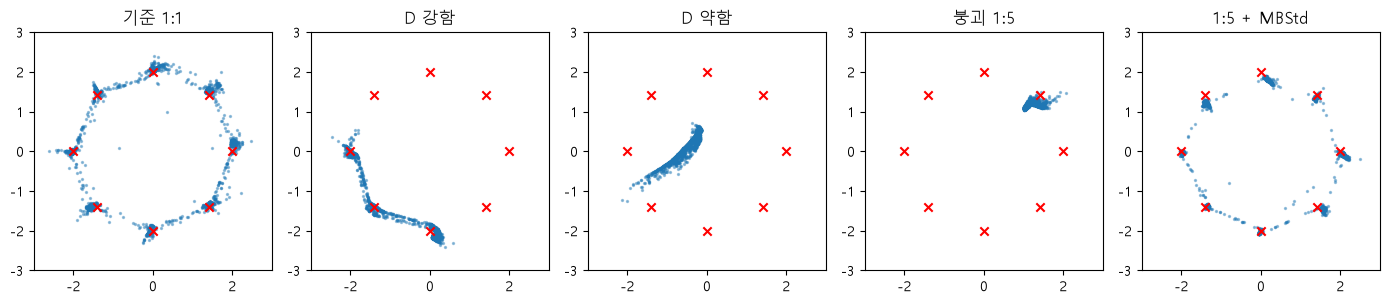

In [28]:
# [보강] 대응: 판별자에 Minibatch StdDev → 배치가 단조로우면 가짜로 알아봄
G_m, hist_m = train_2d(g_steps=5, mbstd=True)                    # 붕괴 설정 그대로 + 장치
x_m, m_m = check_2d(G_m)                                         # 같은 점검
print(f"붕괴 1:5 + MinibatchStdDev | 품질 {m_m['quality']:.3f}"  # 3-3 붕괴와 비교
      f" | 봉우리 {m_m['modes']}/8 | 배치 다양성 {m_m['spread']:.4f}")


# 같은 배치 통계를 다양한 배치 · 단조로운 배치에서 비교
layer = MinibatchStdDev()                                                 # 장치 하나만 따로
varied = real_2d(64, torch.Generator().manual_seed(0))                    # 다양한 배치
same = varied[:1].repeat(64, 1)                                           # 한 점만 64번
print("붙는 특징 · 다양한 배치:", round(layer(varied)[0, -1].item(), 4),  # 붙은 마지막 칸
      "| 같은 점 배치:", round(layer(same)[0, -1].item(), 4))


# 기준 · D 강함 · D 약함 · 붕괴 · 대응 산점도
panels = [(res_21[k][0], k) for k in runs_21] + [(x_c, "붕괴 1:5"),  # 그림 5칸 재료
                                                 (x_m, "1:5 + MBStd")]
fig, ax = plt.subplots(1, 5, figsize=(14, 2.9))                      # 가로 5칸
for a, (x, title) in zip(ax, panels):                                # 칸마다 한 실험
    a.scatter(x[:, 0], x[:, 1], s=2, alpha=0.4)                      # 생성 점
    a.scatter(CENTERS[:, 0], CENTERS[:, 1], c="red", marker="x")     # 진짜 봉우리 중심
    a.set_title(title)                                               # 실험 이름
    a.set_xlim(-3, 3)                                                # 칸마다 같은 축 범위
    a.set_ylim(-3, 3)                                                # 비교하기 쉽게
    a.set_aspect("equal")                                            # 원이 찌그러지지 않게
plt.tight_layout()                                                   # 간격 정리
plt.show()                                                           # 그림 표시

**결과** · 예측 정답은 되찾음 — 1/8 → 8/8, 배치 다양성 0.1749 → 2.4728

- `붕괴 1:5 + MinibatchStdDev | 품질 0.910 | 봉우리 8/8 | 배치 다양성 2.4728` — 같은 1:5인데 정상보다 품질까지 높음
- `붙는 특징 · 다양한 배치: 1.4172 | 같은 점 배치: 0.0` — 단조로운 배치는 이 특징이 0 → 판별자가 "가짜 묶음"으로 바로 알아봄

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">Minibatch StdDev</td>
<td style="text-align: left;">판별자가 배치 안 샘플 간 표준편차를 특징으로 봄 → 단조로운 배치를 가짜로</td>
<td style="text-align: left;">모드 붕괴 대응의 첫 시도, 비용 거의 없음 (ProGAN · StyleGAN)</td>
</tr>
<tr>
<td style="text-align: left;">D:G 갱신 비 조정</td>
<td style="text-align: left;">한쪽이 앞서 나가지 않게 균형 (이 실험의 원인 제거)</td>
<td style="text-align: left;">생성자 과학습이 원인일 때</td>
</tr>
<tr>
<td style="text-align: left;">WGAN-GP · Spectral Norm</td>
<td style="text-align: left;">손실 · 정규화를 바꿔 기울기를 안정화</td>
<td style="text-align: left;">모델이 크고 학습이 자주 흔들릴 때 (위클리 11 표)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - Minibatch StdDev는 판별자의 **입력이 아니라 마지막 층 직전 특징**에 붙임 (위클리 11 정정)
> - 배치가 너무 작으면 표준편차가 흔들림

> ✅ **한 줄 정리** · 판별자가 배치 안 샘플 간 다양성을 특징으로 보게 하면, 생성자는 한 가지만 반복해서는 속일 수 없어 모드 붕괴가 줄어든다.

**딥러닝 코드에서는**

- StyleGAN 판별자 마지막 블록의 `MinibatchStdDev(group_size=4)`
- 원인이 여러 겹이라 점검 → 균형 → 손실 · 정규화 → 다양성 장치 순서로 하나씩 (위클리 11)

---
## 4. Diffusion

**Diffusion 파트 · GAN 코드와 섞지 않고 이 장에서만 다룸 (데이터는 3장 봉우리 8개 · 0장 MNIST를 재사용)**

> **이 장의 흐름**
>
> - 3장 GAN은 두 신경망의 경쟁이라 균형이 깨지면 무너졌다
> - Diffusion은 경쟁 없이 "넣은 노이즈를 맞히는" 회귀 문제 하나로 바꿔 안정적으로 학습.

**파이프라인 위치** · 생성 모델 비교 — 전방향(정해진 노이즈) · 역방향(학습한 예측으로 생성)

### 4-1. `A` Diffusion 전방향: 노이즈 더하기 · `ᾱ_t` · `add_noise` <sub>개념 위클리 9 Q4 · 코드 보강</sub>

> 🎯 **Diffusion의 전방향 과정은 데이터에 노이즈를 어떤 비율로 더하며, 마지막에는 무엇이 남는가?**

💡 **쉽게 말하면**

- 사진 위에 **모래를 조금씩 1000번 뿌리는 것**.
- 몇 번 뿌리면 윤곽이 보이지만 1000번 뒤에는 **모래(노이즈)만** 남음.
- 뿌리는 양은 미리 정해 둔 규칙이라 학습이 필요 없음.

<img src="images/gen1_diffusion.png" alt="Diffusion 전방향(더하기)과 역방향(빼기)" width="800">

**실행 흐름**

1. β 일정
2. ᾱ_t 누적 곱
3. t별 원본 비중 · 노이즈 비중
4. MNIST 숫자 · 2차원 점에 t = 0 · 50 · 200 · 500 · 999 노이즈
5. x_T 평균 · 표준편차

**먼저 예측** · t = 500(절반)이면 원본 비중 √ᾱ는 0.5 근처일까? — 답은 코드 실행 결과 아래에

t=  0 | √ᾱ(원본 비중) 0.9999 | √(1-ᾱ)(노이즈 비중) 0.0100
t= 50 | √ᾱ(원본 비중) 0.9849 | √(1-ᾱ)(노이즈 비중) 0.1733
t=200 | √ᾱ(원본 비중) 0.8102 | √(1-ᾱ)(노이즈 비중) 0.5862
t=500 | √ᾱ(원본 비중) 0.2789 | √(1-ᾱ)(노이즈 비중) 0.9603
t=999 | √ᾱ(원본 비중) 0.0064 | √(1-ᾱ)(노이즈 비중) 1.0000


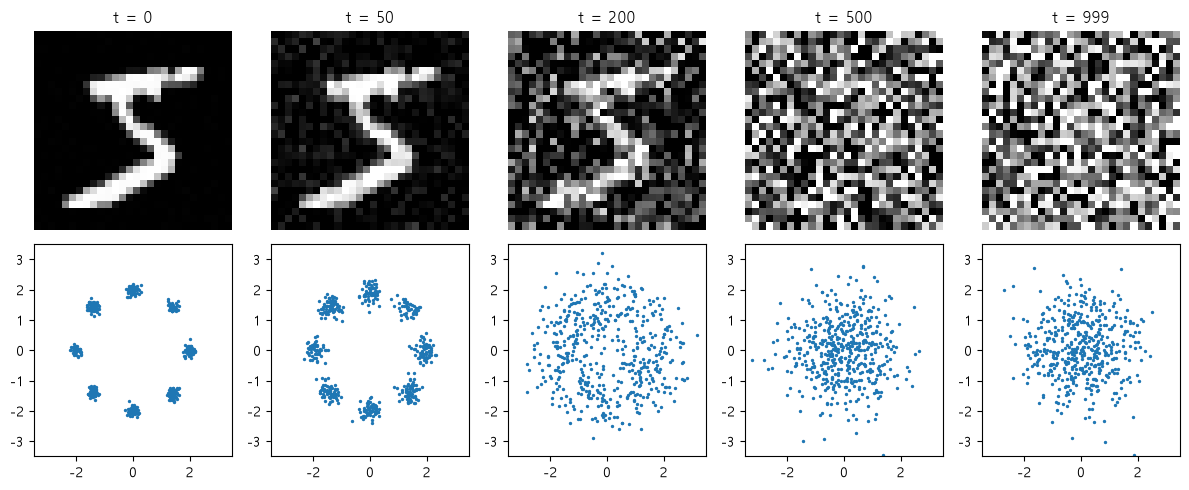

x_T 평균: [-0.058, -0.024] | 표준편차: [0.914, 0.969]


In [29]:
# [보강] 노이즈 일정 (DDPM): β를 0.0001 → 0.02로 1000단계
T = 1000                               # 전체 단계 수
betas = torch.linspace(1e-4, 0.02, T)  # 단계마다 더할 노이즈 양 β_t
alphas = 1 - betas                     # 단계마다 남기는 원본 비율
abar = torch.cumprod(alphas, dim=0)    # ᾱ_t = (1-β_1)(1-β_2)…(1-β_t)


def add_noise(x0, t, gen):                      # x_t = √ᾱ_t · x0 + √(1-ᾱ_t) · ε (한 번에)
    eps = torch.randn(x0.shape, generator=gen)  # 표준 정규 노이즈 ε
    return abar[t].sqrt() * x0 + (1 - abar[t]).sqrt() * eps  # 원본 비중 + 노이즈 비중


show_t = [0, 50, 200, 500, 999]                            # 살펴볼 시점
for t in show_t:                                           # 시점별 두 비중
    print(f"t={t:3} | √ᾱ(원본 비중) {abar[t].sqrt():.4f}"  # 원본이 얼마나 남았나
          f" | √(1-ᾱ)(노이즈 비중) {(1 - abar[t]).sqrt():.4f}")


# MNIST 숫자 1장과 2차원 데이터에 단계별로 노이즈 더하기
gen = torch.Generator().manual_seed(SEED)                # 노이즈 난수 고정
digit = X_mnist[0].view(28, 28)                          # -1 ~ 1
pts = real_2d(500, gen)                                  # 3장의 봉우리 8개 데이터
fig, ax = plt.subplots(2, len(show_t), figsize=(12, 5))  # 위 = 숫자, 아래 = 점
for c, t in enumerate(show_t):                           # 시점마다 한 칸
    ax[0, c].imshow(add_noise(digit, t, gen), cmap="gray", vmin=-1, vmax=1)  # 노이즈 낀 숫자
    xt = add_noise(pts, t, gen)                          # 노이즈 낀 점
    ax[1, c].scatter(xt[:, 0], xt[:, 1], s=2)            # 점 그리기
    ax[1, c].set_xlim(-3.5, 3.5)                         # 같은 축 범위
    ax[1, c].set_ylim(-3.5, 3.5)                         # 퍼지는 정도 비교
    ax[0, c].set_title(f"t = {t}")                       # 시점 표시
    ax[0, c].axis("off")                                 # 이미지 축 숨김
plt.tight_layout()                                       # 간격 정리
plt.show()                                               # 그림 표시


# 마지막 x_T는 거의 표준 정규분포
xT = add_noise(pts, T - 1, gen)                                 # 마지막 시점
print("x_T 평균:", [round(v, 3) for v in xT.mean(0).tolist()],  # 0 근처?
      "| 표준편차:", [round(v, 3) for v in xT.std(0).tolist()])

**결과** · 예측 정답은 아님 — 0.2789, β가 뒤로 갈수록 커져서 절반 지점에 이미 원본이 많이 사라짐

- `t=  0 | √ᾱ(원본 비중) 0.9999 | √(1-ᾱ)(노이즈 비중) 0.0100` — 첫 단계는 노이즈가 아주 조금
- `t=200 | √ᾱ(원본 비중) 0.8102 | √(1-ᾱ)(노이즈 비중) 0.5862` — 숫자 모양은 아직 보임
- `t=500 | √ᾱ(원본 비중) 0.2789 | √(1-ᾱ)(노이즈 비중) 0.9603` — 노이즈가 대부분
- `t=999 | √ᾱ(원본 비중) 0.0064 | √(1-ᾱ)(노이즈 비중) 1.0000` — 원본은 거의 0 → 순수한 노이즈
- `x_T 평균: [-0.058, -0.024] | 표준편차: [0.914, 0.969]` — 평균 0 · 표준편차 1 근처 = 표준 정규분포 → 생성은 여기서 출발

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">전방향 (노이즈 더하기)</td>
<td style="text-align: left;">정해진 식, 학습 없음, x0에서 x_t를 한 번에 계산</td>
<td style="text-align: left;">학습 데이터 만들기 (시점 t 무작위)</td>
</tr>
<tr>
<td style="text-align: left;">√ᾱ_t · √(1-ᾱ_t)</td>
<td style="text-align: left;">원본 비중 · 노이즈 비중, t가 클수록 원본이 사라짐</td>
<td style="text-align: left;">노이즈 일정 설계 (선형 · cosine)</td>
</tr>
<tr>
<td style="text-align: left;">오토인코더의 노이즈 제거</td>
<td style="text-align: left;">노이즈 1단계를 한 번에 복원 (오토인코더-2 참조)</td>
<td style="text-align: left;">복원 · 이상 탐지 (생성 X)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - x_t를 만들 때 1단계부터 t단계까지 반복할 필요 없음 — 식 하나로 x0에서 바로 계산 (그래서 학습 때 t를 무작위로 골라도 빠름)

> ✅ **한 줄 정리** · Diffusion의 전방향은 정해진 일정에 따라 원본 비중 √ᾱ_t를 줄이고 노이즈 비중을 늘려, 마지막에는 표준 정규분포 노이즈만 남긴다.

**딥러닝 코드에서는**

- 학습 한 단계: `t = torch.randint(0, T, (B,))` → `xt = add_noise(x0, t)` → `loss = F.mse_loss(model(xt, t), eps)` (넣은 노이즈 맞히기)

### 4-2. `B` Diffusion 역방향: 노이즈 빼며 생성 · `eps_star` · `1000단계` <sub>개념 위클리 9 Q4 실험 6 · 코드 보강</sub>

> 🎯 **순수한 노이즈에서 노이즈를 단계적으로 빼면 정말 데이터 분포가 나타나며, GAN과 비교해 무엇이 다른가?**

💡 **쉽게 말하면**

- 모래만 남은 판에서 **노이즈 예측기**("여기에 뿌려진 모래는 이만큼"을 맞히는 사람)가 있으면, 1000번에 걸쳐 조금씩 걷어 내 그림을 되살림.
- 매번 조금씩 무작위로 걷어 내서 **매번 다른 그림**이 나옴.

<img src="images/gen1_three_models.png" alt="오토인코더 · GAN · Diffusion이 샘플 하나를 만드는 길" width="806">

**실행 흐름**

1. 데이터가 봉우리 8개라 최적 노이즈 예측기 ε*를 식으로 계산
2. N(0, I) 500개에서 1000단계 역방향
3. 단계별 모습 · 품질 · 봉우리 · 봉우리별 개수

**먼저 예측** · 역방향 생성 결과는 GAN 붕괴처럼 일부 봉우리에 몰릴까? — 답은 코드 실행 결과 아래에

In [30]:
# [보강] 정확한 노이즈 예측기 ε*(x_t, t): 데이터가 봉우리 8개라 식으로 계산
#        (실제 Diffusion은 이 자리에 신경망을 MSE로 학습)
def eps_star(x, t):                                                    # x_t에 들어 있는 노이즈 추정
    a = abar[t]                                                        # 이 시점의 ᾱ
    var = a * 0.1 ** 2 + (1 - a)                                       # x_t의 봉우리별 분산
    mu = a.sqrt() * CENTERS                                            # x_t의 봉우리 중심
    d2 = ((x[:, None, :] - mu[None]) ** 2).sum(-1)                     # (N, 8) 거리²
    w = torch.softmax(-d2 / (2 * var), dim=1)                          # 어느 봉우리에서 왔을 확률
    score = (w[:, :, None] * (mu[None] - x[:, None, :])).sum(1) / var  # 데이터 쪽 방향
    return -(1 - a).sqrt() * score                                     # score → 노이즈 예측


# 역방향: 순수 노이즈에서 출발해 1000단계 동안 노이즈를 조금씩 빼기
gen = torch.Generator().manual_seed(SEED)                                  # 샘플링 난수 고정
x = torch.randn(500, 2, generator=gen)                                     # x_T ~ N(0, I)
snap = {}                                                                  # 중간 모습 저장
for t in reversed(range(T)):                                               # t = 999 → 0
    if t in (999, 500, 200, 50, 0):                                        # 그림에 쓸 시점
        snap[t] = x.clone()                                                # 복사해 보관
    eps = eps_star(x, t)  # 노이즈 예측 (신경망 호출 1번에 해당)
    mean = (x - betas[t] / (1 - abar[t]).sqrt() * eps) / alphas[t].sqrt()  # 노이즈 빼기
    noise = torch.randn(x.shape, generator=gen) if t > 0 else 0            # 마지막엔 안 더함
    x = mean + betas[t].sqrt() * noise                                     # 조금 흔들어 다음 단계로
dist, k = torch.cdist(x, CENTERS).min(dim=1)                               # 가장 가까운 봉우리
good = dist < 0.3                                                          # 3장과 같은 품질 기준
print("생성 500개 · 품질:", round(good.float().mean().item(), 3),          # 품질 · 봉우리 · 호출 수
      "| 봉우리:", int((torch.bincount(k[good], minlength=8) >= 20).sum()),
      "/ 8 | 신경망 호출 수:", T)
print("봉우리별 개수:", torch.bincount(k[good], minlength=8).tolist())     # 고르게 퍼졌나

생성 500개 · 품질: 0.984 | 봉우리: 8 / 8 | 신경망 호출 수: 1000
봉우리별 개수: [62, 73, 53, 59, 69, 62, 62, 52]


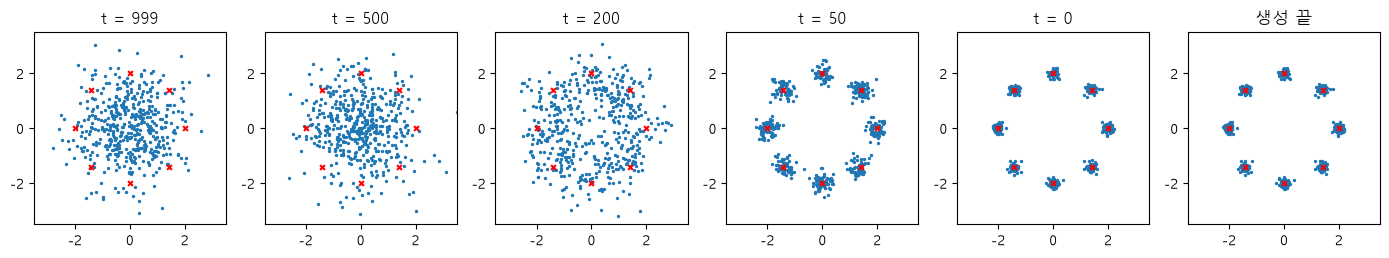

In [31]:
# [보강] 역방향 단계별 모습 그림
fig, ax = plt.subplots(1, len(snap) + 1, figsize=(14, 2.6))             # 저장한 시점 + 마지막
for a, (t, s) in zip(ax, list(snap.items()) + [("생성 끝", x)]):        # 칸마다 한 시점
    a.scatter(s[:, 0], s[:, 1], s=2)                                    # 그 시점의 점
    a.scatter(CENTERS[:, 0], CENTERS[:, 1], c="red", marker="x", s=12)  # 봉우리 중심
    a.set_title(f"t = {t}" if t != "생성 끝" else t)                    # 칸 제목
    a.set_xlim(-3.5, 3.5)                                               # 같은 축 범위
    a.set_ylim(-3.5, 3.5)                                               # 모여드는 모습 비교
    a.set_aspect("equal")                                               # 원 모양 유지
plt.tight_layout()                                                      # 간격 정리
plt.show()                                                              # 그림 표시

**결과** · 예측 정답은 아님 — 8개 봉우리에 52 ~ 73개씩 고르게, 품질 0.984

- `생성 500개 · 품질: 0.984 | 봉우리: 8 / 8 | 신경망 호출 수: 1000` — 모든 봉우리 · 높은 품질, 대신 샘플 하나에 예측 1000번
- `봉우리별 개수: [62, 73, 53, 59, 69, 62, 62, 52]` — 고르면 봉우리마다 약 62개 → 쏠림 없음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">오토인코더 (VAE)</td>
<td style="text-align: left;">인코더 → 잠재 → 디코더, 재구성 + KL, 디코더 1번에 생성</td>
<td style="text-align: left;">안정적 · 빠름, 흐릿해지기 쉬움 (오토인코더-1 · 2)</td>
</tr>
<tr>
<td style="text-align: left;">GAN</td>
<td style="text-align: left;">생성자 vs 판별자 게임, 순전파 1번에 생성</td>
<td style="text-align: left;">선명 · 빠름, 균형 · 모드 붕괴 위험 (2 ~ 4장)</td>
</tr>
<tr>
<td style="text-align: left;">Diffusion</td>
<td style="text-align: left;">넣은 노이즈를 맞히는 MSE, 노이즈에서 수십 ~ 1000단계로 생성</td>
<td style="text-align: left;">품질 · 다양성 최고, 생성이 느림 (Stable Diffusion)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 이 셀의 ε*는 데이터 식을 아는 **정답 예측기**라 학습이 없음
> - 실제로는 신경망을 MSE로 학습해 근사
> - 단계를 줄이면(DDIM 등) 빨라지는 대신 품질 관리가 필요

> ✅ **한 줄 정리** · Diffusion은 노이즈를 한 단계씩 빼는 역방향을 반복해 데이터 분포 전체에서 고르게 샘플을 만들지만, 샘플 하나에 신경망을 수십 ~ 1000번 호출해 느리다.

**딥러닝 코드에서는**

- Stable Diffusion = 이 역방향을 오토인코더의 잠재 공간(64×64×4)에서 하고, 텍스트 조건을 cross-attention으로 넣은 것 (위클리 9 Q4 보충)

---
## 5. 종합 실습 · MNIST 작은 GAN: 정상 vs 모드 붕괴

**GAN 파트 · 3 / 3**

> **이 장의 흐름**
>
> - 2장 학습 단계(2-4 GAN 첫 학습과 같은 MLP) + 3장 균형 · 진단을 실제 이미지에서
> - 3-3에서 2차원 점으로 만든 붕괴(생성자 1:5)를 이미지에서 다시 만듦
> - **숫자 분포 · 다양성 · 선명도** 세 지표로 비교

**파이프라인 위치** · 데이터 → 생성자 · 판별자 → 번갈아 학습 → 고정 z 격자 · 손실 곡선 → 평가 지표

> 🎯 **같은 MNIST GAN에서 생성자만 5배 자주 갱신하면 숫자 종류 · 다양성 · 선명도는 어떻게 달라지는가?**

💡 **쉽게 말하면**

- 생성 품질은 **얼마나 또렷한가**(선명도)와 **얼마나 여러 종류인가**(다양성 · 숫자 분포) 두 축.
- 숫자를 읽는 **평가용 분류기**로 생성 1000장이 어떤 숫자인지 세면 빠진 숫자(모드)가 보임.

<img src="images/gen1_eval_axes.png" alt="생성 품질의 두 축: 선명도 · 다양성" width="574">

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">지표</th>
<th style="text-align: left;">계산</th>
<th style="text-align: left;">무엇을 보나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">숫자 종류</td>
<td style="text-align: left;">평가용 분류기 예측에서 3% 이상인 숫자 수 (10이 최대)</td>
<td style="text-align: left;">모드 누락 (Recall에 해당)</td>
</tr>
<tr>
<td style="text-align: left;">최다 몫</td>
<td style="text-align: left;">가장 많이 나온 숫자의 비율 (고르면 0.1)</td>
<td style="text-align: left;">쏠림 · 붕괴</td>
</tr>
<tr>
<td style="text-align: left;">다양성</td>
<td style="text-align: left;">생성 300장끼리 평균 거리</td>
<td style="text-align: left;">샘플이 서로 다른가</td>
</tr>
<tr>
<td style="text-align: left;">선명도</td>
<td style="text-align: left;">픽셀이 0.1 아래 · 0.9 위인 비율 (흐리면 중간 회색)</td>
<td style="text-align: left;">또렷한가 (Precision에 가까운 감각)</td>
</tr>
</tbody>
</table>

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">같은 조건</th>
<th style="text-align: left;">값</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">데이터 · 배치</td>
<td style="text-align: left;">MNIST 학습 60000장, 배치 128, 10 epoch</td>
</tr>
<tr>
<td style="text-align: left;">모델 · 최적화</td>
<td style="text-align: left;">MLP 생성자(z 64 → 784, Tanh) · MLP 판별자, Adam lr 0.0002 · β₁ 0.5</td>
</tr>
<tr>
<td style="text-align: left;">다른 점</td>
<td style="text-align: left;">판별자 1번당 생성자 1번(정상) vs 5번(생성자 과학습)</td>
</tr>
</tbody>
</table>

**실행 흐름**

1. 3-1에서 점검한 숫자 분류기로 지표 함수 `quality` · 진짜 1000장 기준값 (5-1)
2. `train_mnist(g_steps)` 정의: 2-4 학습에 생성자 반복 · epoch마다 생성 1000장 점검을 더함 (5-2)
3. 정상 1:1 · G 과학습 1:5를 같은 조건으로 학습 · 지표 출력 (5-3)
4. 고정 z 격자 · 숫자 분포 · 손실 · 쏠림 곡선 그림 (5-4)

**먼저 예측** · 생성자 과학습 GAN의 첫 epoch 생성 1000장 중 가장 많은 숫자의 몫은? — 답은 코드 실행 결과 아래에

In [32]:
# [보강] 3-1에서 점검한 숫자 분류기 clf로 생성 이미지 지표 계산 (FID의 Inception 역할)
@torch.no_grad()
def quality(img):                                                          # img: (N, 784), 0 ~ 1
    counts = torch.bincount(clf(img.view(-1, 1, 28, 28)).argmax(1).cpu(),  # 숫자별 개수
                            minlength=10)
    return dict(counts=counts.tolist(),                                    # 지표 5개
                kinds=int((counts >= 0.03 * len(img)).sum()),              # 3% 넘는 숫자
                top=counts.max().item() / len(img),                        # 가장 많은 숫자 몫
                spread=torch.pdist(img[:300]).mean().item(),               # 다양성
                sharp=((img < 0.1) | (img > 0.9)).float().mean().item())   # 선명도


real_q = quality(((X_mnist[:1000] + 1) / 2).to(device))  # 진짜 1000장 = 기준값
print(f"진짜 1000장 기준 | 숫자 {real_q['kinds']}종 | 최다 몫 {real_q['top']:.3f}"  # 비교 기준
      f" | 다양성 {real_q['spread']:.2f} | 선명도 {real_q['sharp']:.3f}")

진짜 1000장 기준 | 숫자 10종 | 최다 몫 0.121 | 다양성 10.04 | 선명도 0.913


In [33]:
# [보강] 2-4의 MLP GAN에 g_steps · epoch마다 점검을 더함: 판별자 1번 · 생성자 g_steps번씩 10 epoch
EPOCHS = 10  # epoch 수 (ZD = 64는 2-4)


def train_mnist(g_steps=1):  # g_steps만 바꿔 같은 조건 학습
    set_seed()                                                           # 두 실험의 출발점을 같게
    G, D = make_G().to(device), make_D().to(device)  # 2-4 · 2-2와 같은 구조 (초기값도 같은 순서)
    og = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))   # GAN 관례 설정
    od = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))   # 같은 lr
    gen = torch.Generator().manual_seed(SEED)                            # 섞기 · z 난수 고정
    fixed_z = torch.randn(16, ZD, generator=gen).to(device)              # 경과 비교용
    X, B = X_mnist.to(device), 128                                       # 데이터 · 배치 크기
    one = torch.ones(B, 1, device=device)                                # 진짜 정답
    log = {"d_loss": [], "g_loss": [], "top": [], "grid": {}}            # epoch별 기록
    for epoch in range(1, EPOCHS + 1):                                   # 10 epoch
        perm = torch.randperm(len(X), generator=gen).to(device)          # 섞은 번호
        d_sum = g_sum = 0.0                                              # epoch 평균 손실용 합계
        for i in range(0, len(X) - B + 1, B):                            # 꽉 찬 배치만
            real = X[perm[i:i + B]]                                      # 진짜 배치
            fake = G(torch.randn(B, ZD, generator=gen).to(device))       # 가짜 배치
            d_loss = bce(D(real), one) + bce(D(fake.detach()), 0 * one)  # ① 판별자 손실
            od.zero_grad()                                               # 기울기 비우기
            d_loss.backward()                                            # 판별자 기울기
            od.step()                                                    # 판별자 갱신
            for _ in range(g_steps):                                     # 생성자 g_steps번
                fake = G(torch.randn(B, ZD, generator=gen).to(device))   # 새 가짜
                g_loss = bce(D(fake), one)                               # ② 가짜를 진짜로
                og.zero_grad()                                           # 기울기 비우기
                g_loss.backward()                                        # D를 거쳐 G까지
                og.step()                                                # 생성자 갱신
            d_sum, g_sum = d_sum + d_loss.item(), g_sum + g_loss.item()  # 손실 누적
        n = len(X) // B                                                  # epoch 안 배치 수
        log["d_loss"].append(d_sum / n)                                  # epoch 평균 판별자 손실
        log["g_loss"].append(g_sum / n)                                  # epoch 평균 생성자 손실
        with torch.no_grad():  # epoch마다 생성 1000장 점검
            z = torch.randn(1000, ZD, generator=gen).to(device)          # 점검용 z
            log["q"] = quality((G(z) + 1) / 2)                           # 0 ~ 1로 바꿔 지표 계산
            log["top"].append(log["q"]["top"])                           # 가장 많은 숫자의 몫
            if epoch in (1, 4, EPOCHS):                                  # 격자를 남길 epoch
                log["grid"][epoch] = ((G(fixed_z) + 1) / 2).cpu()        # 고정 z 16장
    return log                                                           # 기록 전체

In [34]:
# [보강] 정상(1:1) · 생성자 과학습(1:5) 두 GAN을 같은 조건으로 학습 · 점검
logs = {}                                                            # 실험별 기록
for name, g_steps in [("정상 1:1", 1), ("G 과학습 1:5", 5)]:         # 다른 점은 g_steps뿐
    start = time.time()                                              # 학습 시간 재기 시작
    logs[name] = log = train_mnist(g_steps)                          # 10 epoch 학습
    q = log["q"]                                                     # 마지막 epoch 지표
    d, g = log["d_loss"], log["g_loss"]                              # epoch별 손실
    print(f"{name:10} | d_loss {d[0]:.3f} → {d[-1]:.3f}"             # 첫 → 끝 손실 · 시간
          f" | g_loss {g[0]:.3f} → {g[-1]:.3f}"
          f" | {time.time() - start:.0f}초")
    print(f"{'':10} | 숫자 {q['kinds']}종 | 최다 몫 {q['top']:.3f}"  # 지표 4개
          f" | 다양성 {q['spread']:.2f} | 선명도 {q['sharp']:.3f}")
    print(f"{'':10} | 숫자별 개수 {q['counts']}")                    # 숫자 0 ~ 9 분포
    tops = [round(t, 2) for t in log["top"]]                         # epoch별 쏠림
    print(f"{'':10} | epoch별 최다 숫자 몫 {tops}")                  # 붕괴 · 호핑 추적

정상 1:1     | d_loss 0.876 → 0.643 | g_loss 1.482 → 2.603 | 25초
           | 숫자 8종 | 최다 몫 0.182 | 다양성 9.02 | 선명도 0.867
           | 숫자별 개수 [8, 89, 169, 83, 84, 41, 8, 168, 182, 168]
           | epoch별 최다 숫자 몫 [0.84, 0.56, 0.25, 0.22, 0.3, 0.3, 0.21, 0.24, 0.21, 0.18]


G 과학습 1:5  | d_loss 1.417 → 1.384 | g_loss 0.620 → 0.713 | 64초
           | 숫자 7종 | 최다 몫 0.282 | 다양성 9.57 | 선명도 0.948
           | 숫자별 개수 [95, 54, 262, 282, 21, 26, 3, 147, 55, 55]
           | epoch별 최다 숫자 몫 [1.0, 0.99, 0.73, 0.38, 0.44, 0.69, 0.65, 0.48, 0.3, 0.28]


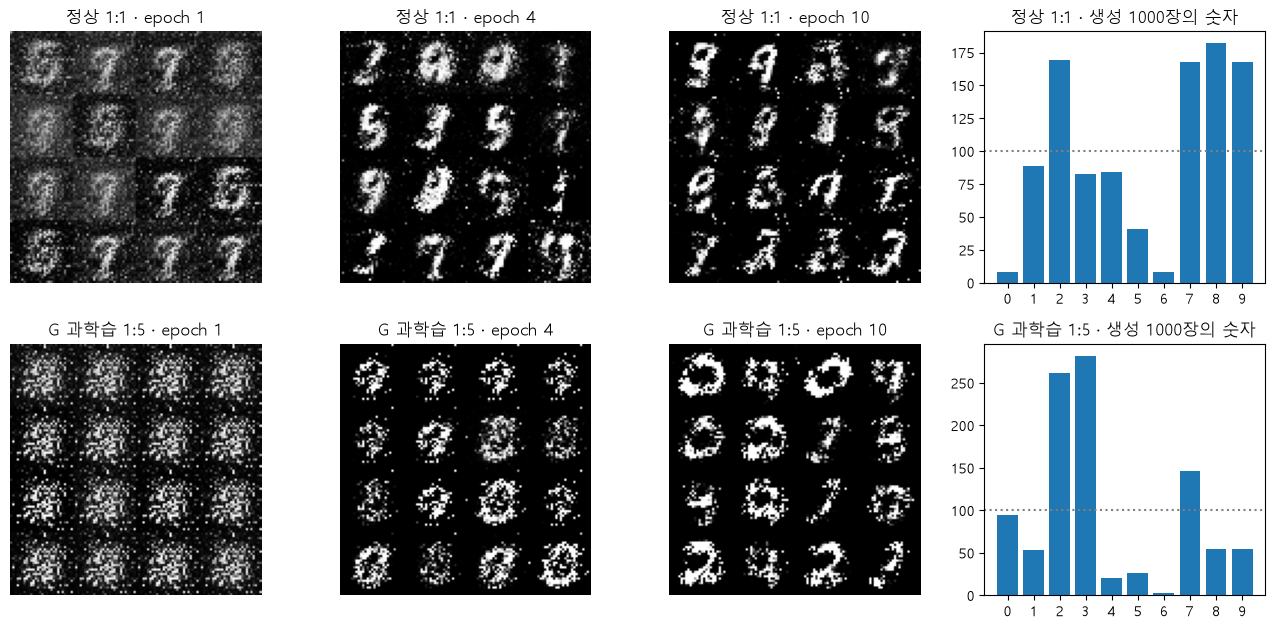

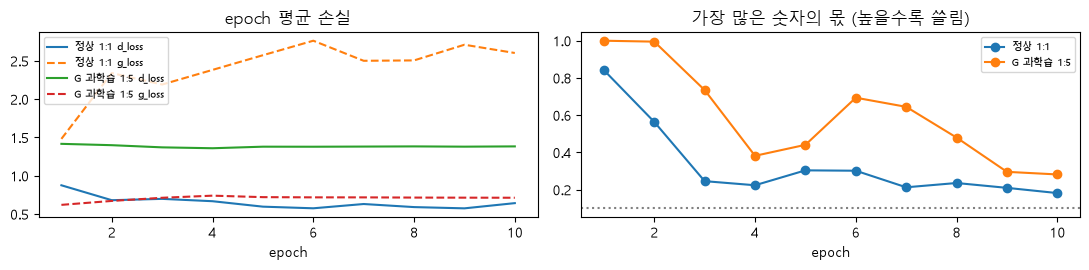

In [35]:
# [보강] 고정 z 16개의 학습 경과 · 손실 곡선 · 숫자 분포
fig, ax = plt.subplots(2, 4, figsize=(13, 6.4))           # 위 = 정상, 아래 = 과학습
for r, (name, log) in enumerate(logs.items()):            # 줄마다 한 실험
    for c, (epoch, g) in enumerate(log["grid"].items()):  # epoch 1 · 4 · 10
        tile = g.view(4, 4, 28, 28).permute(0, 2, 1, 3).reshape(112, 112)  # 16장 → 4×4 격자
        ax[r, c].imshow(tile, cmap="gray")                # 격자 그림
        ax[r, c].set_title(f"{name} · epoch {epoch}")     # 칸 제목
        ax[r, c].axis("off")                              # 축 숨김
    ax[r, 3].bar(range(10), log["q"]["counts"])           # 생성 1000장의 숫자 분포
    ax[r, 3].axhline(100, ls=":", c="gray")               # 고르면 숫자마다 100개
    ax[r, 3].set_xticks(range(10))                        # 0 ~ 9 눈금
    ax[r, 3].set_title(f"{name} · 생성 1000장의 숫자")    # 칸 제목
plt.tight_layout()                                        # 간격 정리
plt.show()                                                # 그림 표시

fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))                  # 손실 · 쏠림 곡선
for name, log in logs.items():                                   # 두 실험 겹쳐 그리기
    ep = range(1, EPOCHS + 1)                                    # x축 epoch
    ax[0].plot(ep, log["d_loss"], label=f"{name} d_loss")        # 판별자 손실
    ax[0].plot(ep, log["g_loss"], "--", label=f"{name} g_loss")  # 생성자 손실 (점선)
    ax[1].plot(ep, log["top"], marker="o", label=name)           # 최다 숫자 몫
ax[0].set_title("epoch 평균 손실")                               # 왼쪽 제목
ax[1].axhline(0.1, ls=":", c="gray")                             # 고르면 숫자마다 0.1
ax[1].set_title("가장 많은 숫자의 몫 (높을수록 쏠림)")           # 오른쪽 제목
for a in ax:                                                     # 두 칸 공통
    a.set_xlabel("epoch")                                        # x축 이름
    a.legend(fontsize=7)                                         # 작은 범례
plt.tight_layout()                                               # 간격 정리
plt.show()                                                       # 그림 표시

**결과** · 예측 정답은 **1.0**

- 첫 epoch에는 1000장이 전부 같은 숫자(완전 붕괴), 2 epoch 0.99
- 이후 쏠리는 숫자가 바뀌며(모드 호핑) 0.28까지 내려옴
- GPU(RTX 3060)에서 실행한 값 · 같은 seed로 두 번 실행해 같은 값 확인 (학습 시간 초는 실행마다 다름)

- `진짜 1000장 기준 | 숫자 10종 | 최다 몫 0.121 | 다양성 10.04 | 선명도 0.913` — 진짜 데이터의 기준값
- `숫자 8종 | 최다 몫 0.182 | 다양성 9.02 | 선명도 0.867` — 정상 1:1, 그럴듯하지만 2종이 3% 미만
- `숫자별 개수 [8, 89, 169, 83, 84, 41, 8, 168, 182, 168]` — 정상 1:1, 0 · 6이 각 8개뿐 = **부분 붕괴**(모드 누락)
- `epoch별 최다 숫자 몫 [0.84, 0.56, 0.25, 0.22, 0.3, 0.3, 0.21, 0.24, 0.21, 0.18]` — 정상 1:1, 초반 쏠림이 점점 풀림
- `숫자 7종 | 최다 몫 0.282 | 다양성 9.57 | 선명도 0.948` — G 과학습 1:5, 종류는 더 적은데 다양성 · 선명도는 오히려 높음
- `숫자별 개수 [95, 54, 262, 282, 21, 26, 3, 147, 55, 55]` — G 과학습 1:5, 2 · 3에 쏠리고 6은 거의 없음
- `epoch별 최다 숫자 몫 [1.0, 0.99, 0.73, 0.38, 0.44, 0.69, 0.65, 0.48, 0.3, 0.28]` — G 과학습 1:5, 완전 붕괴로 시작 · 오르내림 = 모드 호핑

**세 모델 비교**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">지표</th>
<th style="text-align: left;">진짜</th>
<th style="text-align: left;">정상 1:1</th>
<th style="text-align: left;">G 과학습 1:5</th>
<th style="text-align: left;">읽는 법</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">숫자 종류</td>
<td style="text-align: left;">10</td>
<td style="text-align: left;">8</td>
<td style="text-align: left;">7</td>
<td style="text-align: left;">둘 다 모드 누락, 1:5가 더 심함</td>
</tr>
<tr>
<td style="text-align: left;">최다 몫</td>
<td style="text-align: left;">0.121</td>
<td style="text-align: left;">0.182</td>
<td style="text-align: left;">0.282</td>
<td style="text-align: left;">1:5가 더 쏠림</td>
</tr>
<tr>
<td style="text-align: left;">다양성</td>
<td style="text-align: left;">10.04</td>
<td style="text-align: left;">9.02</td>
<td style="text-align: left;">9.57</td>
<td style="text-align: left;"><strong>픽셀 거리만으로는 붕괴를 놓침</strong> (1:5가 더 높음)</td>
</tr>
<tr>
<td style="text-align: left;">선명도</td>
<td style="text-align: left;">0.913</td>
<td style="text-align: left;">0.867</td>
<td style="text-align: left;">0.948</td>
<td style="text-align: left;">또렷함과 다양성은 별개</td>
</tr>
<tr>
<td style="text-align: left;">판별자 손실 끝값</td>
<td style="text-align: left;">기준 1.386</td>
<td style="text-align: left;">0.643</td>
<td style="text-align: left;">1.384</td>
<td style="text-align: left;">1:5는 판별자가 따라오지 못해 반반 상태</td>
</tr>
</tbody>
</table>

**그림 읽는 법**

- 위 줄 = 정상, 아래 줄 = G 과학습 · 같은 고정 z 16개로 epoch 1 · 4 · 10을 그린 격자
- G 과학습의 epoch 1은 16칸이 거의 같은 모양(완전 붕괴), 정상은 epoch 1부터 여러 모양
- 막대그래프 = 생성 1000장의 숫자 분포 (점선 = 고르면 100개)
- 아래 그래프 왼쪽 = epoch 평균 손실, 오른쪽 = 최다 숫자 몫 (점선 0.1 = 고름)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">숫자 분포 (분류기)</td>
<td style="text-align: left;">어떤 종류가 빠졌는지 직접 보임, 평가용 분류기가 필요</td>
<td style="text-align: left;">모드 누락 진단 (FID의 Inception 특징과 같은 발상)</td>
</tr>
<tr>
<td style="text-align: left;">다양성 (평균 거리)</td>
<td style="text-align: left;">계산이 쉽지만 픽셀 차이라 종류 누락을 놓칠 수 있음</td>
<td style="text-align: left;">학습 중 빠른 경고 (계속 줄면 붕괴)</td>
</tr>
<tr>
<td style="text-align: left;">선명도</td>
<td style="text-align: left;">흐림 · 또렷함만 봄, 종류는 모름</td>
<td style="text-align: left;">품질 축 (Precision에 가까운 감각)</td>
</tr>
<tr>
<td style="text-align: left;">고정 z 격자</td>
<td style="text-align: left;">같은 z의 시점별 변화 → 호핑 · 붕괴가 눈에 보임</td>
<td style="text-align: left;">체크포인트마다 저장해 나란히 비교</td>
</tr>
<tr>
<td style="text-align: left;">FID · Precision · Recall</td>
<td style="text-align: left;">특징 공간에서 분포 비교 (위클리 11 실험 3)</td>
<td style="text-align: left;">논문 · 보고용 표준 지표</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 정상 1:1도 숫자 0 · 6을 거의 만들지 않음
> - 분류기는 숫자가 아닌 그림에도 숫자를 붙임(3-1) → epoch 1의 몫 1.0은 고정 z 격자로도 같은 모양인지 확인
> - "그럴듯한 이미지가 나온다"만으로 정상이라 판단하지 말고, 종류 분포까지 확인

> ✅ **한 줄 정리** · 생성 품질은 선명도와 다양성 두 축으로 보며, 모드 붕괴는 손실이나 픽셀 거리보다 생성 결과의 종류 분포와 고정 z 격자에서 가장 잘 드러난다.

**딥러닝 코드에서는**

- 프로젝트에서는 epoch마다 `fixed_z` 격자 이미지와 다양성 수치를 저장
- 끝난 뒤 FID(`torchmetrics.image.fid` 등)로 비교
- 대응은 3-4처럼 한 번에 하나씩 바꿔 효과를 확인

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">학습 목표</th>
<th style="text-align: left;">할 수 있게 된 것</th>
<th style="text-align: left;">확인 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1. 단순한 생성의 한계</td>
<td style="text-align: left;">규칙 하나 → 빈 띠 26% · 칸마다 따로 → 한 칸만 밝음 1031장(진짜 259장) · AE 좌표 퍼짐 3.8 ~ 5.3</td>
<td style="text-align: left;">1-1 ~ 1-3</td>
</tr>
<tr>
<td style="text-align: left;">2. 학습 한 단계 · 틀린 코드</td>
<td style="text-align: left;"><code>detach</code>를 빼면 RuntimeError · oG에 D를 넘기면 에러 없이 G 변화 0.0</td>
<td style="text-align: left;">2-2 · 2-3 · 2-5</td>
</tr>
<tr>
<td style="text-align: left;">3. 손실 vs 그림</td>
<td style="text-align: left;">epoch 10 생성자 손실 2.889로 가장 큰 무렵에도 그림은 숫자 · 1차원은 손실 정상인데 봉우리 3%</td>
<td style="text-align: left;">2-4 · 2-6 · 2-7</td>
</tr>
<tr>
<td style="text-align: left;">4. 도구 점검 · 실패 진단</td>
<td style="text-align: left;">무작위 사진 78장을 8로(확신 0.82) · D 강함 3/8 · G 1:5 다양성 0.1749 → MinibatchStdDev 8/8</td>
<td style="text-align: left;">3-1 ~ 3-4</td>
</tr>
<tr>
<td style="text-align: left;">5. Diffusion · 두 축 평가</td>
<td style="text-align: left;">t = 500 원본 비중 0.2789 · 정상 8종 vs 1:5 7종, 픽셀 다양성은 1:5가 더 높음</td>
<td style="text-align: left;">4-1 · 4-2 · 5</td>
</tr>
</tbody>
</table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">등급</th>
<th style="text-align: left;">주제</th>
<th style="text-align: left;">반드시 기억할 것</th>
<th style="text-align: left;">코드에서</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">생성 = 규칙 배워 뽑기</td>
<td style="text-align: left;">노이즈 → 변환 → 데이터, 규칙이 단순하면 빈 곳에도 뽑힘</td>
<td style="text-align: left;"><code>randn @ cholesky(cov).T + mean</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">평균은 흐림</td>
<td style="text-align: left;">칸마다 비교(MSE)는 여러 정답의 평균 쪽으로</td>
<td style="text-align: left;"><code>X.mean(0)</code> · VAE 디코더</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">AE vs VAE</td>
<td style="text-align: left;">AE 좌표는 흩어짐, VAE는 KL로 표준정규에 맞춤</td>
<td style="text-align: left;"><code>vae.dec(torch.randn(n, 8))</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">역할</td>
<td style="text-align: left;">생성자 z → 가짜, 판별자 데이터 → 진짜 점수</td>
<td style="text-align: left;"><code>G(torch.randn(n, z_dim))</code> · <code>D(x)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">손실 짝</td>
<td style="text-align: left;">로짓 + BCEWithLogitsLoss 또는 점수 + BCELoss</td>
<td style="text-align: left;"><code>nn.BCEWithLogitsLoss()</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">학습 한 단계</td>
<td style="text-align: left;">판별자(가짜 detach) → 생성자 번갈아, 각자의 step</td>
<td style="text-align: left;"><code>bce(D(fake.detach()), 0)</code> · <code>bce(D(fake), 1)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">고치는 대상</td>
<td style="text-align: left;">backward는 누적 계산, 바뀌는 건 optimizer에 넘긴 가중치</td>
<td style="text-align: left;"><code>Adam(G.parameters())</code> · <code>zero_grad()</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">생성자 손실</td>
<td style="text-align: left;">-log D(G(z)) (non-saturating)</td>
<td style="text-align: left;"><code>bce(D(fake), ones)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">손실 읽기</td>
<td style="text-align: left;">손실 숫자 ≠ 그림 품질, 고정 노이즈 격자로 확인</td>
<td style="text-align: left;"><code>FIXED</code> · <code>d_loss</code> · <code>g_loss</code> 기록</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">DCGAN</td>
<td style="text-align: left;">전치 합성곱으로 7 → 14 → 28, 범위는 Normalize ↔ Tanh</td>
<td style="text-align: left;"><code>nn.ConvTranspose2d(128, 64, 4, 2, 1)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">도구 점검</td>
<td style="text-align: left;">답을 아는 입력(진짜 · 반복 · 무작위)으로 먼저</td>
<td style="text-align: left;"><code>clf</code> · <code>torch.bincount</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">균형</td>
<td style="text-align: left;">판별자 너무 강함 · 약함 모두 실패</td>
<td style="text-align: left;">D:G 갱신 비 · lr</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">모드 붕괴</td>
<td style="text-align: left;">z가 달라도 같은 출력, 분포 · 격자로 진단</td>
<td style="text-align: left;"><code>torch.pdist</code> · 분류기 분포 · <code>fixed_z</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">Diffusion 전방향</td>
<td style="text-align: left;">x_t = √ᾱ·x0 + √(1-ᾱ)·ε, 끝은 순수 노이즈</td>
<td style="text-align: left;"><code>add_noise(x0, t)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">대응</td>
<td style="text-align: left;">Minibatch StdDev · 정규화 · TTUR, 하나씩</td>
<td style="text-align: left;"><code>MinibatchStdDev()</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">Diffusion 역방향</td>
<td style="text-align: left;">노이즈 예측을 조금씩 빼기, 느리지만 고르게</td>
<td style="text-align: left;">DDPM 샘플러 1000단계</td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">지표</td>
<td style="text-align: left;">선명도 · 다양성 두 축, FID · Precision · Recall</td>
<td style="text-align: left;">분류기 숫자 분포</td>
</tr>
</tbody>
</table>

---
## 기억 확인 문제

- 위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시
- △ · ×인 섹션만 다시 보기

### 1. 질문에 답하기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">🎯 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">규칙 하나(가운데 · 퍼진 모양)로 덩어리 둘인 데이터를 배워 뽑으면 무엇이 문제인가?</td>
</tr>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">784칸을 칸마다 따로 뽑거나 사진을 평균 내면 왜 숫자가 안 되거나 흐린가?</td>
</tr>
<tr>
<td style="text-align: left;">1-3</td>
<td style="text-align: left;">AE 디코더와 VAE 디코더에 표준정규 노이즈를 넣으면 각각 어떻게 되는가?</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">생성자와 판별자는 각각 무엇을 입력받아 무엇을 내는가?</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">판별자 끝 출력과 손실 함수는 어떻게 짝을 맞추는가?</td>
</tr>
<tr>
<td style="text-align: left;">2-3</td>
<td style="text-align: left;">판별자 갱신 때 detach를 하는 이유와, 생성자 손실로 -log D(G(z))를 쓰는 이유는?</td>
</tr>
<tr>
<td style="text-align: left;">2-4</td>
<td style="text-align: left;">생성자 손실이 커지면 그림이 나빠지는가?</td>
</tr>
<tr>
<td style="text-align: left;">2-5</td>
<td style="text-align: left;">detach를 빼거나 oG에 D의 가중치를 넘기면 각각 무슨 일이 생기는가?</td>
</tr>
<tr>
<td style="text-align: left;">2-6</td>
<td style="text-align: left;">GAN 손실 곡선이 균형점 근처면 학습이 잘 된 것인가?</td>
</tr>
<tr>
<td style="text-align: left;">2-7</td>
<td style="text-align: left;">DCGAN 생성자는 모양을 어떻게 키우며, 진짜 사진 범위는 왜 -1 ~ 1로 맞추는가?</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">생성 이미지를 숫자 분류기로 세기 전에 무엇을 하는가?</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">판별자가 너무 강할 때와 너무 약할 때 각각 무슨 일이 생겼나?</td>
</tr>
<tr>
<td style="text-align: left;">3-3</td>
<td style="text-align: left;">모드 붕괴는 무엇이고 어떤 수치로 알아보는가?</td>
</tr>
<tr>
<td style="text-align: left;">3-4</td>
<td style="text-align: left;">Minibatch StdDev는 어떻게 모드 붕괴를 줄이는가?</td>
</tr>
<tr>
<td style="text-align: left;">4-1</td>
<td style="text-align: left;">전방향 과정에서 t가 커지면 무엇이 남는가?</td>
</tr>
<tr>
<td style="text-align: left;">4-2</td>
<td style="text-align: left;">Diffusion은 GAN · 오토인코더와 무엇이 다른가?</td>
</tr>
<tr>
<td style="text-align: left;">5</td>
<td style="text-align: left;">생성 품질을 볼 두 축과, 모드 붕괴를 가장 잘 보여 준 지표는?</td>
</tr>
</tbody>
</table>

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-5** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-6** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-7** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

아래 빈 셀에 직접 작성 후 실행.

1. 판별자 로짓 `torch.tensor([[0.0]])`(확률 0.5)에 진짜 라벨 1을 준 `BCEWithLogitsLoss` 값을 소수 넷째 자리로 출력
2. `x = torch.tensor([[0., 0.], [3., 4.]])` 두 점의 평균 거리(`torch.pdist`)를 출력
3. `betas = torch.linspace(1e-4, 0.02, 1000)`에서 t = 999의 √ᾱ를 소수 넷째 자리로 출력
4. 생성 숫자 개수 `torch.tensor([0, 50, 950])`에서 가장 많은 숫자의 몫을 출력
5. `nn.ConvTranspose2d(128, 64, 4, 2, 1)`에 `torch.zeros(1, 128, 7, 7)`을 넣은 출력 모양을 출력

In [36]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. 2-3의 기울기 비교를 **D(G(z)) = 0.3**에서 하면 원래 식 · non-saturating 기울기 크기는 각각? 예측 → 실행
2. 4-1의 노이즈 일정에서 원본 비중 √ᾱ가 **처음으로 0.5 아래**로 내려가는 t는? (t = 500이 이미 0.2789였음)
3. 3-4의 `MinibatchStdDev`에 **(0, 0)과 (2, 0)이 반씩** 든 64개 배치를 넣으면 붙는 특징 값은? 손으로 먼저 계산
4. 2-5의 기울기 쌓임을 **w에 5를 곱하는 계산으로 바꿔 backward를 3번** 하면 `w.grad`는? 예측 → 실행

In [37]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">데이터가 없는 가운데 빈 띠에도 뽑힘 (26%), 덩어리마다 따로 배우면 0%</td>
</tr>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">칸끼리 함께 움직이는 관계를 버려 모래가 되고, 사진마다 다른 칸의 평균은 둘 다 아닌 회색</td>
</tr>
<tr>
<td style="text-align: left;">1-3</td>
<td style="text-align: left;">AE는 좌표가 흩어져 있어(퍼짐 3.8 ~ 5.3) 엉뚱한 그림, VAE는 KL로 좌표를 0 · 1에 맞춰 숫자가 나오지만 흐림</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">생성자 = z → 가짜 데이터, 판별자 = 데이터 → 진짜일 점수(로짓)</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">로짓이면 BCEWithLogitsLoss, sigmoid 점수면 BCELoss · 섞으면 sigmoid 두 번(에러 없이 다른 값)</td>
</tr>
<tr>
<td style="text-align: left;">2-3</td>
<td style="text-align: left;">detach는 판별자 손실이 생성자 쪽으로 가지 않게, -log D(G(z))는 초반(들킬 때)에도 기울기가 커서</td>
</tr>
<tr>
<td style="text-align: left;">2-4</td>
<td style="text-align: left;">아님. epoch 10 생성자 손실이 2.889로 컸지만 그림은 숫자 모양 → 고정 노이즈 그림으로 확인</td>
</tr>
<tr>
<td style="text-align: left;">2-5</td>
<td style="text-align: left;">detach 빼기 = 생성자 차례에 RuntimeError, oG에 D = 에러 없이 G 가중치 변화 0.0 (D만 바뀜)</td>
</tr>
<tr>
<td style="text-align: left;">2-6</td>
<td style="text-align: left;">아님. 1차원 실험은 손실이 균형 근처인데 가운데 봉우리가 3%뿐 → 샘플을 봐야 함</td>
</tr>
<tr>
<td style="text-align: left;">2-7</td>
<td style="text-align: left;">전치 합성곱(커널 4 · 보폭 2 · 패딩 1)으로 7 → 14 → 28, Tanh 출력과 범위가 다르면 판별자가 범위로 가려냄</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">진짜 · 같은 사진 반복 · 무작위 사진으로 도구 점검 → 무작위도 8로 높은 확신 → 그림을 함께 봄</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">강함 = 봉우리 3/8만 (품질은 높음), 약함 = 품질 0 (생성자가 못 배움)</td>
</tr>
<tr>
<td style="text-align: left;">3-3</td>
<td style="text-align: left;">z가 달라도 출력이 몇 가지로 몰림, 배치 다양성(평균 거리)이 진짜보다 크게 작음 (0.1749 vs 2.5395)</td>
</tr>
<tr>
<td style="text-align: left;">3-4</td>
<td style="text-align: left;">배치 안 표준편차를 판별자 특징으로 붙여, 단조로운 배치를 가짜로 알아보게 함 (1/8 → 8/8)</td>
</tr>
<tr>
<td style="text-align: left;">4-1</td>
<td style="text-align: left;">원본 비중 √ᾱ가 0으로 줄고 표준 정규분포 노이즈만 남음</td>
</tr>
<tr>
<td style="text-align: left;">4-2</td>
<td style="text-align: left;">경쟁 없이 넣은 노이즈를 맞히는 MSE로 학습, 품질 · 다양성은 높지만 생성에 수십 ~ 1000단계</td>
</tr>
<tr>
<td style="text-align: left;">5</td>
<td style="text-align: left;">선명도 · 다양성. 붕괴는 숫자 분포(최다 몫 · 종류)와 고정 z 격자에서 가장 잘 보임 (픽셀 거리는 놓침)</td>
</tr>
</tbody>
</table>

#### 코드 문제 답

```python
# 1. 확률 0.5에 정답 1 → -log 0.5 = ln2
loss = nn.BCEWithLogitsLoss()(torch.tensor([[0.0]]), torch.tensor([[1.0]]))
print(round(loss.item(), 4))  # 0.6931

# 2. 두 점 (0, 0) · (3, 4)의 거리
print(torch.pdist(torch.tensor([[0., 0.], [3., 4.]])).tolist())  # [5.0]

# 3. 마지막 시점의 원본 비중
betas = torch.linspace(1e-4, 0.02, 1000)
print(round(torch.cumprod(1 - betas, 0)[999].sqrt().item(), 4))  # 0.0064

# 4. 가장 많은 숫자의 몫
counts = torch.tensor([0, 50, 950])
print(round((counts.max() / counts.sum()).item(), 2))  # 0.95

# 5. 전치 합성곱(커널 4 · 보폭 2 · 패딩 1)은 가로세로 두 배
up = nn.ConvTranspose2d(128, 64, 4, 2, 1)
print(tuple(up(torch.zeros(1, 128, 7, 7)).shape))  # (1, 64, 14, 14)
```

#### 변형 문제 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">문제</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">원래 식 0.30 · non-saturating 0.70 (원래 식 기울기 = p, non-saturating = 1 - p)</td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">t = 368 (√ᾱ 0.4984, 바로 앞 t = 367은 0.5002)</td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">0.5 — 첫 축 표준편차 1(값 0 · 2가 반씩), 둘째 축 0 → 평균 (1 + 0) ÷ 2</td>
</tr>
<tr>
<td style="text-align: left;">4</td>
<td style="text-align: left;">15.0 — 한 번에 5씩 세 번 쌓임 (zero_grad 없이)</td>
</tr>
</tbody>
</table>

---
## 오답 노트

- 틀린 문제는 정답을 베끼지 말고 **원인**을 적음
- 다음 복습 때 이 표의 "재발 방지 질문"부터 스스로에게 물어보기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">틀린 내용</th>
<th style="text-align: left;">틀린 이유</th>
<th style="text-align: left;">올바른 원칙</th>
<th style="text-align: left;">재발 방지 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">(예) 손실이 균형점이라 학습 성공이라고 답함</td>
<td style="text-align: left;">손실을 품질 지표로 착각</td>
<td style="text-align: left;">GAN 손실은 상대적, 품질은 샘플 · 분포로</td>
<td style="text-align: left;">생성 결과 그림 · 종류 분포를 봤나?</td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
</tbody>
</table>

---
## 면접 30초 답변

**Q1. GAN에서 생성자와 판별자의 역할은 무엇인가요?**
> - 생성자는 정규분포에서 뽑은 잠재 벡터를 받아 가짜 데이터를 만들고, 판별자는 입력이 진짜일 확률을 내는 이진 분류기입니다.
> - 판별자는 진짜를 1, 가짜를 0으로 맞히도록, 생성자는 판별자가 가짜를 진짜라고 하도록 번갈아 학습합니다.
> - 생성자는 진짜 데이터를 직접 보지 않고 판별자를 거친 기울기로만 배우며, 학습 후 생성에는 생성자만 씁니다.

**Q2. GAN 학습이 잘 되는지는 손실로 알 수 있나요?**
> - 두 손실은 서로 상대적이라 품질의 척도가 아닙니다.
> - 제 1차원 실험에서 판별자 손실이 균형점 근처였는데도 봉우리 3개 중 가운데 하나를 거의 만들지 않았습니다.
> - 판별자가 약한 설정은 손실이 정상과 거의 같은데 품질이 0이었습니다.
> - 그래서 고정 z 샘플 그림, 다양성 수치, FID 같은 별도 지표를 함께 봅니다.

**Q3. 모드 붕괴는 무엇이고 어떻게 대응하나요?**
> - 서로 다른 잠재 벡터를 넣어도 몇 가지 비슷한 출력만 나오는 현상입니다.
> - 생성자 손실은 샘플이 진짜 같은지만 묻고 서로 다른지는 묻지 않기 때문에, 판별자를 가장 잘 속이는 몇 곳으로 몰립니다.
> - 먼저 데이터 · z 샘플링 오류를 점검하고, 생성자 · 판별자 균형을 맞춥니다.
> - 그다음 판별자에 Minibatch StdDev 같은 다양성 장치를 넣습니다.
> - 2차원 실험에서 이 장치만으로 봉우리 1개가 8개로 돌아왔습니다.

**Q4. Diffusion 모델이 GAN보다 안정적인 이유는요?**
> - Diffusion은 데이터에 정해진 일정으로 노이즈를 더해 두고, 신경망이 넣은 노이즈를 맞히는 MSE 회귀 하나를 학습합니다.
> - 상대가 움직이는 미니맥스 게임이 없어 학습이 안정적이고, 데이터 전체를 덮도록 학습돼 모드 붕괴가 드뭅니다.
> - 대신 생성할 때 노이즈를 수십 ~ 1000단계에 걸쳐 빼야 해서 느립니다.
> - DDIM이나 잠재 공간 확산으로 단계 수나 단계당 계산을 줄입니다.

**Q5. GAN 학습 코드에서 에러 없이 틀리는 실수는 어떻게 찾나요?**
> - backward는 기울기를 계산해 더할 뿐이고, 실제로 바뀌는 가중치는 optimizer에 넘긴 것입니다.
> - 그래서 생성자 optimizer에 판별자 가중치를 넘기면 에러 없이 손실은 내려가는데 생성자는 그대로입니다.
> - 저는 묶음 50개 실험에서 생성자 첫 층 가중치 변화가 0.0인 것으로 이 버그를 확인했습니다.
> - 판별자 차례에 detach를 빼면 반대로 생성자 차례에서 RuntimeError가 납니다.
> - 그래서 학습 전후 가중치 변화를 재고, 고정 노이즈 그림으로 학습을 확인합니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
<th style="text-align: left;">코드에서 사용한 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>torch.cov(x.T)</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">점 무리의 퍼진 모양 (공분산)</td>
<td style="text-align: left;">1-1 <code>center, cov = pts_a.mean(0), torch.cov(pts_a.T)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.linalg.cholesky(cov)</code></td>
<td style="text-align: left;">torch.linalg</td>
<td style="text-align: left;">동그란 점을 퍼진 모양대로 늘리고 기울이는 변환</td>
<td style="text-align: left;">1-1 <code>L = torch.linalg.cholesky(cov)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>x.mean(0)</code> · <code>x.std(0)</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">칸마다 가운데 · 퍼짐 (사진 6만 장)</td>
<td style="text-align: left;">—</td>
</tr>
<tr>
<td style="text-align: left;"><code>vae.dec(torch.randn(n, 8))</code></td>
<td style="text-align: left;">보강 모델</td>
<td style="text-align: left;">표준정규 노이즈 → 디코더 → 숫자 (VAE)</td>
<td style="text-align: left;">1-3b <code>"VAE · 노이즈 그대로": vae.dec(noise)}</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.BCEWithLogitsLoss()</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">로짓 + 이진 교차 엔트로피 (판별자 · 생성자 손실)</td>
<td style="text-align: left;">2-2 <code>print(f"{'값 → BCEWithLogitsLoss':26} {nn.BCEWithLo…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.LeakyReLU(0.2)</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">판별자 활성화 (음수를 0.2배로 남김)</td>
<td style="text-align: left;">2-1 <code>D1 = mlp(1, 1, nn.LeakyReLU(0.2))</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>fake.detach()</code></td>
<td style="text-align: left;">torch.Tensor</td>
<td style="text-align: left;">판별자 갱신 때 생성자로 가는 계산 연결 끊기</td>
<td style="text-align: left;">2-3 <code>d_loss = bce(D1(real), ones) + bce(D1(fake.detach(…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>opt.zero_grad()</code> · <code>.backward()</code> · <code>opt.step()</code></td>
<td style="text-align: left;">torch.optim</td>
<td style="text-align: left;">비우기 → 기울기 계산(누적) → 넘긴 가중치만 고치기</td>
<td style="text-align: left;">2-2b <code>opt.zero_grad()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.optim.Adam(betas=(0.5, 0.999))</code></td>
<td style="text-align: left;">torch.optim</td>
<td style="text-align: left;">GAN 관례 설정 (모멘텀 작게)</td>
<td style="text-align: left;">2-2b <code>opt = torch.optim.Adam(D_demo.parameters(), lr=2e-…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.sigmoid(D(x))</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">로짓 → 진짜일 확률</td>
<td style="text-align: left;">2-1 <code>round(torch.sigmoid(D1(real)).mean().item(), 4),</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.logit()</code> · <code>.grad</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">확률 → 로짓, 기울기 크기 확인</td>
<td style="text-align: left;">2-3 <code>s = torch.logit(torch.tensor(p)).requires_grad_()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>train_gan(G, D, X, epochs, lr_d)</code></td>
<td style="text-align: left;">보강 함수</td>
<td style="text-align: left;">번갈아 학습 · epoch별 손실 · 점수 · 고정 노이즈 그림</td>
<td style="text-align: left;">2-4 <code>def train_gan(G, D, X, epochs, lr_d=2e-4, keep=()):</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.ConvTranspose2d(c_in, c_out, 4, 2, 1)</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">가로세로 두 배로 키우는 전치 합성곱 (DCGAN 생성자)</td>
<td style="text-align: left;">2-7 <code>nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>clf(x).argmax(1)</code> · <code>torch.bincount</code></td>
<td style="text-align: left;">보강 모델 · torch</td>
<td style="text-align: left;">생성 이미지를 숫자로 세기 (도구 점검 먼저)</td>
<td style="text-align: left;">3-1 <code>clf = nn.Sequential(</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>train_2d(d_steps, g_steps, lr_d, mbstd)</code></td>
<td style="text-align: left;">보강 함수</td>
<td style="text-align: left;">균형 · 장치만 바꿔 같은 조건 학습</td>
<td style="text-align: left;">3-2b <code>def train_2d(d_steps=1, g_steps=1, lr_d=1e-3, lr_g…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.cdist(x, centers).min(dim=1)</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">가장 가까운 봉우리 · 거리 (품질 · 봉우리 수)</td>
<td style="text-align: left;">3-2b <code>dist, k = torch.cdist(x, CENTERS).min(dim=1)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.pdist(x).mean()</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">배치 안 샘플끼리 평균 거리 (다양성)</td>
<td style="text-align: left;">3-2b <code>spread = torch.pdist(x[:500]).mean().item()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>MinibatchStdDev</code></td>
<td style="text-align: left;">보강 모듈 (ProGAN 방식)</td>
<td style="text-align: left;">배치 표준편차를 판별자 특징으로</td>
<td style="text-align: left;">3-2 <code>class MinibatchStdDev(nn.Module):</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.linspace(1e-4, 0.02, 1000)</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">DDPM 노이즈 일정 β</td>
<td style="text-align: left;">4-1 <code>betas = torch.linspace(1e-4, 0.02, T)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.cumprod(1 - betas, 0)</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">ᾱ_t 누적 곱</td>
<td style="text-align: left;">4-1 <code>abar = torch.cumprod(alphas, dim=0)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>add_noise(x0, t)</code></td>
<td style="text-align: left;">보강 함수</td>
<td style="text-align: left;">x0에서 x_t를 한 번에</td>
<td style="text-align: left;">4-1 <code>def add_noise(x0, t, gen):</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>eps_star(x, t)</code> · 역방향 반복</td>
<td style="text-align: left;">보강 함수</td>
<td style="text-align: left;">노이즈 예측 → 조금씩 빼기 (DDPM 샘플러)</td>
<td style="text-align: left;">4-2 <code>def eps_star(x, t):</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>quality(img)</code></td>
<td style="text-align: left;">보강 함수</td>
<td style="text-align: left;">생성 이미지의 숫자 종류 · 최다 몫 · 다양성 · 선명도</td>
<td style="text-align: left;">5-1 <code>def quality(img):</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.bincount(pred, minlength=10)</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">숫자별 개수 (빠진 숫자 = 0에 가까움)</td>
<td style="text-align: left;">5-1 <code>counts = torch.bincount(clf(img.view(-1, 1, 28, 28…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>fixed_z</code></td>
<td style="text-align: left;">보강 변수</td>
<td style="text-align: left;">같은 z로 epoch마다 격자를 그려 경과 비교</td>
<td style="text-align: left;">5-2 <code>fixed_z = torch.randn(16, ZD, generator=gen).to(de…</code></td>
</tr>
</tbody>
</table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">✅ 할 것</th>
<th style="text-align: left;">⚠️ 하지 말 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">판별자 갱신은 <code>fake.detach()</code></td>
<td style="text-align: left;">생성자 단계에서 판별자도 <code>step()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>oG = Adam(G.parameters())</code> 이름 · 대상 확인</td>
<td style="text-align: left;"><code>oG</code>에 <code>D.parameters()</code> 넘기기</td>
</tr>
<tr>
<td style="text-align: left;">진짜 사진 범위를 Tanh(-1 ~ 1)와 맞추기</td>
<td style="text-align: left;">진짜 0 ~ 1 · 생성자 -1 ~ 1</td>
</tr>
<tr>
<td style="text-align: left;">세는 도구는 답을 아는 입력으로 먼저 점검</td>
<td style="text-align: left;">분류기가 센 숫자를 그대로 믿기</td>
</tr>
<tr>
<td style="text-align: left;">판별자는 로짓 + <code>BCEWithLogitsLoss</code></td>
<td style="text-align: left;">sigmoid 두 번</td>
</tr>
<tr>
<td style="text-align: left;">고정 z 격자를 epoch마다 저장</td>
<td style="text-align: left;">손실만 보고 성공 · 실패 판단</td>
</tr>
<tr>
<td style="text-align: left;">z는 배치마다 새로 뽑기</td>
<td style="text-align: left;">z를 루프 밖에서 한 번만</td>
</tr>
<tr>
<td style="text-align: left;">대응 기법은 하나씩 바꿔 비교</td>
<td style="text-align: left;">여러 기법을 한꺼번에 넣기</td>
</tr>
<tr>
<td style="text-align: left;">종류 분포까지 확인</td>
<td style="text-align: left;">"그럴듯해 보인다"로 끝내기</td>
</tr>
</tbody>
</table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">짝</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">결론</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">칸마다 따로 vs 함께</td>
<td style="text-align: left;">칸끼리 관계 버림 vs 이웃 칸 함께</td>
<td style="text-align: left;">생성은 칸끼리 관계를 배워야 함</td>
</tr>
<tr>
<td style="text-align: left;">AE 디코더 vs VAE 디코더</td>
<td style="text-align: left;">좌표가 흩어짐 vs 표준정규로 당김</td>
<td style="text-align: left;">randn으로 바로 생성하려면 VAE (흐림)</td>
</tr>
<tr>
<td style="text-align: left;">BCEWithLogitsLoss vs BCELoss</td>
<td style="text-align: left;">로짓 입력 vs 점수 입력</td>
<td style="text-align: left;">모델 끝 sigmoid 유무와 짝 맞추기</td>
</tr>
<tr>
<td style="text-align: left;">backward vs step</td>
<td style="text-align: left;">기울기 계산 · 누적 vs 가중치 고치기</td>
<td style="text-align: left;">고칠 대상은 optimizer가 정함</td>
</tr>
<tr>
<td style="text-align: left;">MLP 생성자 vs DCGAN 생성자</td>
<td style="text-align: left;">784칸 한 줄 vs 판을 두 배씩 키움</td>
<td style="text-align: left;">이미지는 DCGAN</td>
</tr>
<tr>
<td style="text-align: left;">생성자 vs 판별자</td>
<td style="text-align: left;">z → 가짜 vs 데이터 → 진짜 점수</td>
<td style="text-align: left;">학습 후 쓰는 것은 생성자</td>
</tr>
<tr>
<td style="text-align: left;">생성자 loss vs 판별자 loss</td>
<td style="text-align: left;">-log D(G(z)) vs 진짜 1 · 가짜 0 BCE</td>
<td style="text-align: left;">균형점 ln2 · 2·ln2, 값 자체는 품질이 아님</td>
</tr>
<tr>
<td style="text-align: left;">원래 식 vs non-saturating</td>
<td style="text-align: left;">log(1 - D) 줄이기 vs -log D 줄이기</td>
<td style="text-align: left;">초반 기울기가 살아 있는 non-saturating</td>
</tr>
<tr>
<td style="text-align: left;"><code>fake</code> vs <code>fake.detach()</code></td>
<td style="text-align: left;">G까지 기울기 vs D에서 끊음</td>
<td style="text-align: left;">D 갱신은 detach, G 갱신은 그대로</td>
</tr>
<tr>
<td style="text-align: left;">판별자 강함 vs 약함</td>
<td style="text-align: left;">D 출력 0에 붙음 vs 0.5에서 안 움직임</td>
<td style="text-align: left;">둘 다 G가 못 배움 → 균형</td>
</tr>
<tr>
<td style="text-align: left;">모드 붕괴 vs 정상</td>
<td style="text-align: left;">z가 달라도 같은 출력 vs 다른 출력</td>
<td style="text-align: left;">배치 다양성 · 종류 분포로 진단</td>
</tr>
<tr>
<td style="text-align: left;">완전 붕괴 vs 부분 붕괴 vs 호핑</td>
<td style="text-align: left;">한 점 vs 일부 누락 vs 시점마다 이동</td>
<td style="text-align: left;">그림 · 분류기 분포 · 고정 z 격자</td>
</tr>
<tr>
<td style="text-align: left;">다양성 vs 선명도</td>
<td style="text-align: left;">샘플끼리 얼마나 다른가 vs 픽셀이 또렷한가</td>
<td style="text-align: left;">둘 다 봐야 함 (Recall · Precision 개념)</td>
</tr>
<tr>
<td style="text-align: left;">오토인코더 vs GAN vs Diffusion</td>
<td style="text-align: left;">재구성 vs 게임 vs 노이즈 예측</td>
<td style="text-align: left;">빠름 · 선명 · 품질 순서로 선택</td>
</tr>
<tr>
<td style="text-align: left;">전방향 vs 역방향</td>
<td style="text-align: left;">식으로 노이즈 더하기 vs 학습한 예측으로 빼기</td>
<td style="text-align: left;">학습은 전방향으로 만든 데이터로</td>
</tr>
</tbody>
</table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">언제</th>
<th style="text-align: left;">할 일</th>
<th style="text-align: left;">걸리는 시간</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">내일</td>
<td style="text-align: left;">기억 확인 문제 1을 자료 없이 다시 답하고 오답 노트 갱신</td>
<td style="text-align: left;">15분</td>
</tr>
<tr>
<td style="text-align: left;">3일 뒤</td>
<td style="text-align: left;">변형 문제 4개를 새로 풀기 · 2-4 <code>train_gan</code>의 한 묶음 부분을 빈 셀에 직접 다시 쓰기</td>
<td style="text-align: left;">20분</td>
</tr>
<tr>
<td style="text-align: left;">7일 뒤</td>
<td style="text-align: left;">3-3 붕괴 실험을 <code>g_steps=3</code>으로 바꿔 품질 · 봉우리 · 다양성이 어디쯤 오는지 예측 → 실행</td>
<td style="text-align: left;">30분</td>
</tr>
<tr>
<td style="text-align: left;">14일 뒤</td>
<td style="text-align: left;">오답 노트에 남은 문제만 다시 풀기 · 그림 6장(학습 지도 · 뽑기 · 한 단계 · 두 차례 · 붕괴 · Diffusion)만 보고 설명해 보기</td>
<td style="text-align: left;">15분</td>
</tr>
</tbody>
</table>

---
## 부록

### 이 노트북을 만든 방법

- 수업 Day01(이미지 생성 1일차 html · D1-1 ~ D1-7) + 코드잇 GAN 알아보기 PDF + 위클리 페이퍼 9 · 11을 정리
- **5개 대단원 · 16개 섹션** + 마지막 **종합 실습**(MNIST 작은 GAN의 정상 학습 vs 모드 붕괴)
- 데이터는 점 무리 → MNIST 784칸 → 1차원 · 2차원 → 이미지 순서
- **수업 장면은 코드 재현** · 수업 html에는 실행 코드가 없고 출력 · 그림만 있어, 같은 실험을 코드로 다시 만듦 (8개 섹션)
  - 같은 구조(가중치 개수 550,416 · 540,225 · 533,505 · 138,817)와 같은 설정을 쓰되, 학습 수치는 수업과 조금 다름
- **나머지는 보강** · 개념은 위클리 9 · 11, 코드 · 실험 · 수치는 이 정리본에서 새로 작성 (8개 섹션 + 종합 실습)
- 섹션 제목의 <sub>… · 코드 재현</sub> · <sub>개념 … · 코드 보강</sub> 표시, 코드 첫 주석의 `[수업 재현 …]` · `[보강]`
- 수업 Day01 D1-8('7 을 줘' · 조건 입력)과 Day02(cGAN · 생성 평가)는 생성모델-2

### 읽는 법

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">표시</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>A</code> · <code>B</code></td>
<td style="text-align: left;"><strong>A</strong> 생성 모델 코드에 바로 나오는 필수 · <strong>B</strong> 알아두면 되는 것</td>
</tr>
<tr>
<td style="text-align: left;">🎯</td>
<td style="text-align: left;">이번 섹션에서 답해야 할 질문</td>
</tr>
<tr>
<td style="text-align: left;">💡</td>
<td style="text-align: left;">쉬운 설명 · 비유</td>
</tr>
<tr>
<td style="text-align: left;">⚠️</td>
<td style="text-align: left;">자주 하는 실수</td>
</tr>
<tr>
<td style="text-align: left;">✅</td>
<td style="text-align: left;">기억할 결론 = 🎯 질문의 답</td>
</tr>
<tr>
<td style="text-align: left;"><sub>수업 … · 코드 재현</sub></td>
<td style="text-align: left;">수업 Day01 장면을 코드로 다시 만든 섹션</td>
</tr>
<tr>
<td style="text-align: left;"><sub>개념 위클리 · 코드 보강</sub></td>
<td style="text-align: left;">수업에 없는 섹션, 개념은 위클리 · 코드는 보강</td>
</tr>
</tbody>
</table>

- **섹션 구성** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드 → 결과 → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리
- **코드 주석** · 셀 첫 줄 = 이 셀이 하는 일, 블록 머리 = 이 블록이 하는 일, 오른쪽 = 그 줄이 필요한 이유

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">원본</th>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">섹션</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">수업 Day01 앞부분</td>
<td style="text-align: left;">분류 vs 생성, 정답이 여럿인 7, 확인할 세 가지(숫자처럼 · 다양 · 지정)</td>
<td style="text-align: left;">1장 흐름</td>
</tr>
<tr>
<td style="text-align: left;">수업 D1-1</td>
<td style="text-align: left;">점 무리 분포 · 평균 · 공분산 · cholesky로 뽑기 · 덩어리 둘 · 784칸 칸마다 따로 · 이웃 두 칸</td>
<td style="text-align: left;">1-1 · 1-2</td>
</tr>
<tr>
<td style="text-align: left;">수업 D1-2</td>
<td style="text-align: left;">AE 디코더 다시 보기 · 표준정규 · AE vs VAE 좌표 · 같은 노이즈 16개 · 보간</td>
<td style="text-align: left;">1-3</td>
</tr>
<tr>
<td style="text-align: left;">수업 D1-3</td>
<td style="text-align: left;">데이터 살펴보기(숫자별 사진 수 · 값 범위 · 평균 그림 · 3 × 3 평균 예)</td>
<td style="text-align: left;">1-2</td>
</tr>
<tr>
<td style="text-align: left;">수업 D1-4</td>
<td style="text-align: left;">판별자 구조 · LeakyReLU · sigmoid · BCE · 올바른 짝 · 무작위 사진 판별 학습</td>
<td style="text-align: left;">2-2</td>
</tr>
<tr>
<td style="text-align: left;">수업 Day1 GAN 첫 학습</td>
<td style="text-align: left;">-1 ~ 1 정규화 · 생성자 · 번갈아 학습 · 고정 노이즈 · 손실과 그림</td>
<td style="text-align: left;">2-4</td>
</tr>
<tr>
<td style="text-align: left;">수업 D1-5c</td>
<td style="text-align: left;">차례마다 바뀌는 것 · 기울기 쌓임 · detach 빼기 · oG에 D 가중치 · 생성자 손실</td>
<td style="text-align: left;">2-5</td>
</tr>
<tr>
<td style="text-align: left;">수업 D1-6</td>
<td style="text-align: left;">DCGAN 생성자 · 판별자 · 전치 합성곱 · 가중치 개수 · 범위 어긋남 · MLP와 비교</td>
<td style="text-align: left;">2-7</td>
</tr>
<tr>
<td style="text-align: left;">수업 D1-7</td>
<td style="text-align: left;">다양성 · 도구 점검 · 판별자 학습률 5배 · 점 무리 붕괴 · 실패 모음</td>
<td style="text-align: left;">3-1 · 3-3</td>
</tr>
<tr>
<td style="text-align: left;">수업 D1-8</td>
<td style="text-align: left;">'7 을 줘' · 조건 입력 자리</td>
<td style="text-align: left;">생성모델-2</td>
</tr>
<tr>
<td style="text-align: left;">GAN 알아보기 PDF</td>
<td style="text-align: left;">4-1 VAE 흐림(MSE) · 4-2 생성자 · 판별자 · 4-3 번갈아 학습 · 손실 식 · 4-4 균형 · 모드 붕괴</td>
<td style="text-align: left;">1-2 · 2-1 · 2-3 · 2-4 · 3-2 · 3-3</td>
</tr>
<tr>
<td style="text-align: left;">위클리 9 Q3</td>
<td style="text-align: left;">생성자 · 판별자 역할, 미니맥스 목적 함수, non-saturating 손실, 학습 한 단계 코드, 1차원 GAN 실험</td>
<td style="text-align: left;">2-1 · 2-3 · 2-6</td>
</tr>
<tr>
<td style="text-align: left;">위클리 9 Q3 보충</td>
<td style="text-align: left;">수렴 보장 없음 · 진동 · 모드 붕괴 · 기울기 포화</td>
<td style="text-align: left;">2-6 · 3-2</td>
</tr>
<tr>
<td style="text-align: left;">위클리 11</td>
<td style="text-align: left;">모드 붕괴 형태(완전 · 부분 · 호핑), 원인, 진단표, 대응 기법(균형 · 정규화 · Minibatch StdDev), FID · Precision · Recall</td>
<td style="text-align: left;">3-2 ~ 3-4 · 5장</td>
</tr>
<tr>
<td style="text-align: left;">위클리 9 Q4</td>
<td style="text-align: left;">Diffusion 전방향 · 역방향, DDPM 노이즈 일정, 2차원 8봉우리 실험, GAN · VAE · Diffusion 비교</td>
<td style="text-align: left;">4-1 · 4-2</td>
</tr>
</tbody>
</table>

### 다른 정리본과 겹치는 내용 (여기서는 참조만)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">자세한 설명</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">잠재 공간 · 인코더 · 디코더 · VAE</td>
<td style="text-align: left;">오토인코더-1 · 2</td>
</tr>
<tr>
<td style="text-align: left;">합성곱 · 출력 크기 · BatchNorm</td>
<td style="text-align: left;">CNN-1 · 2</td>
</tr>
<tr>
<td style="text-align: left;">전치 합성곱 <code>ConvTranspose2d</code></td>
<td style="text-align: left;">오토인코더-1</td>
</tr>
<tr>
<td style="text-align: left;">조건 입력(cGAN) · FID · 생성 평가 · Diffusion 요즘 모델</td>
<td style="text-align: left;">생성모델-2</td>
</tr>
<tr>
<td style="text-align: left;">노이즈 제거 오토인코더</td>
<td style="text-align: left;">오토인코더-2</td>
</tr>
<tr>
<td style="text-align: left;">U-Net (Diffusion의 노이즈 예측 신경망)</td>
<td style="text-align: left;">세그멘테이션-1 3장</td>
</tr>
</tbody>
</table>

### 단원 연결 · 왜 이 순서로 배우는가

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">순서</th>
<th style="text-align: left;">배우는 이유</th>
<th style="text-align: left;">대단원</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;">1</td>
<td style="text-align: left;">생성은 규칙을 배워 뽑는 것 · 단순한 규칙과 평균은 흐리거나 엉뚱하다</td>
<td style="text-align: left;">생성이란 (점 무리 · 784칸 · AE · VAE)</td>
</tr>
<tr>
<td style="text-align: center;">2</td>
<td style="text-align: left;">손실을 '진짜 같은가'로 바꾸려면 판정자(판별자)가 필요하다</td>
<td style="text-align: left;">GAN 기본 (판별자 · 한 단계 · MNIST · DCGAN)</td>
</tr>
<tr>
<td style="text-align: center;">3</td>
<td style="text-align: left;">숫자처럼 보여도 여러 종류인지는 따로 재야 하고, 균형이 깨지면 무너진다</td>
<td style="text-align: left;">다양성 · 균형 · 모드 붕괴</td>
</tr>
<tr>
<td style="text-align: center;">4</td>
<td style="text-align: left;">경쟁 없이 노이즈를 맞히는 회귀 문제로 바꾼 방법</td>
<td style="text-align: left;">Diffusion</td>
</tr>
<tr>
<td style="text-align: center;">5</td>
<td style="text-align: left;">2 ~ 3장을 실제 이미지에서 숫자로 확인한다</td>
<td style="text-align: left;">종합 실습 (MNIST)</td>
</tr>
</tbody>
</table>

### 전체 코드

- 0 ~ 5장 코드를 **파트별 · 60줄 이하 셀**로 모음 (본문 셀과 같은 코드, 그림은 닫음 `plt.close`)
- **위에서부터 이 셀들만 실행해도 전체가 동작** (모든 학습 포함, GPU에서 15분 안팎)
- 순서: 공통 0장 → 입문(1장) → GAN 파트(2 · 3 · 5장) → Diffusion 파트(4장)
- Diffusion 파트는 3장의 `real_2d` · `CENTERS`와 0장의 `X_mnist`만 빌려 씀

#### 공통 · 0장 준비

In [38]:
# [보강] 라이브러리 · 재현성 · 장치 설정
import os                 # 환경 변수 설정
import random             # 파이썬 난수 seed
import time               # 5장 학습 시간 재기
from pathlib import Path  # 데이터 폴더 경로

if "KMP_DUPLICATE_LIB_OK" not in os.environ:           # Windows Anaconda 충돌 방지
    os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"        # numpy · torch OpenMP 중복
if "CUBLAS_WORKSPACE_CONFIG" not in os.environ:        # GPU 행렬 곱 결정적으로
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # torch 불러오기 전에

import matplotlib.pyplot as plt      # 손실 곡선 · 분포 그림
import numpy as np                   # 이동 평균 · 로그 계산
import torch                         # 텐서 · 자동 미분
import torch.nn.functional as F      # cross_entropy (3-1 분류기)
import torchvision                   # MNIST 내려받기
from matplotlib import font_manager  # 설치된 글꼴 목록
from torch import nn                 # 층 · 손실 함수

SEED = 42  # 모든 난수의 출발점


def set_seed(seed=SEED):                       # 실험마다 같은 출발점으로 되돌림
    random.seed(seed)                          # 파이썬 난수
    np.random.seed(seed)                       # numpy 난수
    torch.manual_seed(seed)                    # CPU · GPU 난수 모두 고정
    torch.cuda.manual_seed_all(seed)           # GPU가 여러 개여도 고정
    torch.backends.cudnn.deterministic = True  # 합성곱 결정적
    torch.backends.cudnn.benchmark = False     # 알고리즘 자동 선택 끔
    torch.use_deterministic_algorithms(True)   # 나머지 연산도 결정적


set_seed()                                              # 노트북 시작 상태 고정
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # GPU 없으면 cpu
if device.type == "cuda":                               # 계산은 GPU가 하므로 CPU 스레드는 1개로
    torch.set_num_threads(1)                            # 작은 CPU 연산(증강 등)의 스레드 경쟁 방지
print("torch", torch.__version__, "| device:", device)  # 실행 환경 확인

torch 2.11.0+cu128 | device: cuda


In [39]:
# [보강] 그림 한글 글꼴 · 공통 손실 · 작은 신경망 만들기
fonts = {f.name for f in font_manager.fontManager.ttflist}    # 설치된 글꼴 이름
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:  # Windows · Mac · Linux 순서
    if name in fonts:                                         # 있는 글꼴만
        plt.rcParams["font.family"] = name                    # 그림 제목의 한글이 깨지지 않게
        break                                                 # 첫 번째로 찾은 것 사용
plt.rcParams["axes.unicode_minus"] = False                    # 음수 부호 깨짐 방지
bce = nn.BCEWithLogitsLoss()                                  # 판별자 출력 = 로짓 (sigmoid 전 점수)


def mlp(n_in, n_out, act, hidden=32):                   # 은닉층 2개짜리 작은 신경망
    return nn.Sequential(nn.Linear(n_in, hidden), act,  # 입력 → 은닉
                         nn.Linear(hidden, hidden), act,
                         nn.Linear(hidden, n_out))

In [40]:
# [보강] MNIST: 없으면 내려받음 (약 12MB, 처음 1번) · 학습 6만 장 · 시험 1만 장
DATA = Path("data")                                                  # 노트북 옆 data/ 폴더
mnist = torchvision.datasets.MNIST(DATA, train=True, download=True)  # 학습용 6만 장
test = torchvision.datasets.MNIST(DATA, train=False, download=True)  # 시험용 1만 장
X_mnist = (mnist.data.float() / 255 * 2 - 1).view(-1, 784)           # -1 ~ 1, 펼침 (GAN 학습용)
Y_mnist = mnist.targets                                              # 숫자 정답 (1장 · 3-1 분류기)
X_test01, Y_test = (test.data.float() / 255).view(-1, 784), test.targets  # 0 ~ 1 시험 사진 · 정답
print("MNIST:", tuple(mnist.data.shape), mnist.data.dtype,           # 원본 모양 · 자료형
      "→ X_mnist:", tuple(X_mnist.shape),
      "| 범위:", X_mnist.min().item(), "~", X_mnist.max().item())
# 0 ~ 1
print("시험:", tuple(X_test01.shape), "| 범위:", X_test01.min().item(), "~", X_test01.max().item())

MNIST: (60000, 28, 28) torch.uint8 → X_mnist: (60000, 784) | 범위: -1.0 ~ 1.0
시험: (10000, 784) | 범위: 0.0 ~ 1.0


#### 입문 · 1장

In [41]:
# [수업 재현 D1-1] 점 무리에서 규칙(가운데 · 퍼진 모양)을 배워 새 점 뽑기
gen = torch.Generator().manual_seed(SEED)               # 점 무리 · 새 점 난수 고정
stretch = torch.tensor([[1.8, 0.0], [0.3, 0.45]])       # 데이터를 만들 때만 쓰는 늘리기 · 기울이기
pts_a = torch.randn(300, 2, generator=gen) @ stretch.T  # 점 무리 A: 비스듬히 길쭉한 300개
center, cov = pts_a.mean(0), torch.cov(pts_a.T)         # 규칙 = 가운데(평균) · 퍼진 모양(공분산)
print("배운 가운데", [round(v, 2) for v in center.tolist()])  # 0 근처
# 가로로 김
print("공분산 (퍼진 모양을 숫자 4개로)", [[round(x, 2) for x in r] for r in cov.tolist()])


def sample_like(center, cov, n):                            # 배운 규칙에서 새 점 n개
    L = torch.linalg.cholesky(cov)                          # 퍼진 모양대로 늘리고 기울이는 변환
    return torch.randn(n, 2, generator=gen) @ L.T + center  # 동그란 점 → 늘리기 · 기울이기 → 옮기기


new_a = sample_like(center, cov, 300)  # 새 점 300개


# 점 무리 B: 가로 -3 · 3에 떨어진 덩어리 둘
side = torch.randint(0, 2, (300,), generator=gen) * 6.0 - 3.0      # 점마다 왼쪽(-3) · 오른쪽(3)
pts_b = torch.randn(300, 2, generator=gen) * 0.5                   # 동그란 덩어리
pts_b[:, 0] += side                                                # 가로로 옮겨 둘로 나눔
one_rule = sample_like(pts_b.mean(0), torch.cov(pts_b.T), 300)     # 규칙 하나로 배움
two_rule = torch.cat([sample_like(g.mean(0), torch.cov(g.T), 150)  # 덩어리마다 따로 150개씩
                      for g in (pts_b[side < 0], pts_b[side > 0])])


def gap(p):  # 가운데 빈 띠(가로 -1 ~ 1)에 떨어진 비율
    return round(((p[:, 0] > -1) & (p[:, 0] < 1)).float().mean().item(), 2)  # 0이면 빈 곳을 피함


print("가운데 빈 띠 비율 · 데이터", gap(pts_b), "| 규칙 하나", gap(one_rule),  # 세 가지 비교
      "| 덩어리마다", gap(two_rule))

배운 가운데 [-0.09, 0.03]
공분산 (퍼진 모양을 숫자 4개로) [[3.22, 0.61], [0.61, 0.3]]
가운데 빈 띠 비율 · 데이터 0.0 | 규칙 하나 0.26 | 덩어리마다 0.0


In [42]:
# [수업 재현 D1-1] 진짜 점 · 새 점 그림 (A 한 덩어리 · B 규칙 하나 · B 덩어리마다)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))                          # 그림 3칸
# 칸마다 (진짜, 새 점)
pairs = [(pts_a, new_a, "A · 규칙 하나"), (pts_b, one_rule, "B · 규칙 하나"),
         (pts_b, two_rule, "B · 덩어리마다")]
for a, (real, new, title) in zip(ax, pairs):                             # 세 칸 같은 방식
    a.scatter(real[:, 0], real[:, 1], s=6, c="#64748b", label="데이터")  # 회색 = 데이터
    a.scatter(new[:, 0], new[:, 1], s=6, c="#ea580c", label="새 점")     # 주황 = 새 점
    a.axvspan(-1, 1, color="#2563eb", alpha=0.08)                        # 가운데 빈 띠 표시
    a.set_title(title)                                                   # 칸 제목
    a.set_xlim(-6, 6)                                                    # 같은 가로 범위
    a.set_ylim(-3, 3)                                                    # 같은 세로 범위
ax[0].legend(loc="upper left")                                           # 범례는 첫 칸만
plt.tight_layout()                                                       # 간격 정리
plt.close()                                                              # 부록에서는 그림 닫기

In [43]:
# [수업 재현 D1-1 · D1-3] 숫자 사진 784칸을 칸마다 따로 뽑으면? · 평균 그림은 왜 흐린가
X01 = (X_mnist + 1) / 2                                    # 0 ~ 1 사진 6만 장 (784칸)
print("숫자별 사진 수", torch.bincount(Y_mnist).tolist())  # 심하게 모자란 숫자가 있나
# 대부분 배경
print("값이 0인 칸의 비율 (앞 1000장)", round((X01[:1000] == 0).float().mean().item(), 3))
pix_mean, pix_std = X01.mean(0), X01.std(0)                # 칸마다 가운데 · 퍼짐
gen = torch.Generator().manual_seed(SEED)                  # 뽑기 난수 고정


def pixelwise(n):  # 칸마다 자기 가운데 · 퍼짐만 보고 따로 뽑은 사진 n장
    return (pix_mean + pix_std * torch.randn(n, 784, generator=gen)).clamp(0, 1)  # 0 ~ 1로 자름


indep = pixelwise(8)  # 그림용 8장


# 이웃한 두 칸(14행 13열 · 14행 14열)이 함께 움직이는지
a, b = 14 * 28 + 13, 14 * 28 + 14                          # 펼친 784칸에서의 번호 (0부터)
real2k = X01[torch.randperm(60000, generator=gen)[:2000]]  # 진짜 2000장


def one_bright(x):  # 두 칸 중 한 칸만 밝은(0.5 이상) 사진 수
    return int(((x[:, a] >= 0.5) != (x[:, b] >= 0.5)).sum())  # 밝음 여부가 다르면 1


print("한 칸만 밝은 사진 · 진짜", one_bright(real2k), "장 · 따로 뽑음",  # 두 쪽 비교
      one_bright(pixelwise(2000)), "장 (2000장 중)")


# 두 장을 칸마다 평균 내면 (3 × 3 작은 예): 왼쪽 세로 획 + 오른쪽 세로 획
img_a = torch.tensor([[1.0, 0.0, 0.0]] * 3)                   # 사진 A · 왼쪽 획
img_b = torch.tensor([[0.0, 0.0, 1.0]] * 3)                   # 사진 B · 오른쪽 획
print("A와 B의 칸마다 평균", ((img_a + img_b) / 2).tolist())  # 0.5 = 둘 다 아닌 흐린 그림
digit_mean = torch.stack([X01[Y_mnist == d].mean(0) for d in range(10)])  # 숫자별 평균 사진

숫자별 사진 수 [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]
값이 0인 칸의 비율 (앞 1000장) 0.811


한 칸만 밝은 사진 · 진짜 259 장 · 따로 뽑음 1031 장 (2000장 중)
A와 B의 칸마다 평균 [[0.5, 0.0, 0.5], [0.5, 0.0, 0.5], [0.5, 0.0, 0.5]]


In [44]:
# [수업 재현 D1-1 · D1-3] 칸마다 따로 뽑은 8장 · 숫자별 평균 그림 10장
fig, ax = plt.subplots(2, 10, figsize=(12, 2.8))  # 위 = 따로 뽑음, 아래 = 평균
for k in range(10):                                                           # 칸 10개
    if k < 8:                                                                 # 위 줄은 8장만
        ax[0, k].imshow(indep[k].view(28, 28), cmap="gray", vmin=0, vmax=1)   # 숫자가 아님
    ax[1, k].imshow(digit_mean[k].view(28, 28), cmap="gray", vmin=0, vmax=1)  # 흐린 숫자
    ax[1, k].set_title(f"{k} 평균")                                           # 아래 칸 제목
    ax[0, k].axis("off")                                                      # 축 숨김
    ax[1, k].axis("off")                                                      # 축 숨김
ax[0, 0].set_title("칸마다 따로 뽑음")                                        # 위 줄 제목
plt.tight_layout()                                                            # 간격 정리
plt.close()                                                                   # 부록에서는 그림 닫기

In [45]:
# [수업 재현 D1-2] 좌표 8칸 AE · VAE를 같은 조건(5 epoch)으로 학습
class AE8(nn.Module):  # 인코더 784 → 좌표 8칸 · 디코더 8칸 → 784
    def __init__(self, vae):  # vae=True면 좌표 대신 평균 8 · 로그분산 8
        super().__init__()                                          # nn.Module 준비
        self.vae = vae                                              # 손실에 KL을 더할지
        self.enc = nn.Sequential(nn.Linear(784, 256), nn.ReLU(),    # 인코더
                                 nn.Linear(256, 16 if vae else 8))  # VAE는 16 = 평균 8 + 로그분산 8
        self.dec = nn.Sequential(nn.Linear(8, 256), nn.ReLU(),      # 디코더
                                 nn.Linear(256, 784), nn.Sigmoid())  # 0 ~ 1 사진

    def code(self, x):             # 사진 → 좌표 8칸 (VAE는 평균)
        return self.enc(x)[:, :8]  # AE는 8칸 전부, VAE는 앞 8칸 = 평균

    def forward(self, x):                                                # 다시 그린 사진 · KL
        h = self.enc(x)                                                  # 인코더 출력
        if not self.vae:                                                 # AE
            return self.dec(h), torch.zeros((), device=x.device)         # KL 없음
        mu, logvar = h.chunk(2, dim=1)                                   # 평균 · 로그분산
        z = mu + torch.randn_like(mu) * (0.5 * logvar).exp()             # 평균 근처에서 뽑기
        kl = -0.5 * (1 + logvar - mu ** 2 - logvar.exp()).sum(1).mean()  # 좌표를 0 · 1 쪽으로
        return self.dec(z), kl                                           # 다시 그림 · 당기는 손실


def train_ae(vae, epochs=5):                                     # 같은 seed · 같은 순서로 학습
    set_seed()                                                   # 초기값 고정
    m = AE8(vae).to(device)                                      # 모델
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)              # 옵티마이저
    X = X01.to(device)                                           # 학습 사진
    gen = torch.Generator().manual_seed(SEED)                    # 섞는 순서 고정
    for _ in range(epochs):                                      # epoch 반복
        perm = torch.randperm(len(X), generator=gen).to(device)  # 섞은 번호
        for i in range(0, len(X), 128):                          # 배치 128장
            x = X[perm[i:i + 128]]                               # 이번 배치
            rec, kl = m(x)                                       # 다시 그리기
            loss = F.binary_cross_entropy(rec, x, reduction="sum") / len(x) + kl  # 한 장당 손실
            opt.zero_grad()                                      # 기울기 비우기
            loss.backward()                                      # 기울기 계산
            opt.step()                                           # 갱신
    return m.eval()                                              # 평가 모드로 돌려줌


ae, vae = train_ae(False), train_ae(True)               # 구조 같음 · 손실만 다름
with torch.no_grad():                                   # 측정만
    codes_ae = ae.code(X01[:10000].to(device))          # 학습 사진 1만 장의 AE 좌표
    codes_vae = vae.code(X01[:10000].to(device))        # 같은 1만 장의 VAE 좌표
for name, c in [("AE", codes_ae), ("VAE", codes_vae)]:  # 칸별 가운데 · 퍼짐
    print(f"{name:3} 칸별 가운데", [round(v, 1) for v in c.mean(0).tolist()])  # 표준정규면 0
    print(f"{name:3} 칸별 퍼짐  ", [round(v, 1) for v in c.std(0).tolist()])  # 표준정규면 1

AE  칸별 가운데 [-8.6, 4.3, -1.1, -3.0, -3.0, -4.1, 3.8, 4.7]
AE  칸별 퍼짐   [4.7, 5.3, 5.1, 4.4, 4.9, 4.4, 3.8, 4.8]
VAE 칸별 가운데 [-0.0, -0.3, 0.0, -0.1, 0.1, -0.1, -0.1, -0.1]
VAE 칸별 퍼짐   [1.3, 1.1, 1.1, 1.1, 1.1, 1.1, 1.1, 1.0]


In [46]:
# [수업 재현 D1-2] 같은 노이즈 16개를 두 디코더에 · AE 좌표 자리로 옮겨 넣기 · VAE 보간
gen = torch.Generator().manual_seed(SEED)                      # 노이즈 고정
noise = torch.randn(16, 8, generator=gen).to(device)           # 표준정규 노이즈 8칸 × 16개
moved = codes_ae.mean(0) + codes_ae.std(0) * noise             # AE 좌표가 모인 자리로 옮김
x7, x2 = X01[Y_mnist == 7][:1], X01[Y_mnist == 2][:1]          # 7 사진 · 2 사진 한 장씩
with torch.no_grad():                                          # 생성만
    rows = {"AE · 노이즈 그대로": ae.dec(noise), "AE · 좌표 자리로": ae.dec(moved),  # 줄마다 16장
            "VAE · 노이즈 그대로": vae.dec(noise)}
    z7, z2 = vae.code(x7.to(device)), vae.code(x2.to(device))  # VAE 좌표 (평균)
    t = torch.linspace(0, 1, 11, device=device)[:, None]       # 0.1씩 11단계
    path = vae.dec((1 - t) * z7 + t * z2)                      # 7 → 2를 잇는 11장
print("출력 값 범위", round(rows["VAE · 노이즈 그대로"].min().item(), 1),  # Sigmoid라 0 ~ 1
      "~", round(rows["VAE · 노이즈 그대로"].max().item(), 1))
fig, ax = plt.subplots(4, 1, figsize=(12, 5.2))                # 줄 4개
for a, (title, img) in zip(ax, list(rows.items()) + [("VAE · 7 → 2 보간", path)]):  # 줄마다
    k = len(img)                                               # 16장 또는 11장
    # 가로로 이음
    a.imshow(img.cpu().view(k, 28, 28).permute(1, 0, 2).reshape(28, 28 * k), cmap="gray")
    a.set_title(title, loc="left")                             # 줄 제목
    a.axis("off")                                              # 축 숨김
plt.tight_layout()                                             # 간격 정리
plt.close()                                                    # 부록에서는 그림 닫기

출력 값 범위 0.0 ~ 1.0


#### GAN 파트 · 2 · 3 · 5장

In [47]:
# [보강] 진짜 데이터: -3 · 0 · 3 중심 봉우리 3개 (표준편차 0.3)
MODES_1D = torch.tensor([-3.0, 0.0, 3.0])  # 봉우리 중심 3개


def real_1d(n, gen):                                                     # 진짜 데이터 n개 뽑기
    k = torch.randint(0, 3, (n,), generator=gen)                         # 봉우리 고르기
    return (MODES_1D[k] + 0.3 * torch.randn(n, generator=gen))[:, None]  # (n, 1)


# 생성자 G: 잠재 벡터 z(4개 숫자) → 가짜 값 1개
# 판별자 D: 값 1개 → 진짜일 점수(로짓) 1개
Z1 = 4                                                     # 잠재 벡터 길이
set_seed()                                                 # 가중치 초기값 고정
G1 = mlp(Z1, 1, nn.Tanh())                                 # 생성자 (z 4개 → 값 1개)
D1 = mlp(1, 1, nn.LeakyReLU(0.2))                          # 판별자 (값 1개 → 로짓 1개)
gen = torch.Generator().manual_seed(SEED)                  # 데이터 · z 전용 난수 생성기
z = torch.randn(8, Z1, generator=gen)                      # 정규분포에서 뽑은 잠재 벡터
real, fake = real_1d(8, gen), G1(z)                        # 진짜 8개 · 가짜 8개
print("z:", tuple(z.shape), "→ G(z):", tuple(fake.shape),  # 생성자 입출력 모양
      "| 진짜:", tuple(real.shape))
print("D(진짜):", tuple(D1(real).shape), "| D(가짜):", tuple(D1(fake).shape))  # 점수 1개씩


# 학습 전: 판별자는 아직 구분 못 함 → 확률 0.5 근처
with torch.no_grad():                                            # 확인만 하므로 기울기 기록 끔
    print("학습 전 진짜일 확률 · 진짜:",                         # sigmoid로 로짓 → 확률
          round(torch.sigmoid(D1(real)).mean().item(), 4),
          "| 가짜:", round(torch.sigmoid(D1(fake)).mean().item(), 4))
print("파라미터 · G:", sum(p.numel() for p in G1.parameters()),  # 학습할 숫자 개수
      "| D:", sum(p.numel() for p in D1.parameters()))

z: (8, 4) → G(z): (8, 1) | 진짜: (8, 1)
D(진짜): (8, 1) | D(가짜): (8, 1)
학습 전 진짜일 확률 · 진짜: 0.4101 | 가짜: 0.4471
파라미터 · G: 1249 | D: 1153


In [48]:
# [수업 재현 D1-4] 판별자: 사진 784칸 → 값 하나 (Linear 세 층 · LeakyReLU)
def make_D():  # 2-4 GAN 첫 학습 · 5장에서도 같은 구조
    return nn.Sequential(nn.Linear(784, 512), nn.LeakyReLU(0.2),  # 784 → 512
                         nn.Linear(512, 256), nn.LeakyReLU(0.2),  # 512 → 256
                         nn.Linear(256, 1))                       # 256 → 값 하나 (로짓)


v = torch.tensor([-2.0, -0.5, 0.0, 1.0, 3.0])                 # 음수 · 0 · 양수
print(f"{'입력':10}", v.tolist())                             # 원래 값
print(f"{'ReLU':10}", nn.ReLU()(v).tolist())                  # 음수 → 0
print(f"{'LeakyReLU':10}", [round(x, 1) for x in nn.LeakyReLU(0.2)(v).tolist()])  # 음수 × 0.2
set_seed()                                                    # 판별자 초기값 고정
D = make_D()                                                  # 아직 학습 안 한 판별자
print("입력 모양", tuple(X01[:8].shape), "→ 출력 모양", tuple(D(X01[:8]).shape))  # 사진마다 값 하나
g_rand = torch.Generator().manual_seed(SEED)                  # 무작위 사진 난수 고정
real4, rand4 = X01[:4], torch.rand(4, 784, generator=g_rand)  # 진짜 4장 · 무작위(칸마다 0 ~ 1) 4장
with torch.no_grad():                                         # 확인만
    for name, x in [("진짜", real4), ("가짜", rand4)]:        # 두 묶음
        for k, s in enumerate(D(x)[:, 0].tolist()):           # 장마다
            # 0.5 근처
            print(f"{name} {k + 1} · 값 {s:.3f} · 점수 {torch.sigmoid(torch.tensor(s)):.3f}")


# BCE: 틀린 판정일수록 손실이 빠르게 커짐
for y, p in [(1, 0.9), (1, 0.1), (0, 0.1), (0, 0.9)]:                           # (정답, 점수)
    loss = F.binary_cross_entropy(torch.tensor([p]), torch.tensor([float(y)]))  # 점수를 넣는 BCE
    # 0.105 vs 2.303
    print(f"정답 {'진짜' if y else '가짜'} ({y}) · 점수 {p} → 손실 {loss.item():.3f}")


# 올바른 짝 두 가지 · 섞으면 sigmoid가 두 번 (에러 없이 다른 값)
logit, ones4 = D(real4), torch.ones(4, 1)      # 값(로짓) · 정답 진짜
print(f"{'값 → BCEWithLogitsLoss':26} {nn.BCEWithLogitsLoss()(logit, ones4).item():.4f}")  # 짝 ①
print(f"{'점수 → BCELoss':26} {nn.BCELoss()(torch.sigmoid(logit), ones4).item():.4f}")  # 짝 ②
print(f"{'점수 → BCEWithLogitsLoss (X)':26}",  # 잘못된 짝
      f"{nn.BCEWithLogitsLoss()(torch.sigmoid(logit), ones4).item():.4f}")

입력         [-2.0, -0.5, 0.0, 1.0, 3.0]
ReLU       [0.0, 0.0, 0.0, 1.0, 3.0]
LeakyReLU  [-0.4, -0.1, 0.0, 1.0, 3.0]
입력 모양 (8, 784) → 출력 모양 (8, 1)
진짜 1 · 값 0.020 · 점수 0.505
진짜 2 · 값 0.013 · 점수 0.503
진짜 3 · 값 0.051 · 점수 0.513
진짜 4 · 값 -0.024 · 점수 0.494
가짜 1 · 값 0.041 · 점수 0.510
가짜 2 · 값 -0.008 · 점수 0.498
가짜 3 · 값 -0.009 · 점수 0.498
가짜 4 · 값 0.091 · 점수 0.523
정답 진짜 (1) · 점수 0.9 → 손실 0.105
정답 진짜 (1) · 점수 0.1 → 손실 2.303
정답 가짜 (0) · 점수 0.1 → 손실 0.105
정답 가짜 (0) · 점수 0.9 → 손실 2.303
값 → BCEWithLogitsLoss      0.6857
점수 → BCELoss               0.6857
점수 → BCEWithLogitsLoss (X) 0.4727


In [49]:
# [수업 재현 D1-4] 시연용 판별자 D_demo: 진짜 vs 무작위 사진을 30번 고치기
set_seed()                                                       # 초기값 고정
D_demo = make_D().to(device)                                     # 위 판별자와 같은 구조 · 새로 만듦
opt = torch.optim.Adam(D_demo.parameters(), lr=2e-4, betas=(0.5, 0.999))  # 학습률 0.0002
g_demo = torch.Generator().manual_seed(SEED)                     # 배치 · 무작위 사진 고정
X, one = X01.to(device), torch.ones(128, 1, device=device)       # 학습 사진 · 정답 진짜
for step in range(1, 31):                                        # 30번 고치기
    real = X[torch.randint(0, len(X), (128,), generator=g_demo).to(device)]  # 진짜 128장
    noise = torch.rand(128, 784, generator=g_demo).to(device)    # 무작위 128장
    loss = bce(D_demo(real), one) + bce(D_demo(noise), 0 * one)  # 진짜 1 · 가짜 0
    opt.zero_grad()                                              # 기울기 비우기
    loss.backward()                                              # 기울기 계산
    opt.step()                                                   # 판별자 갱신
    if step in (1, 30):                                          # 처음 · 마지막
        with torch.no_grad():                                    # 학습에 안 쓴 사진으로 평가
            s_real = torch.sigmoid(D_demo(X_test01[:500].to(device))).mean().item()  # 시험 진짜
            new = torch.rand(500, 784, generator=g_demo).to(device)  # 새 무작위
            s_rand = torch.sigmoid(D_demo(new)).mean().item()    # 새 무작위 점수
        print(f"{step}번째 · 손실 {loss.item():.3f} · 시험 진짜 점수 {s_real:.3f}"  # 둘이 벌어짐
              f" · 새 무작위 점수 {s_rand:.3f}")
with torch.no_grad():                                            # 점수 0.5 기준으로 맞힌 비율
    acc_r = (D_demo(X_test01[:500].to(device)) > 0).float().mean().item()  # 로짓 > 0 = 점수 > 0.5
    acc_f = (D_demo(new) < 0).float().mean().item()              # 가짜는 0.5 미만이어야 맞힘
print("점수 0.5 기준 맞힌 비율 · 시험 진짜", acc_r, "· 새 무작위", acc_f)  # 너무 쉬운 가짜

1번째 · 손실 1.400 · 시험 진짜 점수 0.498 · 새 무작위 점수 0.453
30번째 · 손실 0.041 · 시험 진짜 점수 0.965 · 새 무작위 점수 0.006
점수 0.5 기준 맞힌 비율 · 시험 진짜 1.0 · 새 무작위 1.0


In [50]:
# [보강] 학습 한 단계: ① 판별자 갱신 → ② 생성자 갱신
opt_g = torch.optim.Adam(G1.parameters(), lr=2e-3, betas=(0.5, 0.999))  # 생성자 전용
opt_d = torch.optim.Adam(D1.parameters(), lr=2e-3, betas=(0.5, 0.999))  # 판별자 전용
ones, zeros = torch.ones(64, 1), torch.zeros(64, 1)                     # 정답: 진짜 1 · 가짜 0
real = real_1d(64, gen)                                                 # 진짜 배치
fake = G1(torch.randn(64, Z1, generator=gen))  # 가짜 배치 (z는 배치마다 새로)


# ① 판별자: 진짜 → 1, 가짜 → 0 (가짜는 detach로 G와 끊음)
d_loss = bce(D1(real), ones) + bce(D1(fake.detach()), zeros)  # 두 BCE의 합
opt_d.zero_grad()                                             # 지난 기울기 지우기
d_loss.backward()                                             # 판별자 기울기 계산
print("D 갱신 때 G 기울기 없음:", G1[0].weight.grad is None)  # detach 효과
opt_d.step()                                                  # 판별자만 갱신


# ② 생성자: D가 가짜를 1(진짜)이라고 하도록 → D를 거친 기울기로만 배움
g_loss = bce(D1(fake), ones)                                       # = 평균 -log D(G(z))
opt_g.zero_grad()                                                  # 생성자 기울기 비우기
g_loss.backward()                                                  # D를 거쳐 G까지 기울기
opt_g.step()                                                       # 생성자만 갱신
print(f"d_loss {d_loss.item():.4f} | g_loss {g_loss.item():.4f}")  # 첫 단계 손실
print(f"균형점 기준값 · d_loss 2·ln2 = {2 * np.log(2):.4f}"        # D가 0.5만 낼 때
      f" | g_loss ln2 = {np.log(2):.4f}")


# 생성자 손실 두 가지: 가짜가 쉽게 들킬 때(p 작음) 기울기 크기
for p in [0.01, 0.1, 0.5, 0.9]:                            # p = D(G(z)) 진짜일 확률
    s = torch.logit(torch.tensor(p)).requires_grad_()      # 확률 → 로짓, 기울기 추적
    torch.log(1 - torch.sigmoid(s)).backward()             # 원래 식 (줄이기)
    g_orig, s.grad = s.grad.abs().item(), None             # 크기 저장 후 기울기 비움
    (-torch.log(torch.sigmoid(s))).backward()              # non-saturating
    print(f"D(G(z))={p:<4} | 원래 식 기울기 {g_orig:.2f}"  # 두 기울기 나란히
          f" | non-saturating 기울기 {s.grad.abs().item():.2f}")

D 갱신 때 G 기울기 없음: True
d_loss 1.4708 | g_loss 0.7866
균형점 기준값 · d_loss 2·ln2 = 1.3863 | g_loss ln2 = 0.6931
D(G(z))=0.01 | 원래 식 기울기 0.01 | non-saturating 기울기 0.99
D(G(z))=0.1  | 원래 식 기울기 0.10 | non-saturating 기울기 0.90
D(G(z))=0.5  | 원래 식 기울기 0.50 | non-saturating 기울기 0.50
D(G(z))=0.9  | 원래 식 기울기 0.90 | non-saturating 기울기 0.10


In [51]:
# [수업 재현 Day1 GAN 첫 학습] MLP 생성자 · 판별자를 번갈아 20 epoch
ZD = 64  # 노이즈(잠재 벡터) 길이


def make_G():  # 노이즈 64 → 사진 784칸 (끝 Tanh = -1 ~ 1)
    return nn.Sequential(nn.Linear(ZD, 256), nn.LeakyReLU(0.2),   # 64 → 256
                         nn.Linear(256, 512), nn.LeakyReLU(0.2),  # 256 → 512
                         nn.Linear(512, 784), nn.Tanh())          # 512 → 784, 진짜 범위와 맞춤


def train_gan(G, D, X, epochs, lr_d=2e-4, keep=()):  # 한 묶음마다 판별자 → 생성자
    G, D = G.to(device), D.to(device)                                   # GPU가 있으면 GPU로
    og = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))  # oG: G만 고침
    od = torch.optim.Adam(D.parameters(), lr=lr_d, betas=(0.5, 0.999))  # oD: D만 고침
    gen = torch.Generator().manual_seed(SEED)                           # 섞기 · 노이즈 고정
    X, B = X.to(device), 128                                            # 데이터 · 묶음 크기
    one = torch.ones(B, 1, device=device)                               # 진짜 정답
    log = {"d": [], "g": [], "s_real": [], "s_fake": [], "grid": {}}    # epoch별 기록
    with torch.no_grad():                                               # 학습 전 그림
        log["grid"][0] = G(FIXED).cpu()                                 # 0 epoch
    for epoch in range(1, epochs + 1):                                  # epoch = 학습 사진 한 바퀴
        perm = torch.randperm(len(X), generator=gen).to(device)         # 섞은 번호
        sums = torch.zeros(4)                                           # 손실 2개 · 점수 2개 합계
        for i in range(0, len(X) - B + 1, B):  # 꽉 찬 묶음 468개 (마지막 96장 빠짐)
            real = X[perm[i:i + B]]                                     # 진짜 묶음
            fake = G(torch.randn(B, ZD, generator=gen).to(device))      # 노이즈는 묶음마다 새로
            out_r, out_f = D(real), D(fake.detach())                    # 판별자 차례: 가짜는 detach
            d_loss = bce(out_r, one) + bce(out_f, 0 * one)              # 진짜 1 · 가짜 0
            od.zero_grad()                                              # 쌓인 기울기 비우기
            d_loss.backward()                                           # 기울기 계산
            od.step()                                                   # D만 고침
            g_loss = bce(D(fake), one)  # 생성자 차례: 같은 fake · 정답 1
            og.zero_grad()                                              # 쌓인 기울기 비우기
            g_loss.backward()                                           # D를 지나 G까지
            og.step()                                                   # G만 고침
            s_r, s_f = torch.sigmoid(out_r).mean(), torch.sigmoid(out_f).mean()  # 점수 평균
            # 묶음 값 더하기
            sums += torch.tensor([d_loss.item(), g_loss.item(), s_r.item(), s_f.item()])
        for k, v in zip(["d", "g", "s_real", "s_fake"], sums / (len(X) // B)):  # 묶음 평균
            log[k].append(v.item())                                     # epoch 평균 저장
        if epoch in keep:                                               # 그림을 남길 epoch
            with torch.no_grad():                                       # 그림만
                log["grid"][epoch] = G(FIXED).cpu()                     # 같은 고정 노이즈 16개
    return G, log                                                       # 학습된 생성자 · 기록


fixed_gen = torch.Generator().manual_seed(SEED)                       # 고정 노이즈 전용 난수
FIXED = torch.randn(16, ZD, generator=fixed_gen).to(device)           # 확인용 고정 노이즈 16개
set_seed()                                                            # 초기값 고정
G_mlp, log_mlp = train_gan(make_G(), make_D(), X_mnist, 20, keep=(1, 2, 3, 5, 10, 20))  # 20 epoch
for e in (1, 5, 10, 20):                                              # 수업 표와 같은 epoch
    d, g, sr, sf = (log_mlp[k][e - 1] for k in ("d", "g", "s_real", "s_fake"))  # 그 epoch 값 네 개
    print(f"epoch {e:2} · 판별자 손실 {d:.3f} · 생성자 손실 {g:.3f}"  # 두 손실
          f" · 진짜 점수 평균 {sr:.2f} · 가짜 점수 평균 {sf:.2f}")

epoch  1 · 판별자 손실 0.894 · 생성자 손실 1.426 · 진짜 점수 평균 0.77 · 가짜 점수 평균 0.43
epoch  5 · 판별자 손실 0.591 · 생성자 손실 2.596 · 진짜 점수 평균 0.81 · 가짜 점수 평균 0.21
epoch 10 · 판별자 손실 0.523 · 생성자 손실 2.889 · 진짜 점수 평균 0.84 · 가짜 점수 평균 0.16
epoch 20 · 판별자 손실 0.961 · 생성자 손실 1.472 · 진짜 점수 평균 0.68 · 가짜 점수 평균 0.33


In [52]:
# [수업 재현 Day1 GAN 첫 학습] 같은 고정 노이즈 16개의 그림 · 손실 곡선
def tile(g):  # 16장 (16, 784 또는 1, 28, 28) → 4 × 4 격자 한 장
    # 0 ~ 1
    return ((g.view(4, 4, 28, 28).permute(0, 2, 1, 3).reshape(112, 112) + 1) / 2).clamp(0, 1)


fig, ax = plt.subplots(1, 7, figsize=(13, 2.4))     # 0 · 1 · 2 · 3 · 5 · 10 · 20 epoch
for a, (e, g) in zip(ax, log_mlp["grid"].items()):  # 남긴 epoch 순서대로
    a.imshow(tile(g), cmap="gray")                  # 격자 그림
    a.set_title(f"epoch {e}")                       # 칸 제목
    a.axis("off")                                   # 축 숨김
plt.tight_layout()                                  # 간격 정리
plt.close()                                         # 부록에서는 그림 닫기

fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))                              # 손실 · 점수 곡선
ep = range(1, 21)                                                            # x축 epoch
ax[0].plot(ep, log_mlp["d"], label="판별자 손실 (D)")                        # D 손실
ax[0].plot(ep, log_mlp["g"], "--", label="생성자 손실 (G)")                  # G 손실
ax[1].plot(ep, log_mlp["s_real"], label="진짜에 준 점수 평균")               # 진짜 점수
ax[1].plot(ep, log_mlp["s_fake"], "--", label="가짜에 준 점수 평균")         # 가짜 점수
for a, t in zip(ax, ["epoch 평균 손실", "판별자 점수 평균 (정확도 아님)"]):  # 두 칸 공통
    a.set_title(t)                                                           # 칸 제목
    a.set_xlabel("epoch")                                                    # x축 이름
    a.set_xticks([1, 5, 10, 15, 20])                                         # epoch는 정수 눈금
    a.legend(fontsize=8)                                                     # 범례
plt.tight_layout()                                                           # 간격 정리
plt.close()                                                                  # 부록에서는 그림 닫기

In [53]:
# [수업 재현 D1-5c] 기울기는 쌓임 · zero_grad로 비움
w = torch.tensor(1.0, requires_grad=True)      # 가중치 하나
(w * 3).backward()                             # w에 3을 곱하는 계산 → 기울기 3
print("backward 1번 → w.grad", w.grad.item())  # 3.0
(w * 3).backward()                             # 비우지 않고 한 번 더
print("backward 2번 → w.grad", w.grad.item())  # 3 + 3 = 6.0 (쌓임)
w.grad = None                                  # zero_grad()가 하는 일 (기본값 set_to_none=True)
print("비운 뒤 → w.grad", w.grad)              # None


# 일부러 틀리기 ① · 판별자 차례에 detach를 빼면
set_seed()                                                           # 초기값 고정
G, D = make_G().to(device), make_D().to(device)                      # 학습 전 작은 GAN
og = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))   # G만 고치는 도구
od = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))   # D만 고치는 도구
g_noise = torch.Generator().manual_seed(SEED)                        # 노이즈 고정
one = torch.ones(128, 1, device=device)                              # 진짜 정답
real = X_mnist[:128].to(device)                                      # 진짜 묶음 하나
fake = G(torch.randn(128, ZD, generator=g_noise).to(device))         # 가짜 묶음
g0, d0 = G[0].weight.detach().clone(), D[0].weight.detach().clone()  # 고치기 전 첫 층
d_loss = bce(D(real), one) + bce(D(fake), 0 * one)                   # detach를 뺌 (틀린 코드)
od.zero_grad()                                                       # D 기울기 비우기
d_loss.backward()  # 기울기가 G까지 흐름 · 계산 기록은 지움
od.step()                                                            # D만 고침
print("판별자 차례 뒤 · G 첫 층 기울기 있음?", G[0].weight.grad is not None)  # 계산은 됨
print("판별자 차례 뒤 · G 첫 층 가중치 변화", (G[0].weight - g0).abs().max().item())  # 바뀌진 않음
# D만
print("판별자 차례 뒤 · D 첫 층 가중치 변화", round((D[0].weight - d0).abs().max().item(), 4))
try:  # 생성자 차례: 같은 fake로 다시 거슬러 감
    g_loss = bce(D(fake), one)                                       # 정답 1
    og.zero_grad()                                                   # G 기울기 비우기
    g_loss.backward()                                                # 지워진 기록을 다시 지나감
except RuntimeError as e:                                            # 에러 메시지 앞부분만
    print("생성자 차례 · RuntimeError:", str(e).split(" (")[0])      # 두 번째 backward

backward 1번 → w.grad 3.0
backward 2번 → w.grad 6.0
비운 뒤 → w.grad None
판별자 차례 뒤 · G 첫 층 기울기 있음? True
판별자 차례 뒤 · G 첫 층 가중치 변화 0.0
판별자 차례 뒤 · D 첫 층 가중치 변화 0.0002
생성자 차례 · RuntimeError: Trying to backward through the graph a second time


In [54]:
# [수업 재현 D1-5c] 일부러 틀리기 ② · oG에 D의 가중치를 넘기면 · 생성자 손실 읽기
set_seed()                                                           # 초기값 고정
G, D = make_G().to(device), make_D().to(device)                      # 새 작은 GAN
oG = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))   # 이름은 oG · 대상은 D (틀림)
oD = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))   # D 고치는 도구
g_batch = torch.Generator().manual_seed(SEED)                        # 노이즈 · 묶음 고정
g0 = G[0].weight.detach().clone()                                    # 고치기 전 G 첫 층
for _ in range(50):                                                  # 묶음 50개
    real = X_mnist[torch.randint(0, 60000, (128,), generator=g_batch)].to(device)  # 진짜 묶음
    fake = G(torch.randn(128, ZD, generator=g_batch).to(device))     # 가짜 묶음
    d_loss = bce(D(real), one) + bce(D(fake.detach()), 0 * one)      # 판별자 차례 (정상)
    oD.zero_grad()                                                   # D 기울기 비우기
    d_loss.backward()                                                # 기울기 계산
    oD.step()                                                        # D 고침
    g_loss = bce(D(fake), one)                                       # 생성자 차례
    oG.zero_grad()                                                   # 실제로는 D의 기울기를 비움
    g_loss.backward()                                                # G까지 기울기는 계산됨
    oG.step()  # 그런데 고치는 건 D (속는 쪽으로)
print("묶음 50개 · 에러 없음 · 마지막 생성자 손실", round(g_loss.item(), 3))  # 손실은 내려감
print("G 첫 층 가중치 변화", (G[0].weight - g0).abs().max().item())  # 0.0 = G는 그대로


# 생성자 손실 = 같은 BCE · 가짜에 정답 1
for p in [0.1, 0.9]:                                        # 판별자가 가짜에 준 점수
    print(f"가짜 점수 {p} → 생성자 손실 {-np.log(p):.3f}")  # 속을수록 작아짐

묶음 50개 · 에러 없음 · 마지막 생성자 손실 0.371
G 첫 층 가중치 변화 0.0
가짜 점수 0.1 → 생성자 손실 2.303
가짜 점수 0.9 → 생성자 손실 0.105


In [55]:
# [보강] 1차원 GAN 학습 2000단계 · 손실과 D 출력 기록
def train_1d(steps=2000):  # 2-3의 한 단계를 steps번 반복
    set_seed()                                                          # 매번 같은 초기 가중치
    G, D = mlp(Z1, 1, nn.Tanh()), mlp(1, 1, nn.LeakyReLU(0.2))          # 새 G · D
    G, D = G.to(device), D.to(device)                                   # GPU가 있으면 GPU로
    og = torch.optim.Adam(G.parameters(), lr=2e-3, betas=(0.5, 0.999))  # 생성자 옵티마이저
    od = torch.optim.Adam(D.parameters(), lr=2e-3, betas=(0.5, 0.999))  # 판별자 옵티마이저
    gen = torch.Generator().manual_seed(SEED)                           # 데이터 · z 난수 고정
    one = torch.ones(64, 1, device=device)                              # 진짜 정답 (가짜는 0 * one)
    hist = {"d_loss": [], "g_loss": [], "D(real)": [], "D(fake)": []}   # 단계별 기록
    for step in range(steps):                                           # 학습 반복
        real = real_1d(64, gen).to(device)                              # 진짜 배치
        fake = G(torch.randn(64, Z1, generator=gen).to(device))         # 가짜 배치
        out_r, out_f = D(real), D(fake.detach())  # 판별자 점수 (가짜는 G와 끊음)
        d_loss = bce(out_r, one) + bce(out_f, 0 * one)                  # 진짜 1 · 가짜 0
        od.zero_grad()                                                  # ① 판별자 갱신
        d_loss.backward()                                               # 판별자 기울기
        od.step()                                                       # 판별자 한 걸음
        g_loss = bce(D(fake), one)                                      # ② 가짜를 진짜(1)로
        og.zero_grad()                                                  # 생성자 기울기 비우기
        g_loss.backward()                                               # D를 거쳐 G까지
        og.step()                                                       # 생성자 한 걸음
        for k, v in zip(hist, [d_loss, g_loss, torch.sigmoid(out_r).mean(),  # 네 값 기록
                               torch.sigmoid(out_f).mean()]):
            hist[k].append(v.item())                                    # 숫자로 꺼내 저장
    return G, hist                                                      # 학습된 생성자 · 기록


G1, hist1 = train_1d()      # 2000단계 학습
for k, v in hist1.items():  # 처음 50단계 평균 → 마지막 200단계 평균
    print(f"{k:7}: {np.mean(v[:50]):.4f} → {np.mean(v[-200:]):.4f}")  # 초반 → 후반


# 생성 2000개가 각 봉우리(중심 ± 0.9)에 몇 %씩 갔나
with torch.no_grad():  # 생성만 하므로 기울기 끔
    sample = G1(torch.randn(2000, Z1, generator=gen).to(device)).cpu()[:, 0]  # 생성 2000개
share = [((sample - m).abs() < 0.9).float().mean().item() for m in MODES_1D]  # 봉우리별 몫
print("봉우리별 비율:", [round(s, 3) for s in share])                         # 고르면 약 0.33씩

d_loss : 1.3232 → 1.2038
g_loss : 0.7851 → 0.9013
D(real): 0.5218 → 0.5785
D(fake): 0.4666 → 0.4215
봉우리별 비율: [0.431, 0.03, 0.432]


In [56]:
# [보강] 손실 곡선 · 판별자 출력 · 진짜와 생성 분포 그림
fig, ax = plt.subplots(1, 3, figsize=(12, 3))                              # 그림 3칸
for k in ["d_loss", "g_loss"]:                                             # 두 손실
    ax[0].plot(np.convolve(hist1[k], np.ones(50) / 50, "valid"), label=k)  # 50단계 이동 평균
ax[0].axhline(2 * np.log(2), ls=":", c="gray")                             # d_loss 균형점 1.386
ax[0].axhline(np.log(2), ls=":", c="gray")                                 # g_loss 균형점 0.693
ax[0].set_title("손실 (50단계 이동 평균)")                                 # 첫 칸 제목
ax[0].legend()                                                             # 범례
for k in ["D(real)", "D(fake)"]:                                           # 판별자 출력 두 개
    ax[1].plot(np.convolve(hist1[k], np.ones(50) / 50, "valid"), label=k)  # 확률 곡선
ax[1].axhline(0.5, ls=":", c="gray")                                       # 반반 기준선
ax[1].set_title("판별자 출력 (확률)")                                      # 둘째 칸 제목
ax[1].legend()                                                             # 범례
ax[2].hist(real_1d(2000, gen)[:, 0], bins=80, alpha=0.5, label="진짜")     # 진짜 분포
ax[2].hist(sample, bins=80, alpha=0.5, label="생성")                       # 생성 분포
ax[2].set_title("분포 비교")                                               # 셋째 칸 제목
ax[2].legend()                                                             # 범례
ax[0].set_xlabel("단계")                                                   # x축 이름
ax[1].set_xlabel("단계")                                                   # x축 이름
plt.tight_layout()                                                         # 칸 사이 간격 정리
plt.close()                                                                # 부록에서는 그림 닫기

In [57]:
# [수업 재현 D1-6] 합성곱 생성자 · 판별자 (DCGAN) · 모양 길과 가중치 개수
def make_G_dc():  # 노이즈 64 → 128판 × 7 × 7 → 64판 × 14 × 14 → 1판 × 28 × 28
    return nn.Sequential(nn.Linear(ZD, 128 * 7 * 7), nn.Unflatten(1, (128, 7, 7)),  # 판 128개 7 × 7
                         nn.BatchNorm2d(128), nn.ReLU(),
                         # 14 × 14
                         nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(),
                         nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh())  # 28 × 28 · -1 ~ 1


def make_D_dc():  # 28 × 28 → 14 × 14 → 7 × 7 → 값 하나
    return nn.Sequential(nn.Conv2d(1, 64, 4, 2, 1), nn.LeakyReLU(0.2),  # 64판 14 × 14
                         # 128판 7 × 7
                         nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),
                         nn.Flatten(), nn.Linear(128 * 7 * 7, 1))       # 값 하나


set_seed()                                              # 초기값 고정
g = make_G_dc()                                         # 모양 확인용
h = g[3](g[2](g[1](g[0](torch.randn(2, ZD)))))          # Linear · Unflatten · BatchNorm · ReLU
print("Linear · Unflatten · BatchNorm · ReLU 뒤 모양", tuple(h.shape))  # (2, 128, 7, 7)
h = g[6](g[5](g[4](h)))                                 # 전치 합성곱 1 · BatchNorm · ReLU
print("전치 합성곱 1 뒤", tuple(h.shape))               # 가로세로 두 배
h = g[8](g[7](h))                                       # 전치 합성곱 2 · Tanh
print("전치 합성곱 2 뒤 (사진)", tuple(h.shape))        # (2, 1, 28, 28)
print("판별자 출력 모양", tuple(make_D_dc()(h).shape))  # 사진마다 값 하나


def n_par(m):                                      # 가중치 개수 (학습으로 고치는 숫자의 개수)
    return sum(p.numel() for p in m.parameters())  # 층마다 가중치 · 편향 개수의 합


for name, m in [("MLP G", make_G()), ("DCGAN G", make_G_dc()),  # 네 모델
                ("MLP D", make_D()), ("DCGAN D", make_D_dc())]:
    print(f"{name:8} {n_par(m):,}")                             # 천 단위 쉼표


# 범위 어긋남: Normalize 없이(진짜 0 ~ 1) MLP GAN 1 epoch → 생성 값 범위
set_seed()                                                                          # 초기값 고정
G_raw, _ = train_gan(make_G(), make_D(), X01, 1)  # 진짜만 0 ~ 1 · 생성자 끝은 Tanh 그대로
with torch.no_grad():                                                               # 생성만
    # 1000장
    out = G_raw(torch.randn(1000, ZD, generator=torch.Generator().manual_seed(SEED)).to(device))
print("진짜 사진 값 범위 0.0 ~ 1.0 · 음수 비율", (X01 < 0).float().mean().item())   # 0.0
print("생성 값 범위", round(out.min().item(), 2), "~", round(out.max().item(), 2),  # 음수가 섞임
      "· 음수 비율", round((out < 0).float().mean().item(), 3))

Linear · Unflatten · BatchNorm · ReLU 뒤 모양 (2, 128, 7, 7)
전치 합성곱 1 뒤 (2, 64, 14, 14)
전치 합성곱 2 뒤 (사진) (2, 1, 28, 28)
판별자 출력 모양 (2, 1)
MLP G    550,416
DCGAN G  540,225
MLP D    533,505
DCGAN D  138,817


진짜 사진 값 범위 0.0 ~ 1.0 · 음수 비율 0.0
생성 값 범위 -0.95 ~ 1.0 · 음수 비율 0.359


In [58]:
# [수업 재현 D1-6] DCGAN을 같은 방식 · 같은 고정 노이즈로 10 epoch → MLP와 나란히
set_seed()                                                               # 초기값 고정
# 사진 모양 입력
G_dc, log_dc = train_gan(make_G_dc(), make_D_dc(), X_mnist.view(-1, 1, 28, 28), 10,
                         keep=(1, 5, 10))
print(f"DCGAN 10 epoch 학습 끝 · epoch 10 판별자 손실 {log_dc['d'][-1]:.3f}"  # 끝 손실
      f" · 생성자 손실 {log_dc['g'][-1]:.3f}")
fig, ax = plt.subplots(2, 3, figsize=(7.5, 5.2))                         # 위 = MLP, 아래 = DCGAN
for r, (name, log) in enumerate([("MLP", log_mlp), ("DCGAN", log_dc)]):  # 줄마다 한 모델
    for c, e in enumerate((1, 5, 10)):                                   # 같은 epoch
        ax[r, c].imshow(tile(log["grid"][e]), cmap="gray")               # 같은 고정 노이즈 16장
        ax[r, c].set_title(f"{name} · epoch {e}")                        # 칸 제목
        ax[r, c].axis("off")                                             # 축 숨김
plt.tight_layout()                                                       # 간격 정리
plt.close()                                                              # 부록에서는 그림 닫기

DCGAN 10 epoch 학습 끝 · epoch 10 판별자 손실 0.434 · 생성자 손실 2.460


In [59]:
# [수업 재현 D1-7] 다양성을 세는 도구부터 점검: 숫자 분류기 (5장 평가에도 사용)
set_seed()                                                             # 분류기 초기값 고정
clf = nn.Sequential(                                                   # 작은 CNN 분류기
    nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(), nn.Linear(32 * 7 * 7, 10)).to(device)
opt = torch.optim.Adam(clf.parameters(), lr=1e-3)                      # 분류기 옵티마이저
Xc = ((X_mnist + 1) / 2).view(-1, 1, 28, 28).to(device)                # 0 ~ 1 이미지
Yc = Y_mnist.to(device)                                                # 정답 숫자
gen = torch.Generator().manual_seed(SEED)                              # 섞는 순서 고정
for epoch in range(2):                                                 # 2 epoch이면 충분히 정확
    perm = torch.randperm(len(Xc), generator=gen).to(device)           # 섞은 번호
    for i in range(0, len(Xc), 256):                                   # 배치 256장씩
        b = perm[i:i + 256]                                            # 이번 배치 번호
        loss = F.cross_entropy(clf(Xc[b]), Yc[b])                      # 숫자 분류 손실
        opt.zero_grad()                                                # 기울기 비우기
        loss.backward()                                                # 기울기 계산
        opt.step()                                                     # 분류기 갱신
with torch.no_grad():                                                  # 평가만
    x_te = X_test01.view(-1, 1, 28, 28).to(device)                     # 시험 1만 장
    acc = (clf(x_te).argmax(1).cpu() == Y_test).float().mean().item()  # 정확도
print(f"평가용 분류기 테스트 정확도: {acc:.4f}")                       # 도구가 믿을 만한지


# 점검: 답을 아는 입력 세 가지 (진짜 80장 · 같은 사진 80번 · 무작위 80장)
gen = torch.Generator().manual_seed(SEED)                            # 무작위 사진 고정
# 기대 10 · 1종류
checks = {"진짜 사진 80장": X_test01[:80], "같은 사진 80번": X_test01[:1].repeat(80, 1),
          "무작위 사진 80장": torch.rand(80, 784, generator=gen)}    # 숫자가 아님
with torch.no_grad():                                                # 분류만
    for name, x in checks.items():                                   # 세 가지 입력
        prob = F.softmax(clf(x.view(-1, 1, 28, 28).to(device)), 1)   # 숫자 0 ~ 9 확률
        counts = torch.bincount(prob.argmax(1).cpu(), minlength=10)  # 숫자별 개수
        # 종류 · 개수
        print(f"{name} → {int((counts > 0).sum())}종류 · 숫자별 개수 {counts.tolist()}"
              f" · 가장 큰 확률 평균 {prob.max(1).values.mean().item():.2f}")

평가용 분류기 테스트 정확도: 0.9731
진짜 사진 80장 → 10종류 · 숫자별 개수 [9, 11, 7, 8, 11, 7, 6, 11, 1, 9] · 가장 큰 확률 평균 0.96
같은 사진 80번 → 1종류 · 숫자별 개수 [0, 0, 0, 0, 0, 0, 0, 80, 0, 0] · 가장 큰 확률 평균 1.00
무작위 사진 80장 → 2종류 · 숫자별 개수 [0, 2, 0, 0, 0, 0, 0, 0, 78, 0] · 가장 큰 확률 평균 0.82


In [60]:
# [수업 재현 D1-7] 판별자를 더 빠르게(학습률 5배) 배우게 한 MLP GAN · 새 노이즈 64장
set_seed()                                                                   # 2-4와 같은 출발점
# D lr 2e-4 → 1e-3
G_fast, log_fast = train_gan(make_G(), make_D(), X_mnist, 15, lr_d=1e-3, keep=())
gen = torch.Generator().manual_seed(SEED + 1)  # 고정 노이즈와 다른 새 노이즈
z64 = torch.randn(64, ZD, generator=gen).to(device)                          # 새 노이즈 64개
with torch.no_grad():                                                        # 생성만
    sheets = {"2-4 MLP · 20 epoch": G_mlp(z64), "D 학습률 5배 · 15 epoch": G_fast(z64)}  # 64장씩
fig, ax = plt.subplots(1, 2, figsize=(10, 5.2))                              # 두 장 나란히
for a, (title, g) in zip(ax, sheets.items()):                                # 생성자마다
    grid = g.view(8, 8, 28, 28).permute(0, 2, 1, 3).reshape(224, 224).cpu()  # 8 × 8 격자
    a.imshow((grid + 1) / 2, cmap="gray")                                    # 0 ~ 1로 되돌려 그림
    a.set_title(title)                                                       # 칸 제목
    a.axis("off")                                                            # 축 숨김
plt.tight_layout()                                                           # 간격 정리
plt.close()                                                                  # 부록에서는 그림 닫기
print("D 학습률 5배 · epoch 15 판별자 손실", round(log_fast["d"][-1], 3),    # D가 앞섬
      "· 생성자 손실", round(log_fast["g"][-1], 3))

D 학습률 5배 · epoch 15 판별자 손실 0.708 · 생성자 손실 2.197


In [61]:
# [보강] 2차원 진짜 데이터: 반지름 2 원 위 봉우리 8개 (표준편차 0.1)
ang = torch.arange(8) * (2 * np.pi / 8)                                 # 8방향 각도
CENTERS = torch.stack([2 * torch.cos(ang), 2 * torch.sin(ang)], dim=1)  # (8, 2) 봉우리 중심


def real_2d(n, gen):                                            # 진짜 2차원 점 n개
    k = torch.randint(0, 8, (n,), generator=gen)                # 봉우리 고르기
    return CENTERS[k] + 0.1 * torch.randn(n, 2, generator=gen)  # 중심 + 작은 흔들림


class MinibatchStdDev(nn.Module):                # 3-4에서 사용: 배치 다양성을 특징 1개로
    def forward(self, h):                        # h: (배치, 특징)
        s = h.std(dim=0, unbiased=False).mean()  # 샘플 간 표준편차의 평균
        return torch.cat([h, s.expand(h.shape[0], 1)], dim=1)  # 특징 끝에 1칸 붙임


def make_d(mbstd=False):                                 # 2차원 판별자 (mbstd=True면 장치 추가)
    act = nn.LeakyReLU(0.2)                              # 판별자 관례 활성화
    layers = [nn.Linear(2, 64), act, nn.Linear(64, 64), act]  # 공통 몸통
    if mbstd:                                            # 장치를 마지막 층 직전에
        layers += [MinibatchStdDev(), nn.Linear(65, 1)]  # 특징 64 + 1
    else:
        layers += [nn.Linear(64, 1)]                     # 기본 출력층
    return nn.Sequential(*layers)                        # 층 목록 → 모델

In [62]:
# [보강] 같은 조건 학습 함수 (균형 · 장치만 바꿈) · 품질 점검 함수
def train_2d(d_steps=1, g_steps=1, lr_d=1e-3, lr_g=1e-3, mbstd=False,   # 바꿀 손잡이들
             steps=3000):
    set_seed()                                                          # 실험마다 같은 출발점
    G = mlp(2, 2, nn.ReLU(), hidden=64).to(device)                      # 생성자 (z 2개 → 점 1개)
    D = make_d(mbstd).to(device)                                        # 판별자
    og = torch.optim.Adam(G.parameters(), lr=lr_g, betas=(0.5, 0.999))  # 생성자 옵티마이저
    od = torch.optim.Adam(D.parameters(), lr=lr_d, betas=(0.5, 0.999))  # 판별자 옵티마이저
    gen = torch.Generator().manual_seed(SEED)                           # 데이터 · z 난수 고정
    one = torch.ones(64, 1, device=device)                              # 진짜 정답
    hist = {"d_loss": [], "g_loss": []}                                 # 손실 기록
    for step in range(steps):                                           # 학습 반복
        for _ in range(d_steps):                                        # 판별자 d_steps번
            real = real_2d(64, gen).to(device)                          # 진짜 배치
            fake = G(torch.randn(64, 2, generator=gen).to(device)).detach()  # G와 끊은 가짜
            d_loss = bce(D(real), one) + bce(D(fake), 0 * one)          # 진짜 1 · 가짜 0
            od.zero_grad()                                              # 기울기 비우기
            d_loss.backward()                                           # 판별자 기울기
            od.step()                                                   # 판별자 갱신
        for _ in range(g_steps):                                        # 생성자 g_steps번
            fake = G(torch.randn(64, 2, generator=gen).to(device))      # 새 가짜
            g_loss = bce(D(fake), one)                                  # 가짜를 진짜로
            og.zero_grad()                                              # 기울기 비우기
            g_loss.backward()                                           # D를 거쳐 G까지
            og.step()                                                   # 생성자 갱신
        hist["d_loss"].append(d_loss.item())                            # 마지막 판별자 손실
        hist["g_loss"].append(g_loss.item())                            # 마지막 생성자 손실
    return G, hist                                                      # 학습된 생성자 · 기록


@torch.no_grad()
def check_2d(G, n=2000):                                      # 품질 · 잡은 봉우리 · 배치 다양성
    gen = torch.Generator().manual_seed(0)                    # 점검용 z는 항상 같게
    x = G(torch.randn(n, 2, generator=gen).to(device)).cpu()  # 생성 n개
    dist, k = torch.cdist(x, CENTERS).min(dim=1)              # 가장 가까운 봉우리
    good = dist < 0.3                                         # 봉우리 중심 0.3 이내 = 그럴듯한 샘플
    modes = int((torch.bincount(k[good], minlength=8) >= 50).sum())  # 50개 넘게 간 봉우리 수
    spread = torch.pdist(x[:500]).mean().item()               # 샘플끼리 평균 거리
    return x, dict(quality=good.float().mean().item(), modes=modes,  # 점 · 지표 3개
                   spread=spread)

In [63]:
# [보강] 기준 · 판별자 강함(5번씩 · 큰 lr) · 판별자 약함(아주 작은 lr)
runs_21 = {"기준 1:1": dict(),                                       # 실험 이름 → 바꿀 설정
           "D 강함": dict(d_steps=5, lr_d=5e-3),
           "D 약함": dict(lr_d=1e-5)}
res_21 = {}                                                          # 실험별 (생성 점, 손실 기록)
for name, cfg in runs_21.items():                                    # 세 실험을 같은 조건으로
    G, hist = train_2d(**cfg)                                        # 설정만 바꿔 학습
    x, m = check_2d(G)                                               # 품질 점검
    res_21[name] = (x, hist)                                         # 3-4 그림용으로 보관
    print(f"{name:7} | d_loss {np.mean(hist['d_loss'][-300:]):.4f}"  # 마지막 300단계 평균
          f" | g_loss {np.mean(hist['g_loss'][-300:]):.4f}"
          f" | 품질 {m['quality']:.3f} | 봉우리 {m['modes']}/8")

기준 1:1  | d_loss 1.3664 | g_loss 0.7370 | 품질 0.863 | 봉우리 8/8


D 강함    | d_loss 0.7161 | g_loss 1.5883 | 품질 0.900 | 봉우리 3/8


D 약함    | d_loss 1.3876 | g_loss 0.7352 | 품질 0.000 | 봉우리 0/8


In [64]:
# [보강] 모드 붕괴를 일부러: 생성자를 판별자보다 5배 자주 갱신
G_c, hist_c = train_2d(g_steps=5)                       # D 1번 : G 5번
x_c, m_c = check_2d(G_c)                                # 붕괴 모델 점검
x_n, m_n = check_2d(train_2d()[0])                      # 기준(1:1) 다시 학습 → 같은 결과
for name, m in [("정상 1:1", m_n), ("붕괴 1:5", m_c)]:  # 두 모델 나란히
    print(f"{name} | 품질 {m['quality']:.3f} | 봉우리 {m['modes']}/8"  # 품질 · 봉우리 · 다양성
          f" | 배치 다양성(평균 거리) {m['spread']:.4f}")


# 진단 1: 서로 다른 z 5개 → 출력이 얼마나 다른가
z5 = torch.randn(5, 2, generator=torch.Generator().manual_seed(1))  # 서로 다른 z 5개
with torch.no_grad():                                               # 확인만
    out = G_c(z5.to(device)).cpu()                                  # 붕괴 생성자의 출력
print("붕괴 G의 z 5개 출력:", [[round(v, 2) for v in r] for r in out.tolist()])  # 거의 같은 점?


# 진단 2: 진짜 데이터 사이 평균 거리 (다양성의 기준)
real = real_2d(500, torch.Generator().manual_seed(0))                         # 진짜 500개
print("진짜 데이터 배치 다양성:", round(torch.pdist(real).mean().item(), 4))  # 비교 기준값

정상 1:1 | 품질 0.863 | 봉우리 8/8 | 배치 다양성(평균 거리) 2.5664
붕괴 1:5 | 품질 0.377 | 봉우리 1/8 | 배치 다양성(평균 거리) 0.1749
붕괴 G의 z 5개 출력: [[1.13, 1.2], [1.06, 1.14], [1.14, 1.19], [1.15, 1.2], [1.18, 1.18]]
진짜 데이터 배치 다양성: 2.5395


In [65]:
# [보강] 대응: 판별자에 Minibatch StdDev → 배치가 단조로우면 가짜로 알아봄
G_m, hist_m = train_2d(g_steps=5, mbstd=True)                    # 붕괴 설정 그대로 + 장치
x_m, m_m = check_2d(G_m)                                         # 같은 점검
print(f"붕괴 1:5 + MinibatchStdDev | 품질 {m_m['quality']:.3f}"  # 3-3 붕괴와 비교
      f" | 봉우리 {m_m['modes']}/8 | 배치 다양성 {m_m['spread']:.4f}")


# 같은 배치 통계를 다양한 배치 · 단조로운 배치에서 비교
layer = MinibatchStdDev()                                                 # 장치 하나만 따로
varied = real_2d(64, torch.Generator().manual_seed(0))                    # 다양한 배치
same = varied[:1].repeat(64, 1)                                           # 한 점만 64번
print("붙는 특징 · 다양한 배치:", round(layer(varied)[0, -1].item(), 4),  # 붙은 마지막 칸
      "| 같은 점 배치:", round(layer(same)[0, -1].item(), 4))


# 기준 · D 강함 · D 약함 · 붕괴 · 대응 산점도
panels = [(res_21[k][0], k) for k in runs_21] + [(x_c, "붕괴 1:5"),  # 그림 5칸 재료
                                                 (x_m, "1:5 + MBStd")]
fig, ax = plt.subplots(1, 5, figsize=(14, 2.9))                      # 가로 5칸
for a, (x, title) in zip(ax, panels):                                # 칸마다 한 실험
    a.scatter(x[:, 0], x[:, 1], s=2, alpha=0.4)                      # 생성 점
    a.scatter(CENTERS[:, 0], CENTERS[:, 1], c="red", marker="x")     # 진짜 봉우리 중심
    a.set_title(title)                                               # 실험 이름
    a.set_xlim(-3, 3)                                                # 칸마다 같은 축 범위
    a.set_ylim(-3, 3)                                                # 비교하기 쉽게
    a.set_aspect("equal")                                            # 원이 찌그러지지 않게
plt.tight_layout()                                                   # 간격 정리
plt.close()                                                          # 부록에서는 그림 닫기

붕괴 1:5 + MinibatchStdDev | 품질 0.910 | 봉우리 8/8 | 배치 다양성 2.4728
붙는 특징 · 다양한 배치: 1.4172 | 같은 점 배치: 0.0


In [66]:
# [보강] 3-1에서 점검한 숫자 분류기 clf로 생성 이미지 지표 계산 (FID의 Inception 역할)
@torch.no_grad()
def quality(img):                                                          # img: (N, 784), 0 ~ 1
    counts = torch.bincount(clf(img.view(-1, 1, 28, 28)).argmax(1).cpu(),  # 숫자별 개수
                            minlength=10)
    return dict(counts=counts.tolist(),                                    # 지표 5개
                kinds=int((counts >= 0.03 * len(img)).sum()),              # 3% 넘는 숫자
                top=counts.max().item() / len(img),                        # 가장 많은 숫자 몫
                spread=torch.pdist(img[:300]).mean().item(),               # 다양성
                sharp=((img < 0.1) | (img > 0.9)).float().mean().item())   # 선명도


real_q = quality(((X_mnist[:1000] + 1) / 2).to(device))  # 진짜 1000장 = 기준값
print(f"진짜 1000장 기준 | 숫자 {real_q['kinds']}종 | 최다 몫 {real_q['top']:.3f}"  # 비교 기준
      f" | 다양성 {real_q['spread']:.2f} | 선명도 {real_q['sharp']:.3f}")

진짜 1000장 기준 | 숫자 10종 | 최다 몫 0.121 | 다양성 10.04 | 선명도 0.913


In [67]:
# [보강] 2-4의 MLP GAN에 g_steps · epoch마다 점검을 더함: 판별자 1번 · 생성자 g_steps번씩 10 epoch
EPOCHS = 10  # epoch 수 (ZD = 64는 2-4)


def train_mnist(g_steps=1):  # g_steps만 바꿔 같은 조건 학습
    set_seed()                                                           # 두 실험의 출발점을 같게
    G, D = make_G().to(device), make_D().to(device)  # 2-4 · 2-2와 같은 구조 (초기값도 같은 순서)
    og = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))   # GAN 관례 설정
    od = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))   # 같은 lr
    gen = torch.Generator().manual_seed(SEED)                            # 섞기 · z 난수 고정
    fixed_z = torch.randn(16, ZD, generator=gen).to(device)              # 경과 비교용
    X, B = X_mnist.to(device), 128                                       # 데이터 · 배치 크기
    one = torch.ones(B, 1, device=device)                                # 진짜 정답
    log = {"d_loss": [], "g_loss": [], "top": [], "grid": {}}            # epoch별 기록
    for epoch in range(1, EPOCHS + 1):                                   # 10 epoch
        perm = torch.randperm(len(X), generator=gen).to(device)          # 섞은 번호
        d_sum = g_sum = 0.0                                              # epoch 평균 손실용 합계
        for i in range(0, len(X) - B + 1, B):                            # 꽉 찬 배치만
            real = X[perm[i:i + B]]                                      # 진짜 배치
            fake = G(torch.randn(B, ZD, generator=gen).to(device))       # 가짜 배치
            d_loss = bce(D(real), one) + bce(D(fake.detach()), 0 * one)  # ① 판별자 손실
            od.zero_grad()                                               # 기울기 비우기
            d_loss.backward()                                            # 판별자 기울기
            od.step()                                                    # 판별자 갱신
            for _ in range(g_steps):                                     # 생성자 g_steps번
                fake = G(torch.randn(B, ZD, generator=gen).to(device))   # 새 가짜
                g_loss = bce(D(fake), one)                               # ② 가짜를 진짜로
                og.zero_grad()                                           # 기울기 비우기
                g_loss.backward()                                        # D를 거쳐 G까지
                og.step()                                                # 생성자 갱신
            d_sum, g_sum = d_sum + d_loss.item(), g_sum + g_loss.item()  # 손실 누적
        n = len(X) // B                                                  # epoch 안 배치 수
        log["d_loss"].append(d_sum / n)                                  # epoch 평균 판별자 손실
        log["g_loss"].append(g_sum / n)                                  # epoch 평균 생성자 손실
        with torch.no_grad():  # epoch마다 생성 1000장 점검
            z = torch.randn(1000, ZD, generator=gen).to(device)          # 점검용 z
            log["q"] = quality((G(z) + 1) / 2)                           # 0 ~ 1로 바꿔 지표 계산
            log["top"].append(log["q"]["top"])                           # 가장 많은 숫자의 몫
            if epoch in (1, 4, EPOCHS):                                  # 격자를 남길 epoch
                log["grid"][epoch] = ((G(fixed_z) + 1) / 2).cpu()        # 고정 z 16장
    return log                                                           # 기록 전체

In [68]:
# [보강] 정상(1:1) · 생성자 과학습(1:5) 두 GAN을 같은 조건으로 학습 · 점검
logs = {}                                                            # 실험별 기록
for name, g_steps in [("정상 1:1", 1), ("G 과학습 1:5", 5)]:         # 다른 점은 g_steps뿐
    start = time.time()                                              # 학습 시간 재기 시작
    logs[name] = log = train_mnist(g_steps)                          # 10 epoch 학습
    q = log["q"]                                                     # 마지막 epoch 지표
    d, g = log["d_loss"], log["g_loss"]                              # epoch별 손실
    print(f"{name:10} | d_loss {d[0]:.3f} → {d[-1]:.3f}"             # 첫 → 끝 손실 · 시간
          f" | g_loss {g[0]:.3f} → {g[-1]:.3f}"
          f" | {time.time() - start:.0f}초")
    print(f"{'':10} | 숫자 {q['kinds']}종 | 최다 몫 {q['top']:.3f}"  # 지표 4개
          f" | 다양성 {q['spread']:.2f} | 선명도 {q['sharp']:.3f}")
    print(f"{'':10} | 숫자별 개수 {q['counts']}")                    # 숫자 0 ~ 9 분포
    tops = [round(t, 2) for t in log["top"]]                         # epoch별 쏠림
    print(f"{'':10} | epoch별 최다 숫자 몫 {tops}")                  # 붕괴 · 호핑 추적

정상 1:1     | d_loss 0.876 → 0.643 | g_loss 1.482 → 2.603 | 21초
           | 숫자 8종 | 최다 몫 0.182 | 다양성 9.02 | 선명도 0.867
           | 숫자별 개수 [8, 89, 169, 83, 84, 41, 8, 168, 182, 168]
           | epoch별 최다 숫자 몫 [0.84, 0.56, 0.25, 0.22, 0.3, 0.3, 0.21, 0.24, 0.21, 0.18]


G 과학습 1:5  | d_loss 1.417 → 1.384 | g_loss 0.620 → 0.713 | 57초
           | 숫자 7종 | 최다 몫 0.282 | 다양성 9.57 | 선명도 0.948
           | 숫자별 개수 [95, 54, 262, 282, 21, 26, 3, 147, 55, 55]
           | epoch별 최다 숫자 몫 [1.0, 0.99, 0.73, 0.38, 0.44, 0.69, 0.65, 0.48, 0.3, 0.28]


In [69]:
# [보강] 고정 z 16개의 학습 경과 · 손실 곡선 · 숫자 분포
fig, ax = plt.subplots(2, 4, figsize=(13, 6.4))           # 위 = 정상, 아래 = 과학습
for r, (name, log) in enumerate(logs.items()):            # 줄마다 한 실험
    for c, (epoch, g) in enumerate(log["grid"].items()):  # epoch 1 · 4 · 10
        tile = g.view(4, 4, 28, 28).permute(0, 2, 1, 3).reshape(112, 112)  # 16장 → 4×4 격자
        ax[r, c].imshow(tile, cmap="gray")                # 격자 그림
        ax[r, c].set_title(f"{name} · epoch {epoch}")     # 칸 제목
        ax[r, c].axis("off")                              # 축 숨김
    ax[r, 3].bar(range(10), log["q"]["counts"])           # 생성 1000장의 숫자 분포
    ax[r, 3].axhline(100, ls=":", c="gray")               # 고르면 숫자마다 100개
    ax[r, 3].set_xticks(range(10))                        # 0 ~ 9 눈금
    ax[r, 3].set_title(f"{name} · 생성 1000장의 숫자")    # 칸 제목
plt.tight_layout()                                        # 간격 정리
plt.close()                                               # 부록에서는 그림 닫기

fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))                  # 손실 · 쏠림 곡선
for name, log in logs.items():                                   # 두 실험 겹쳐 그리기
    ep = range(1, EPOCHS + 1)                                    # x축 epoch
    ax[0].plot(ep, log["d_loss"], label=f"{name} d_loss")        # 판별자 손실
    ax[0].plot(ep, log["g_loss"], "--", label=f"{name} g_loss")  # 생성자 손실 (점선)
    ax[1].plot(ep, log["top"], marker="o", label=name)           # 최다 숫자 몫
ax[0].set_title("epoch 평균 손실")                               # 왼쪽 제목
ax[1].axhline(0.1, ls=":", c="gray")                             # 고르면 숫자마다 0.1
ax[1].set_title("가장 많은 숫자의 몫 (높을수록 쏠림)")           # 오른쪽 제목
for a in ax:                                                     # 두 칸 공통
    a.set_xlabel("epoch")                                        # x축 이름
    a.legend(fontsize=7)                                         # 작은 범례
plt.tight_layout()                                               # 간격 정리
plt.close()                                                      # 부록에서는 그림 닫기

#### Diffusion 파트 · 4장

In [70]:
# [보강] 노이즈 일정 (DDPM): β를 0.0001 → 0.02로 1000단계
T = 1000                               # 전체 단계 수
betas = torch.linspace(1e-4, 0.02, T)  # 단계마다 더할 노이즈 양 β_t
alphas = 1 - betas                     # 단계마다 남기는 원본 비율
abar = torch.cumprod(alphas, dim=0)    # ᾱ_t = (1-β_1)(1-β_2)…(1-β_t)


def add_noise(x0, t, gen):                      # x_t = √ᾱ_t · x0 + √(1-ᾱ_t) · ε (한 번에)
    eps = torch.randn(x0.shape, generator=gen)  # 표준 정규 노이즈 ε
    return abar[t].sqrt() * x0 + (1 - abar[t]).sqrt() * eps  # 원본 비중 + 노이즈 비중


show_t = [0, 50, 200, 500, 999]                            # 살펴볼 시점
for t in show_t:                                           # 시점별 두 비중
    print(f"t={t:3} | √ᾱ(원본 비중) {abar[t].sqrt():.4f}"  # 원본이 얼마나 남았나
          f" | √(1-ᾱ)(노이즈 비중) {(1 - abar[t]).sqrt():.4f}")


# MNIST 숫자 1장과 2차원 데이터에 단계별로 노이즈 더하기
gen = torch.Generator().manual_seed(SEED)                # 노이즈 난수 고정
digit = X_mnist[0].view(28, 28)                          # -1 ~ 1
pts = real_2d(500, gen)                                  # 3장의 봉우리 8개 데이터
fig, ax = plt.subplots(2, len(show_t), figsize=(12, 5))  # 위 = 숫자, 아래 = 점
for c, t in enumerate(show_t):                           # 시점마다 한 칸
    ax[0, c].imshow(add_noise(digit, t, gen), cmap="gray", vmin=-1, vmax=1)  # 노이즈 낀 숫자
    xt = add_noise(pts, t, gen)                          # 노이즈 낀 점
    ax[1, c].scatter(xt[:, 0], xt[:, 1], s=2)            # 점 그리기
    ax[1, c].set_xlim(-3.5, 3.5)                         # 같은 축 범위
    ax[1, c].set_ylim(-3.5, 3.5)                         # 퍼지는 정도 비교
    ax[0, c].set_title(f"t = {t}")                       # 시점 표시
    ax[0, c].axis("off")                                 # 이미지 축 숨김
plt.tight_layout()                                       # 간격 정리
plt.close()                                              # 부록에서는 그림 닫기


# 마지막 x_T는 거의 표준 정규분포
xT = add_noise(pts, T - 1, gen)                                 # 마지막 시점
print("x_T 평균:", [round(v, 3) for v in xT.mean(0).tolist()],  # 0 근처?
      "| 표준편차:", [round(v, 3) for v in xT.std(0).tolist()])

t=  0 | √ᾱ(원본 비중) 0.9999 | √(1-ᾱ)(노이즈 비중) 0.0100
t= 50 | √ᾱ(원본 비중) 0.9849 | √(1-ᾱ)(노이즈 비중) 0.1733
t=200 | √ᾱ(원본 비중) 0.8102 | √(1-ᾱ)(노이즈 비중) 0.5862
t=500 | √ᾱ(원본 비중) 0.2789 | √(1-ᾱ)(노이즈 비중) 0.9603
t=999 | √ᾱ(원본 비중) 0.0064 | √(1-ᾱ)(노이즈 비중) 1.0000


x_T 평균: [-0.058, -0.024] | 표준편차: [0.914, 0.969]


In [71]:
# [보강] 정확한 노이즈 예측기 ε*(x_t, t): 데이터가 봉우리 8개라 식으로 계산
#        (실제 Diffusion은 이 자리에 신경망을 MSE로 학습)
def eps_star(x, t):                                                    # x_t에 들어 있는 노이즈 추정
    a = abar[t]                                                        # 이 시점의 ᾱ
    var = a * 0.1 ** 2 + (1 - a)                                       # x_t의 봉우리별 분산
    mu = a.sqrt() * CENTERS                                            # x_t의 봉우리 중심
    d2 = ((x[:, None, :] - mu[None]) ** 2).sum(-1)                     # (N, 8) 거리²
    w = torch.softmax(-d2 / (2 * var), dim=1)                          # 어느 봉우리에서 왔을 확률
    score = (w[:, :, None] * (mu[None] - x[:, None, :])).sum(1) / var  # 데이터 쪽 방향
    return -(1 - a).sqrt() * score                                     # score → 노이즈 예측


# 역방향: 순수 노이즈에서 출발해 1000단계 동안 노이즈를 조금씩 빼기
gen = torch.Generator().manual_seed(SEED)                                  # 샘플링 난수 고정
x = torch.randn(500, 2, generator=gen)                                     # x_T ~ N(0, I)
snap = {}                                                                  # 중간 모습 저장
for t in reversed(range(T)):                                               # t = 999 → 0
    if t in (999, 500, 200, 50, 0):                                        # 그림에 쓸 시점
        snap[t] = x.clone()                                                # 복사해 보관
    eps = eps_star(x, t)  # 노이즈 예측 (신경망 호출 1번에 해당)
    mean = (x - betas[t] / (1 - abar[t]).sqrt() * eps) / alphas[t].sqrt()  # 노이즈 빼기
    noise = torch.randn(x.shape, generator=gen) if t > 0 else 0            # 마지막엔 안 더함
    x = mean + betas[t].sqrt() * noise                                     # 조금 흔들어 다음 단계로
dist, k = torch.cdist(x, CENTERS).min(dim=1)                               # 가장 가까운 봉우리
good = dist < 0.3                                                          # 3장과 같은 품질 기준
print("생성 500개 · 품질:", round(good.float().mean().item(), 3),          # 품질 · 봉우리 · 호출 수
      "| 봉우리:", int((torch.bincount(k[good], minlength=8) >= 20).sum()),
      "/ 8 | 신경망 호출 수:", T)
print("봉우리별 개수:", torch.bincount(k[good], minlength=8).tolist())     # 고르게 퍼졌나

생성 500개 · 품질: 0.984 | 봉우리: 8 / 8 | 신경망 호출 수: 1000
봉우리별 개수: [62, 73, 53, 59, 69, 62, 62, 52]


In [72]:
# [보강] 역방향 단계별 모습 그림
fig, ax = plt.subplots(1, len(snap) + 1, figsize=(14, 2.6))             # 저장한 시점 + 마지막
for a, (t, s) in zip(ax, list(snap.items()) + [("생성 끝", x)]):        # 칸마다 한 시점
    a.scatter(s[:, 0], s[:, 1], s=2)                                    # 그 시점의 점
    a.scatter(CENTERS[:, 0], CENTERS[:, 1], c="red", marker="x", s=12)  # 봉우리 중심
    a.set_title(f"t = {t}" if t != "생성 끝" else t)                    # 칸 제목
    a.set_xlim(-3.5, 3.5)                                               # 같은 축 범위
    a.set_ylim(-3.5, 3.5)                                               # 모여드는 모습 비교
    a.set_aspect("equal")                                               # 원 모양 유지
plt.tight_layout()                                                      # 간격 정리
plt.close()                                                             # 부록에서는 그림 닫기